In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
NOISE_DIM = 64
GENERATOR_FEATURE_MAPS = 64
DISCRIMINATOR_FEATURE_MAPS = 64

# GAN-specific hyperparameters
LR_G = 8e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Generator feature maps: {GENERATOR_FEATURE_MAPS}")
print(f"Discriminator feature maps: {DISCRIMINATOR_FEATURE_MAPS}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Generator feature maps: 64
Discriminator feature maps: 64
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor()
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.ToTensor()
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """Generate grayscale MNIST images from random noise using convolutions."""

    def __init__(self, noise_dim, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Unflatten(1, (noise_dim, 1, 1)),

            nn.ConvTranspose2d(noise_dim, feature_maps * 2, kernel_size=7, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps * 2, feature_maps, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, noise):
        """
        Args:
            noise: Random noise of shape (batch_size, noise_dim).

        Returns:
            Images of shape (batch_size, 1, 28, 28) with values in [0, 1].
        """
        return self.net(noise)



In [6]:
class Discriminator(nn.Module):
    """Classify grayscale MNIST images as real or fake using convolutions."""

    def __init__(self, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, feature_maps, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps, feature_maps * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps * 2, 1, kernel_size=7),
            nn.Flatten(1),
            nn.Sigmoid(),
        )

    def forward(self, data):
        """
        Args:
            data: Images of shape (batch_size, 1, 28, 28).

        Returns:
            Real-data probabilities of shape (batch_size, 1).
        """
        return self.net(data)



In [7]:
# Initialize models
generator = Generator(NOISE_DIM, GENERATOR_FEATURE_MAPS)
discriminator = Discriminator(DISCRIMINATOR_FEATURE_MAPS)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 533,889
Discriminator parameters: 138,689
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(64, 1, 1))
    (1): ConvTranspose2d(64, 128, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Sigmoid()
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
  

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Flattened images as a numpy array of shape (num_samples, INPUT_DIM)
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate in batches to limit convolutional activation memory.
        samples = []
        for start in range(0, num_samples, BATCH_SIZE):
            batch_size = min(BATCH_SIZE, num_samples - start)
            noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
            # Flatten only for PCA and the existing image visualizations.
            samples.append(generator(noise).flatten(1).cpu())
        fake_samples = torch.cat(samples).numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    plt.figure(figsize=(20, 10))

    for i in range(20):
        plt.subplot(4, 5,  i + 1)
        plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.134040	G_loss: 1.259897
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.122158	G_loss: 0.998763
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.241040	G_loss: 0.823544
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.251121	G_loss: 1.020786
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.184234	G_loss: 0.997475
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.327598	G_loss: 0.768402
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.174326	G_loss: 1.255727
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.492661	G_loss: 1.385756
Epoch: 1 [51200/60000 (85%)]	D_loss: 1.144238	G_loss: 0.935724
Epoch: 1 [57600/60000 (96%)]	D_loss: 1.287995	G_loss: 1.192082
====> Epoch: 1 Train D_loss: 1.1947, Train G_loss: 0.9672
====> Epoch: 1 Val D_loss: 1.2336, Val G_loss: 0.8489
📈 Epoch 1 Summary:
   Train D Loss: 1.1947, Val D Loss: 1.2336
   Train G Loss: 0.9672, Val G Loss: 0.8489

📊 Epoch 2/100
------------------------

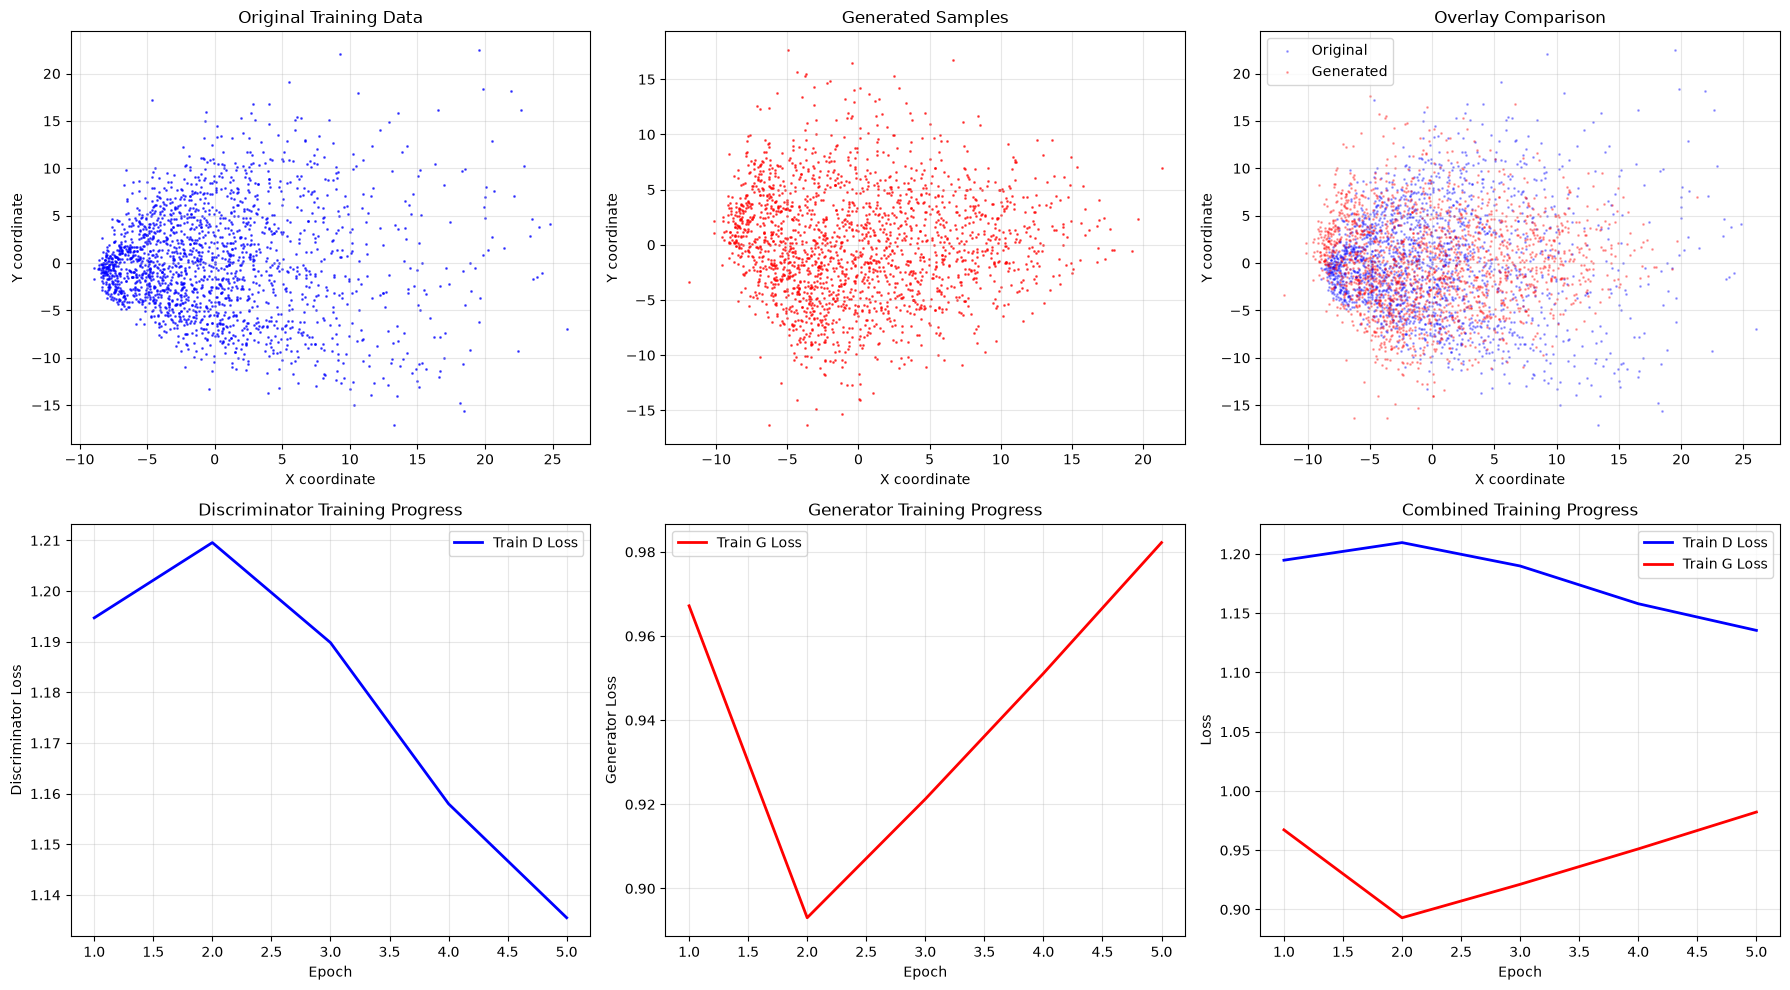

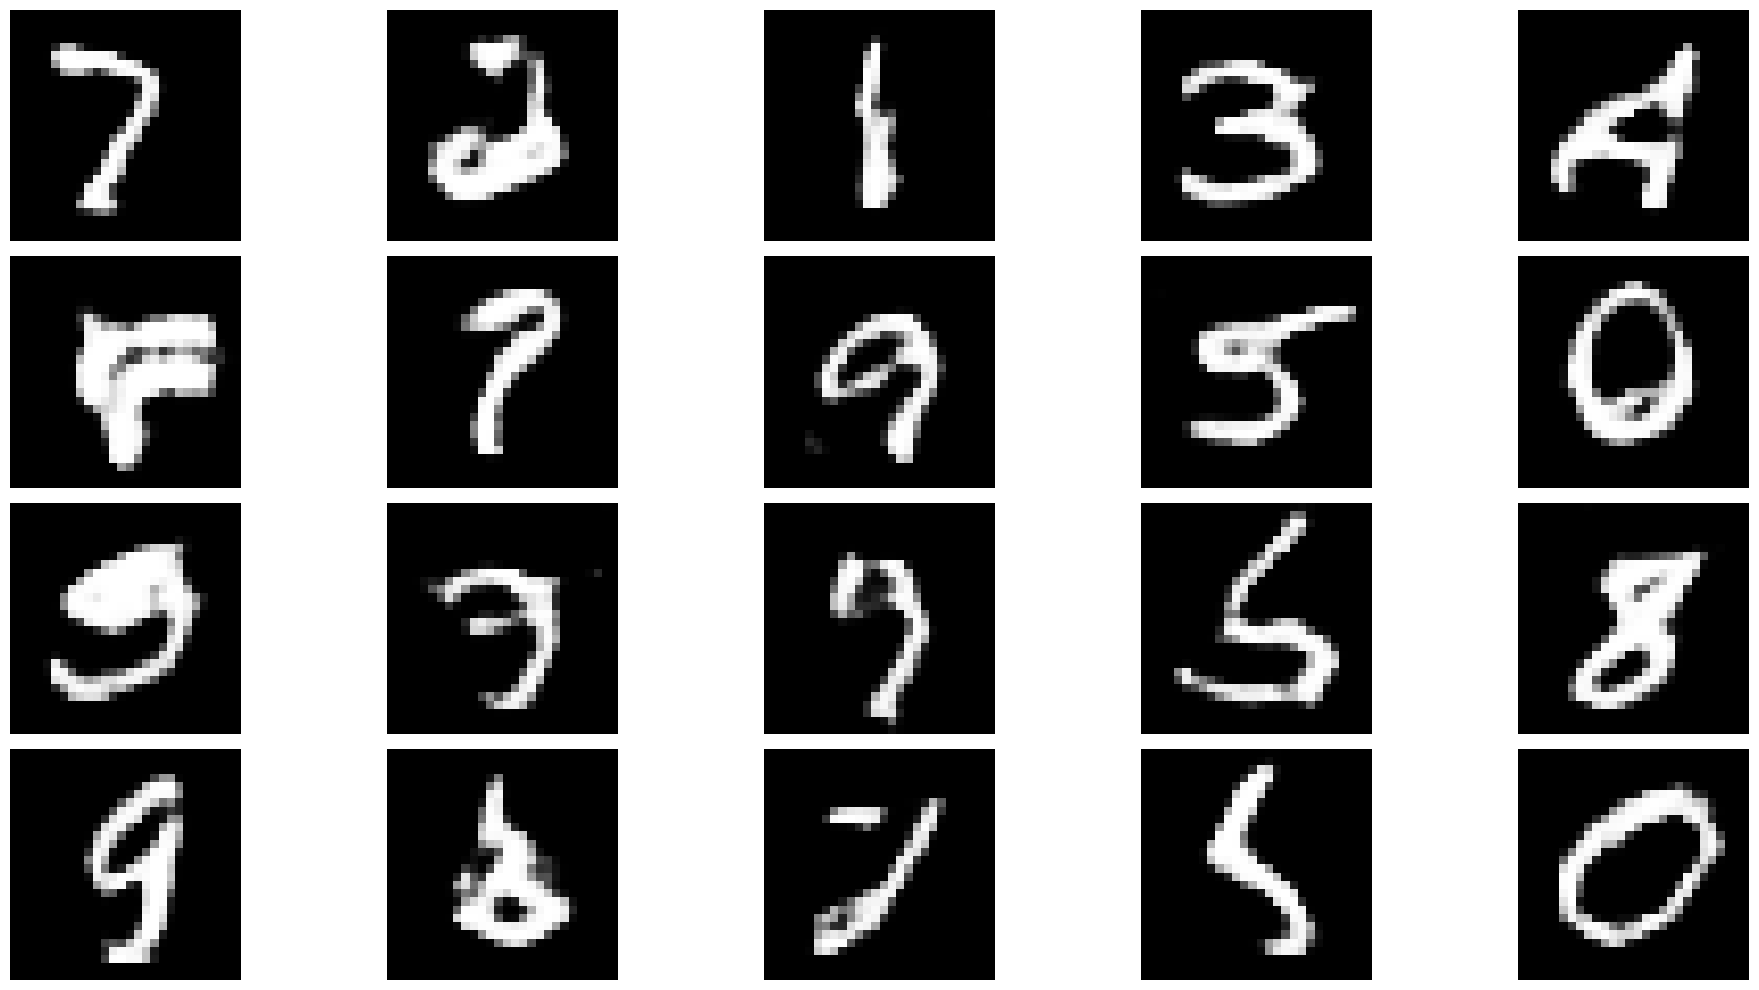

📈 Epoch 5 Summary:
   Train D Loss: 1.1355, Val D Loss: 1.2680
   Train G Loss: 0.9822, Val G Loss: 1.1269

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 1.087357	G_loss: 1.067087
Epoch: 6 [6400/60000 (11%)]	D_loss: 1.061397	G_loss: 1.017489
Epoch: 6 [12800/60000 (21%)]	D_loss: 1.126751	G_loss: 1.237501
Epoch: 6 [19200/60000 (32%)]	D_loss: 1.066519	G_loss: 0.941951
Epoch: 6 [25600/60000 (43%)]	D_loss: 1.090389	G_loss: 1.184062
Epoch: 6 [32000/60000 (53%)]	D_loss: 1.056391	G_loss: 1.108382
Epoch: 6 [38400/60000 (64%)]	D_loss: 1.145011	G_loss: 1.773958
Epoch: 6 [44800/60000 (75%)]	D_loss: 0.980374	G_loss: 0.807888
Epoch: 6 [51200/60000 (85%)]	D_loss: 1.472504	G_loss: 1.591113
Epoch: 6 [57600/60000 (96%)]	D_loss: 1.058778	G_loss: 0.822649
====> Epoch: 6 Train D_loss: 1.1080, Train G_loss: 1.0146
====> Epoch: 6 Val D_loss: 1.3337, Val G_loss: 0.4966
📈 Epoch 6 Summary:
   Train D Loss: 1.1080, Val D Loss: 1.3337
   Train G Loss: 1.0146, Val G Loss: 0

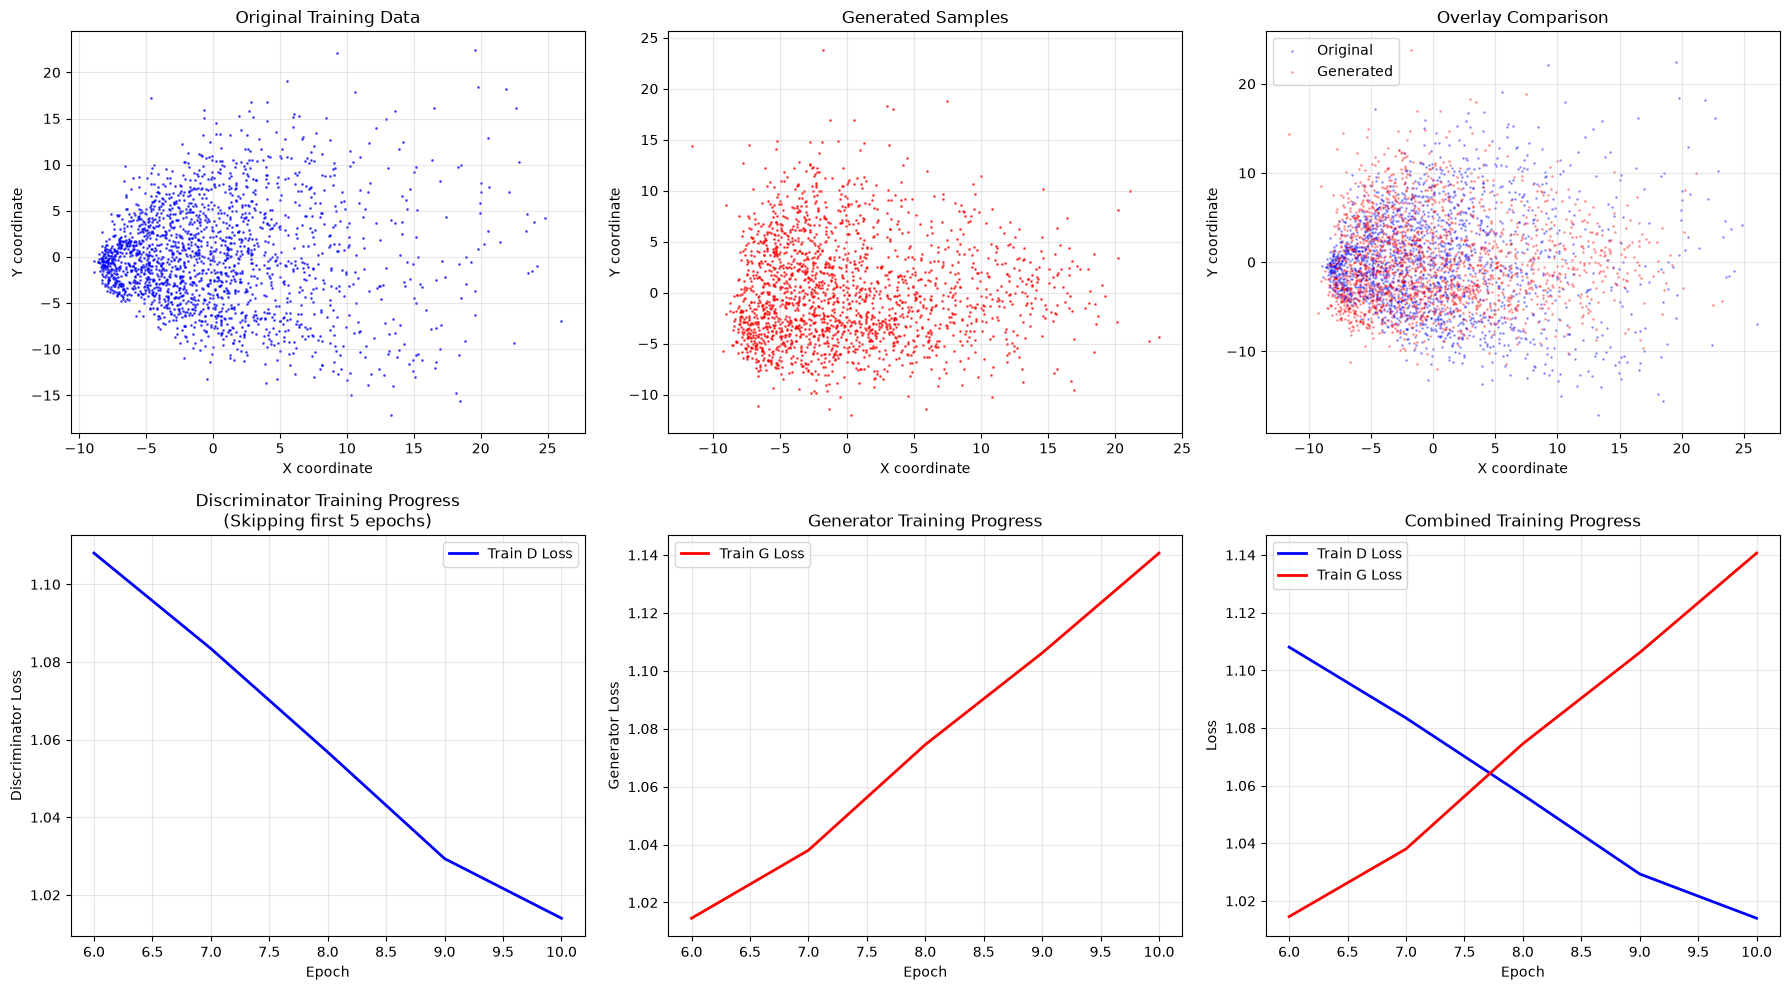

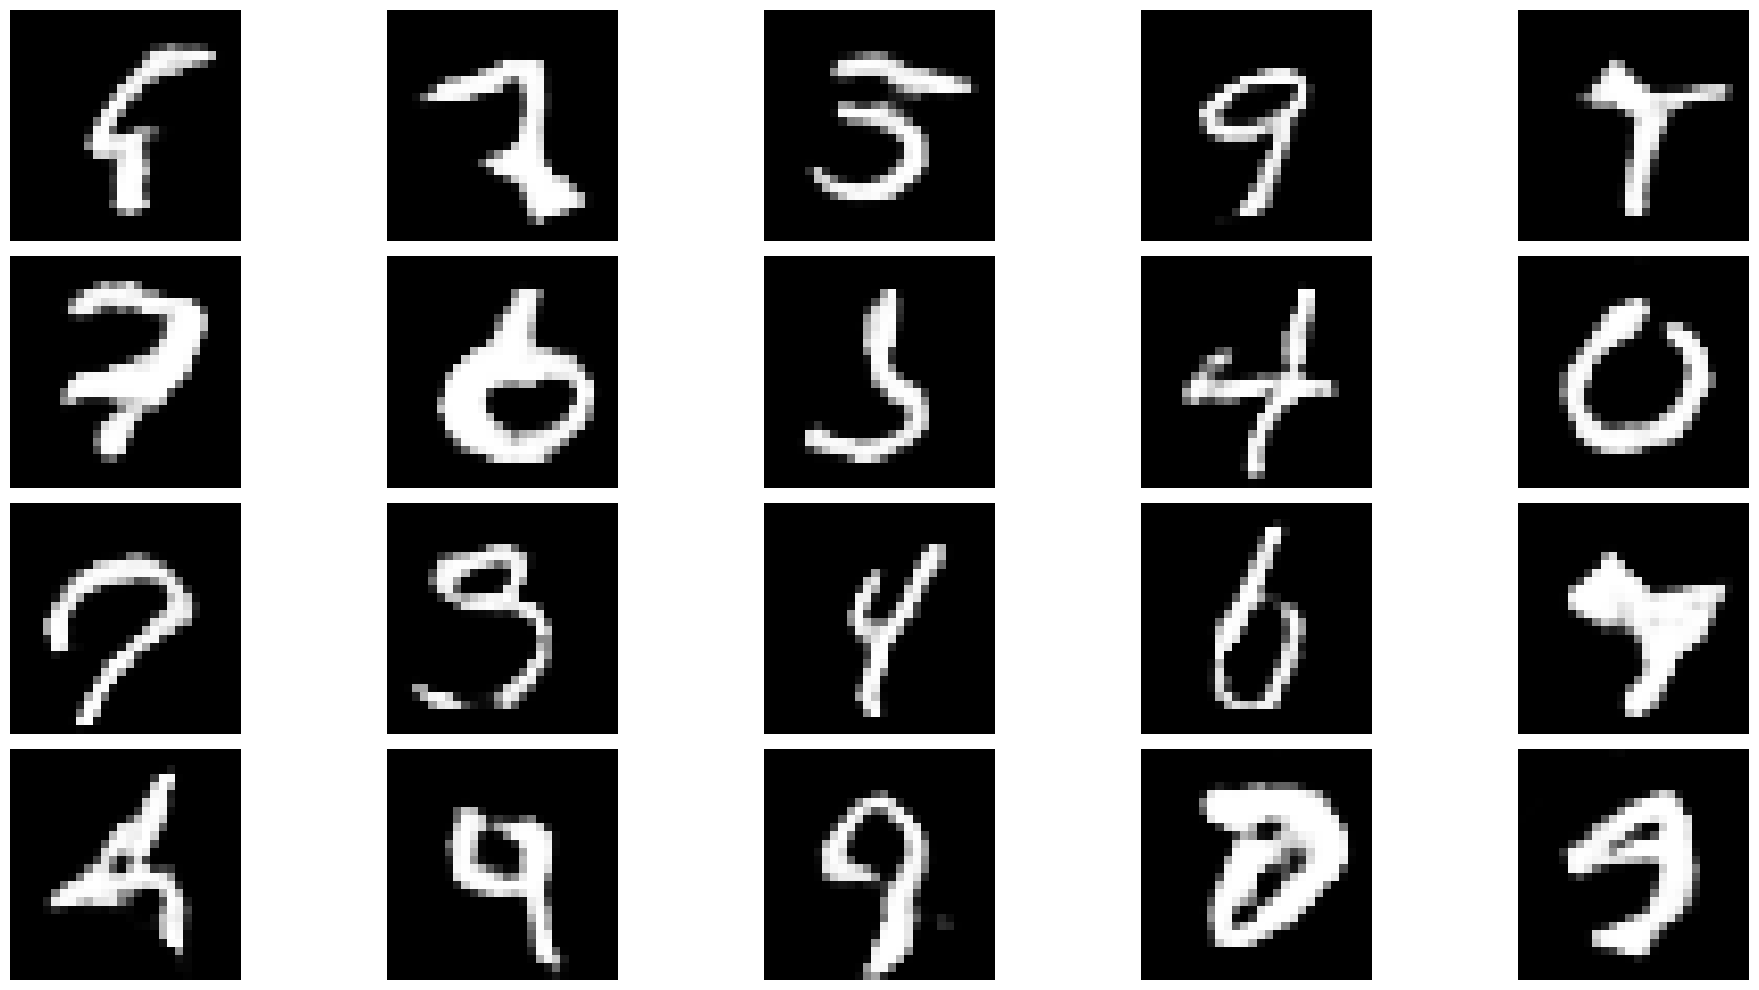

📈 Epoch 10 Summary:
   Train D Loss: 1.0140, Val D Loss: 1.1067
   Train G Loss: 1.1407, Val G Loss: 1.0993

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 1.002722	G_loss: 0.704002
Epoch: 11 [6400/60000 (11%)]	D_loss: 0.912743	G_loss: 1.622938
Epoch: 11 [12800/60000 (21%)]	D_loss: 0.938883	G_loss: 0.936670
Epoch: 11 [19200/60000 (32%)]	D_loss: 1.107738	G_loss: 1.215406
Epoch: 11 [25600/60000 (43%)]	D_loss: 0.892977	G_loss: 1.415488
Epoch: 11 [32000/60000 (53%)]	D_loss: 0.923736	G_loss: 1.226578
Epoch: 11 [38400/60000 (64%)]	D_loss: 0.984201	G_loss: 1.561262
Epoch: 11 [44800/60000 (75%)]	D_loss: 1.138100	G_loss: 0.533166
Epoch: 11 [51200/60000 (85%)]	D_loss: 1.040228	G_loss: 1.905099
Epoch: 11 [57600/60000 (96%)]	D_loss: 0.916546	G_loss: 1.304600
====> Epoch: 11 Train D_loss: 0.9931, Train G_loss: 1.1741
====> Epoch: 11 Val D_loss: 1.2702, Val G_loss: 0.5455
📈 Epoch 11 Summary:
   Train D Loss: 0.9931, Val D Loss: 1.2702
   Train G Loss: 1.1741

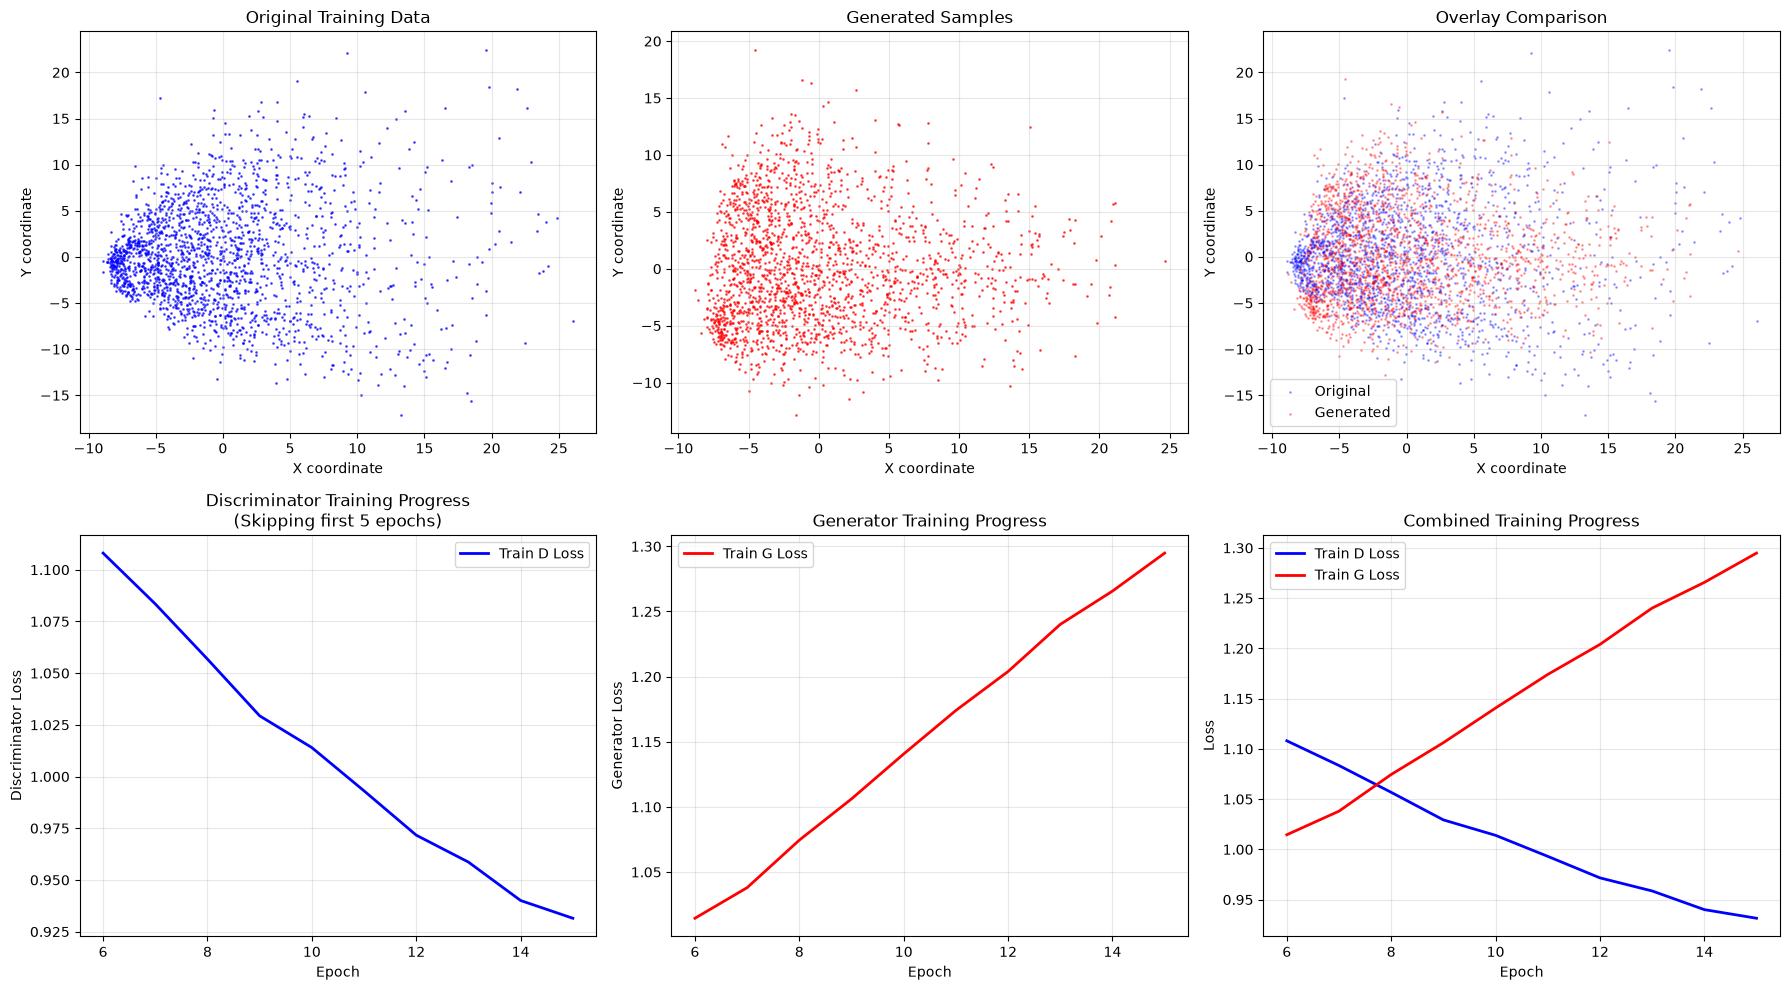

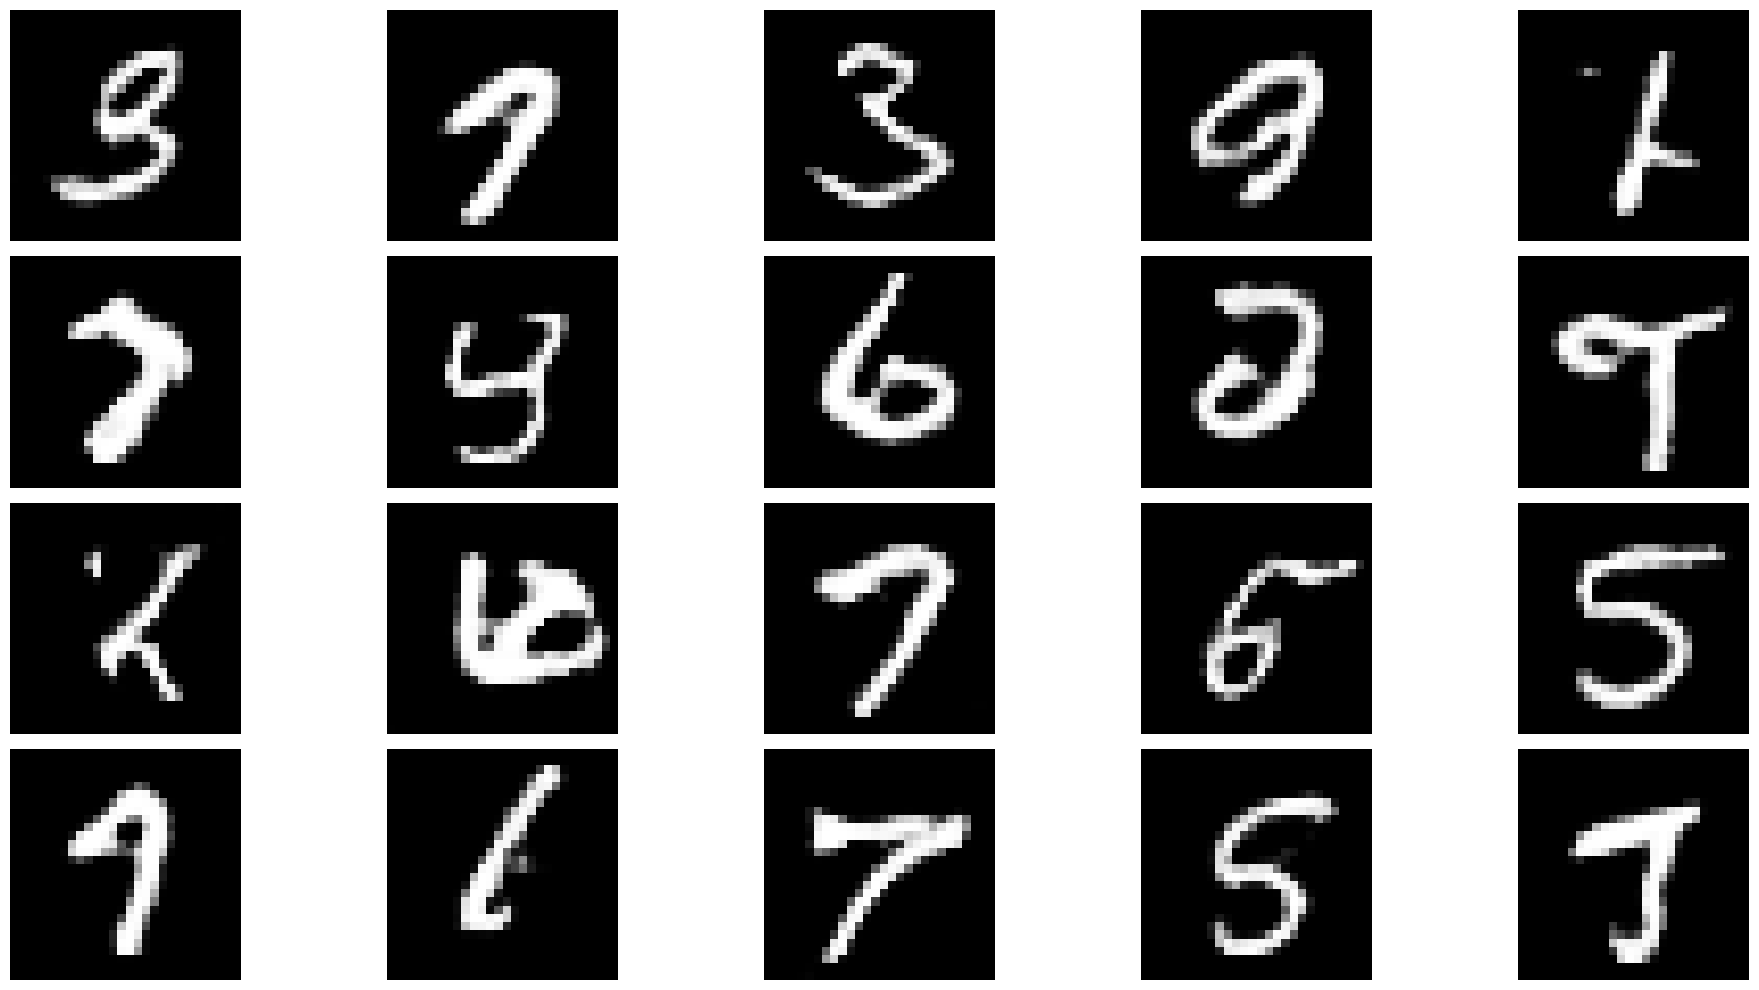

📈 Epoch 15 Summary:
   Train D Loss: 0.9315, Val D Loss: 1.3279
   Train G Loss: 1.2948, Val G Loss: 1.9244

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 0.892891	G_loss: 1.663201
Epoch: 16 [6400/60000 (11%)]	D_loss: 0.843301	G_loss: 1.105878
Epoch: 16 [12800/60000 (21%)]	D_loss: 0.911831	G_loss: 0.962947
Epoch: 16 [19200/60000 (32%)]	D_loss: 1.165568	G_loss: 0.416273
Epoch: 16 [25600/60000 (43%)]	D_loss: 0.843243	G_loss: 1.443812
Epoch: 16 [32000/60000 (53%)]	D_loss: 1.250352	G_loss: 1.643132
Epoch: 16 [38400/60000 (64%)]	D_loss: 0.831334	G_loss: 1.643524
Epoch: 16 [44800/60000 (75%)]	D_loss: 0.934695	G_loss: 1.261139
Epoch: 16 [51200/60000 (85%)]	D_loss: 0.949032	G_loss: 1.549053
Epoch: 16 [57600/60000 (96%)]	D_loss: 0.927890	G_loss: 2.247328
====> Epoch: 16 Train D_loss: 0.9154, Train G_loss: 1.3159
====> Epoch: 16 Val D_loss: 1.1954, Val G_loss: 1.5471
📈 Epoch 16 Summary:
   Train D Loss: 0.9154, Val D Loss: 1.1954
   Train G Loss: 1.3159

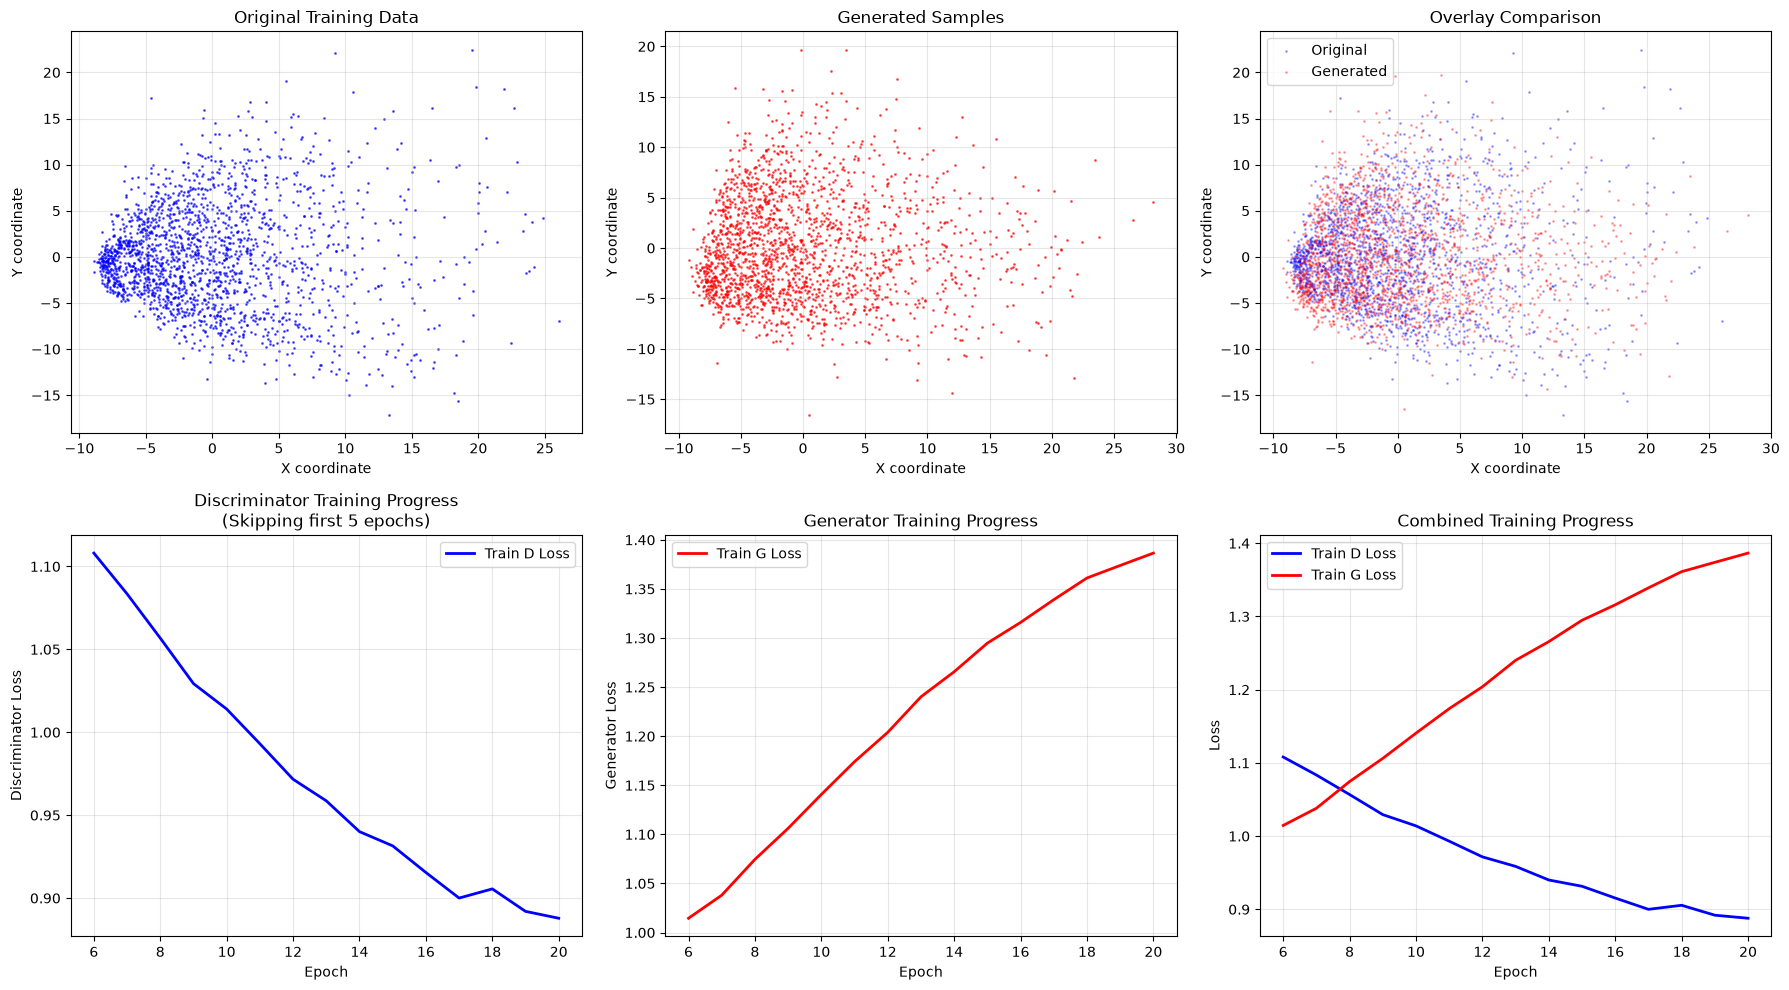

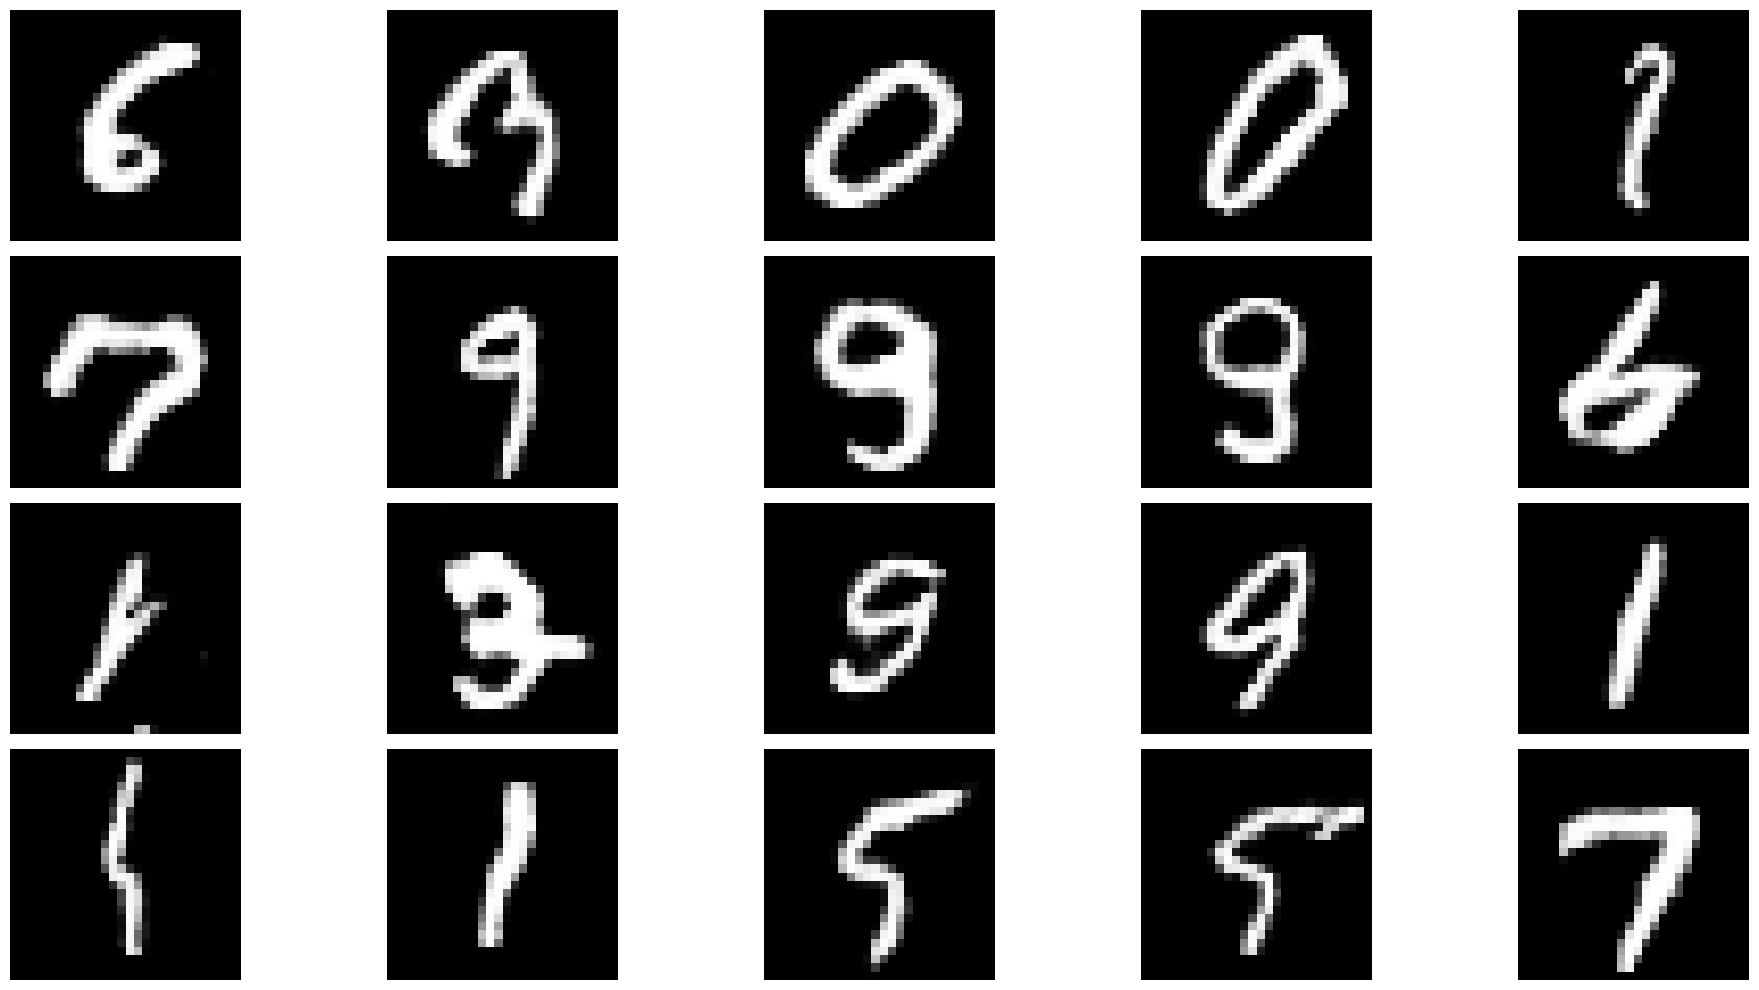

📈 Epoch 20 Summary:
   Train D Loss: 0.8878, Val D Loss: 1.2038
   Train G Loss: 1.3865, Val G Loss: 0.6705

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.894435	G_loss: 2.103661
Epoch: 21 [6400/60000 (11%)]	D_loss: 0.867159	G_loss: 0.853198
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.823839	G_loss: 1.087731
Epoch: 21 [19200/60000 (32%)]	D_loss: 0.894230	G_loss: 2.266629
Epoch: 21 [25600/60000 (43%)]	D_loss: 0.780347	G_loss: 1.117979
Epoch: 21 [32000/60000 (53%)]	D_loss: 1.144958	G_loss: 0.645020
Epoch: 21 [38400/60000 (64%)]	D_loss: 0.855686	G_loss: 1.435455
Epoch: 21 [44800/60000 (75%)]	D_loss: 0.814168	G_loss: 1.346081
Epoch: 21 [51200/60000 (85%)]	D_loss: 0.966394	G_loss: 1.935822
Epoch: 21 [57600/60000 (96%)]	D_loss: 0.814459	G_loss: 1.376816
====> Epoch: 21 Train D_loss: 0.8749, Train G_loss: 1.3961
====> Epoch: 21 Val D_loss: 1.0765, Val G_loss: 0.9489
📈 Epoch 21 Summary:
   Train D Loss: 0.8749, Val D Loss: 1.0765
   Train G Loss: 1.3961

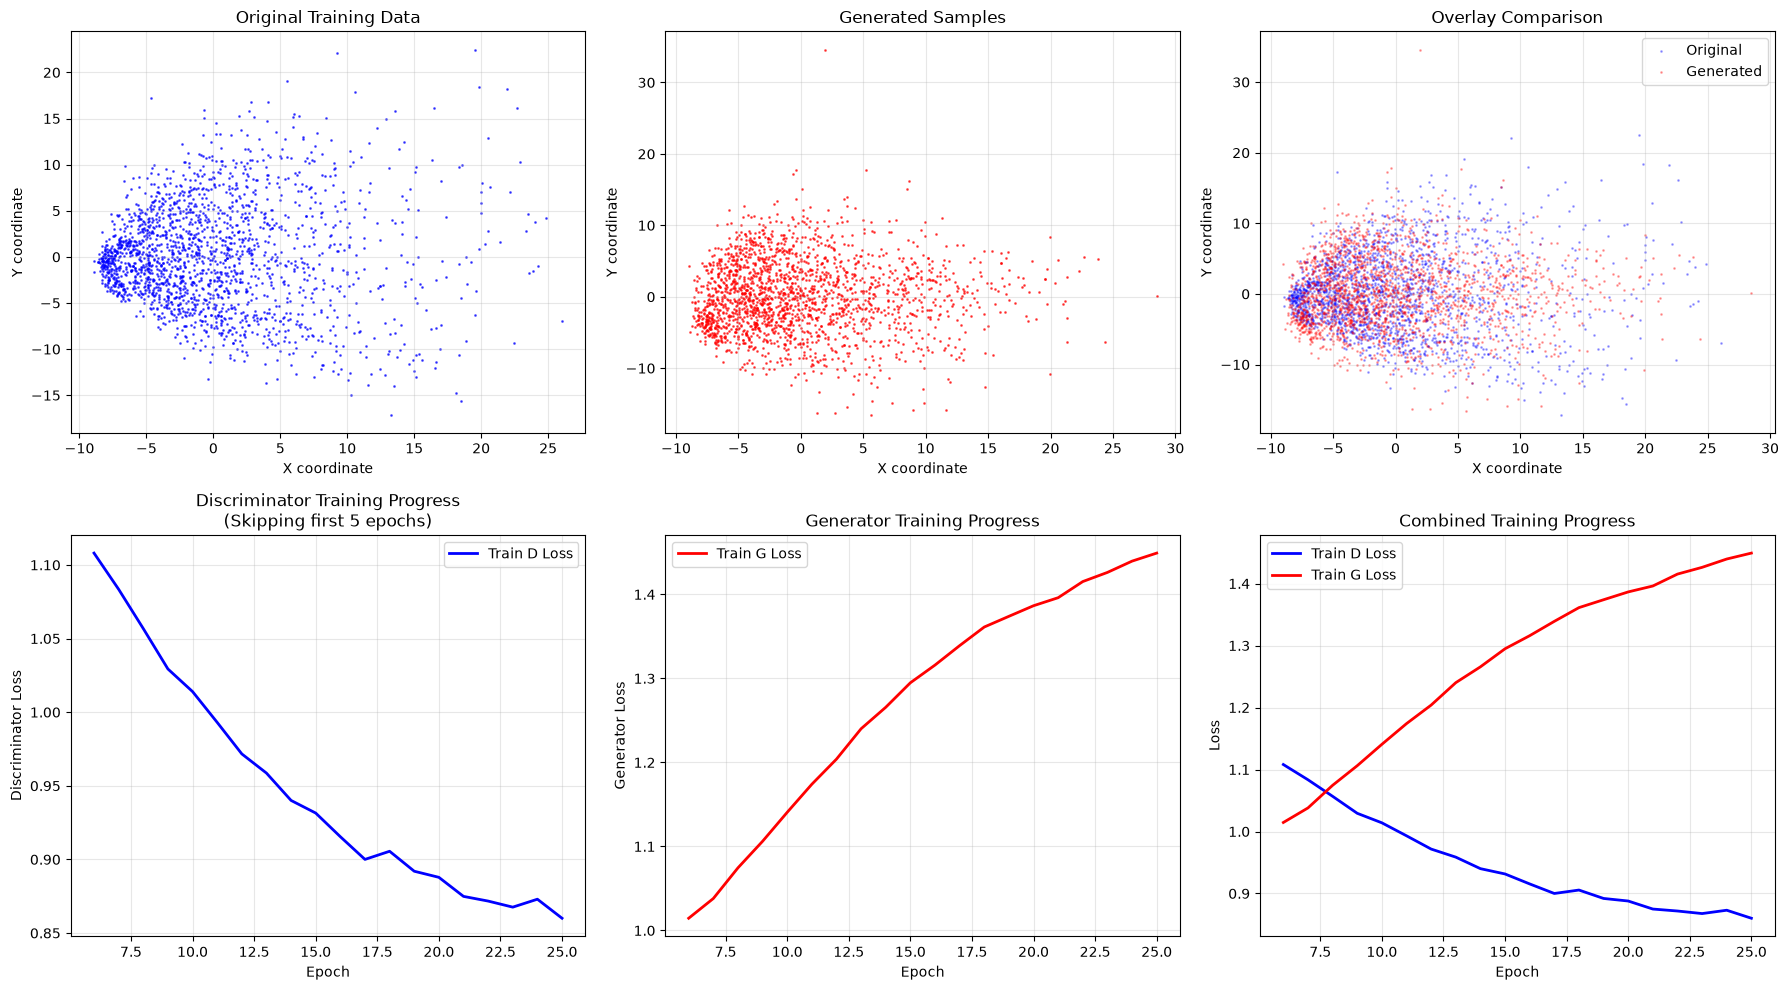

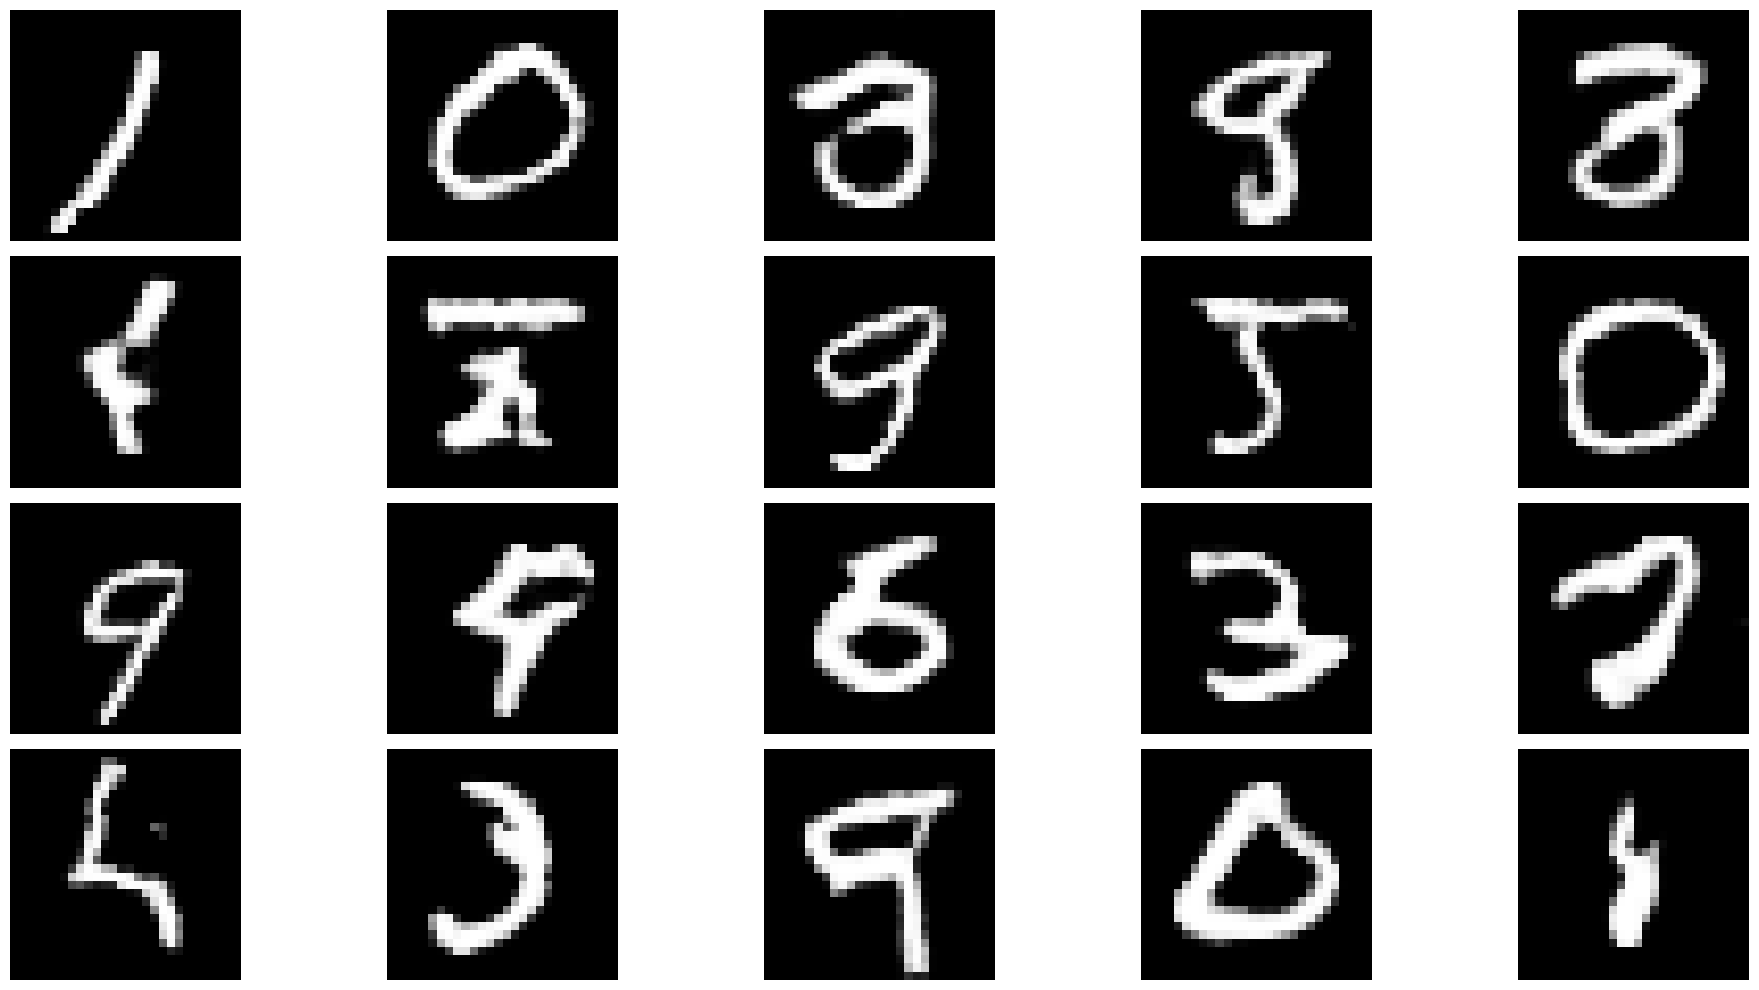

📈 Epoch 25 Summary:
   Train D Loss: 0.8601, Val D Loss: 1.2553
   Train G Loss: 1.4492, Val G Loss: 0.5846

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.937012	G_loss: 2.327381
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.909701	G_loss: 0.658660
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.989794	G_loss: 2.190228
Epoch: 26 [19200/60000 (32%)]	D_loss: 0.689141	G_loss: 1.833777
Epoch: 26 [25600/60000 (43%)]	D_loss: 0.977976	G_loss: 1.085557
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.712794	G_loss: 1.615649
Epoch: 26 [38400/60000 (64%)]	D_loss: 0.730276	G_loss: 1.773110
Epoch: 26 [44800/60000 (75%)]	D_loss: 0.813510	G_loss: 1.895513
Epoch: 26 [51200/60000 (85%)]	D_loss: 0.873627	G_loss: 1.343724
Epoch: 26 [57600/60000 (96%)]	D_loss: 1.012165	G_loss: 1.964274
====> Epoch: 26 Train D_loss: 0.8708, Train G_loss: 1.4534
====> Epoch: 26 Val D_loss: 1.1220, Val G_loss: 1.5811
📈 Epoch 26 Summary:
   Train D Loss: 0.8708, Val D Loss: 1.1220
   Train G Loss: 1.4534

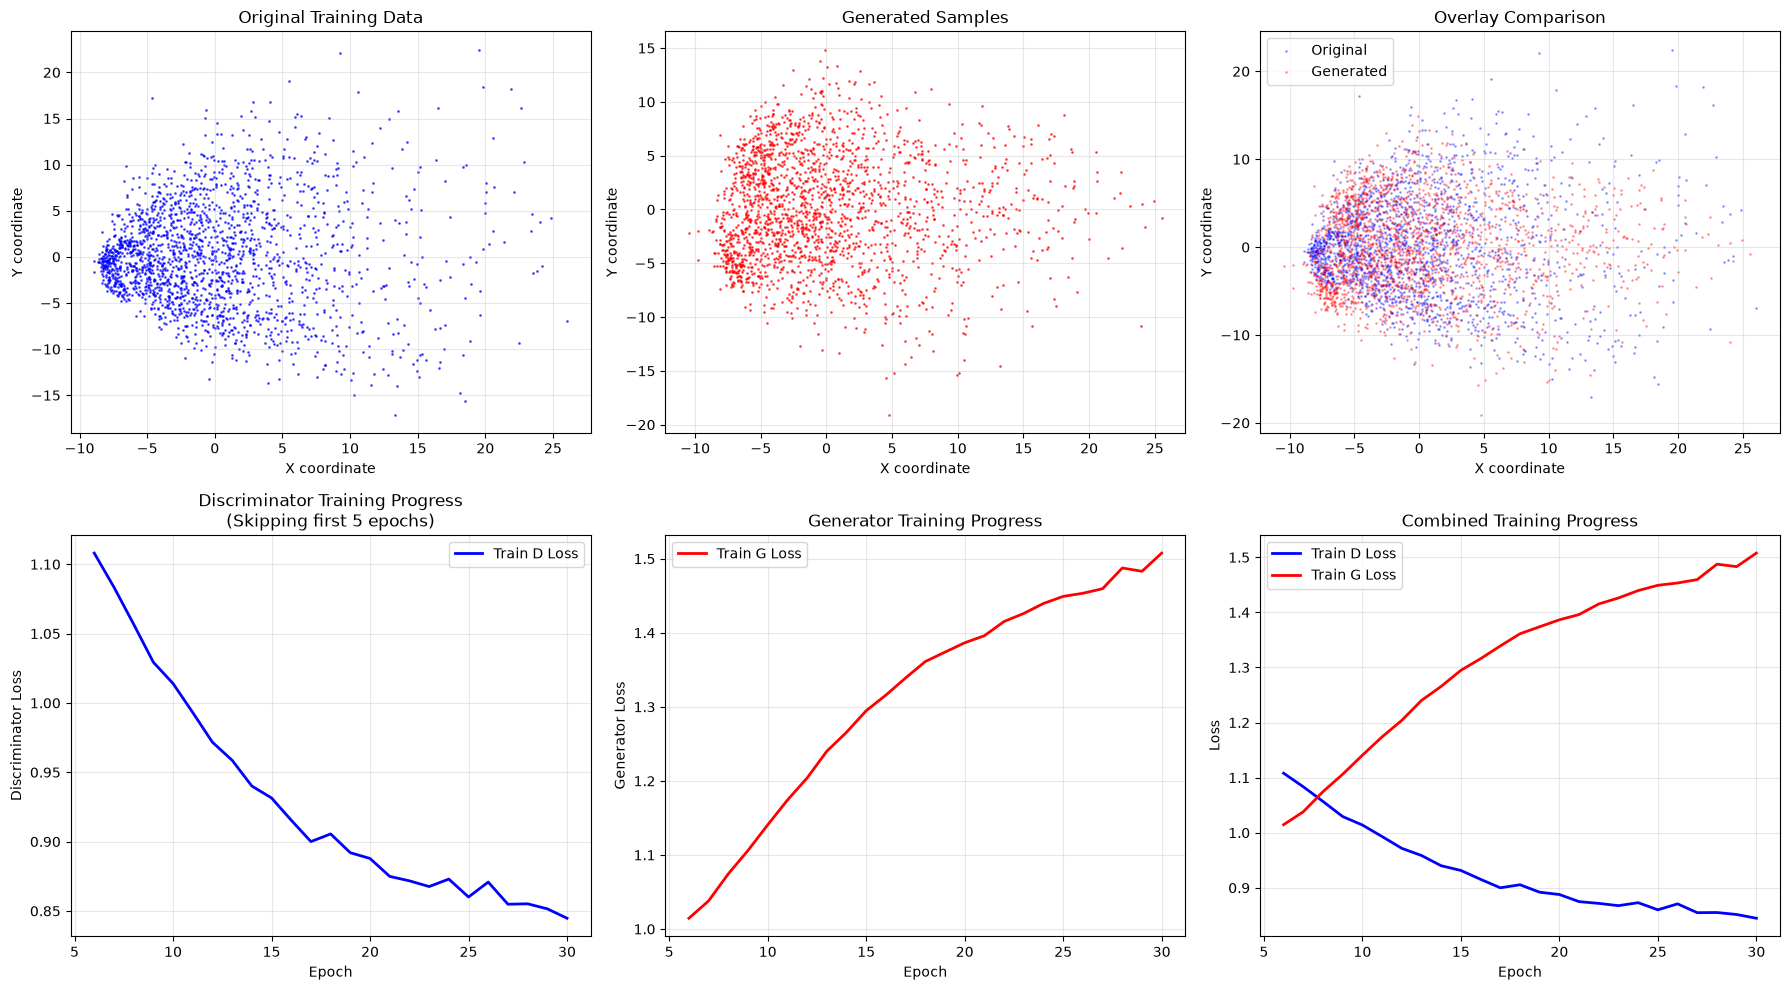

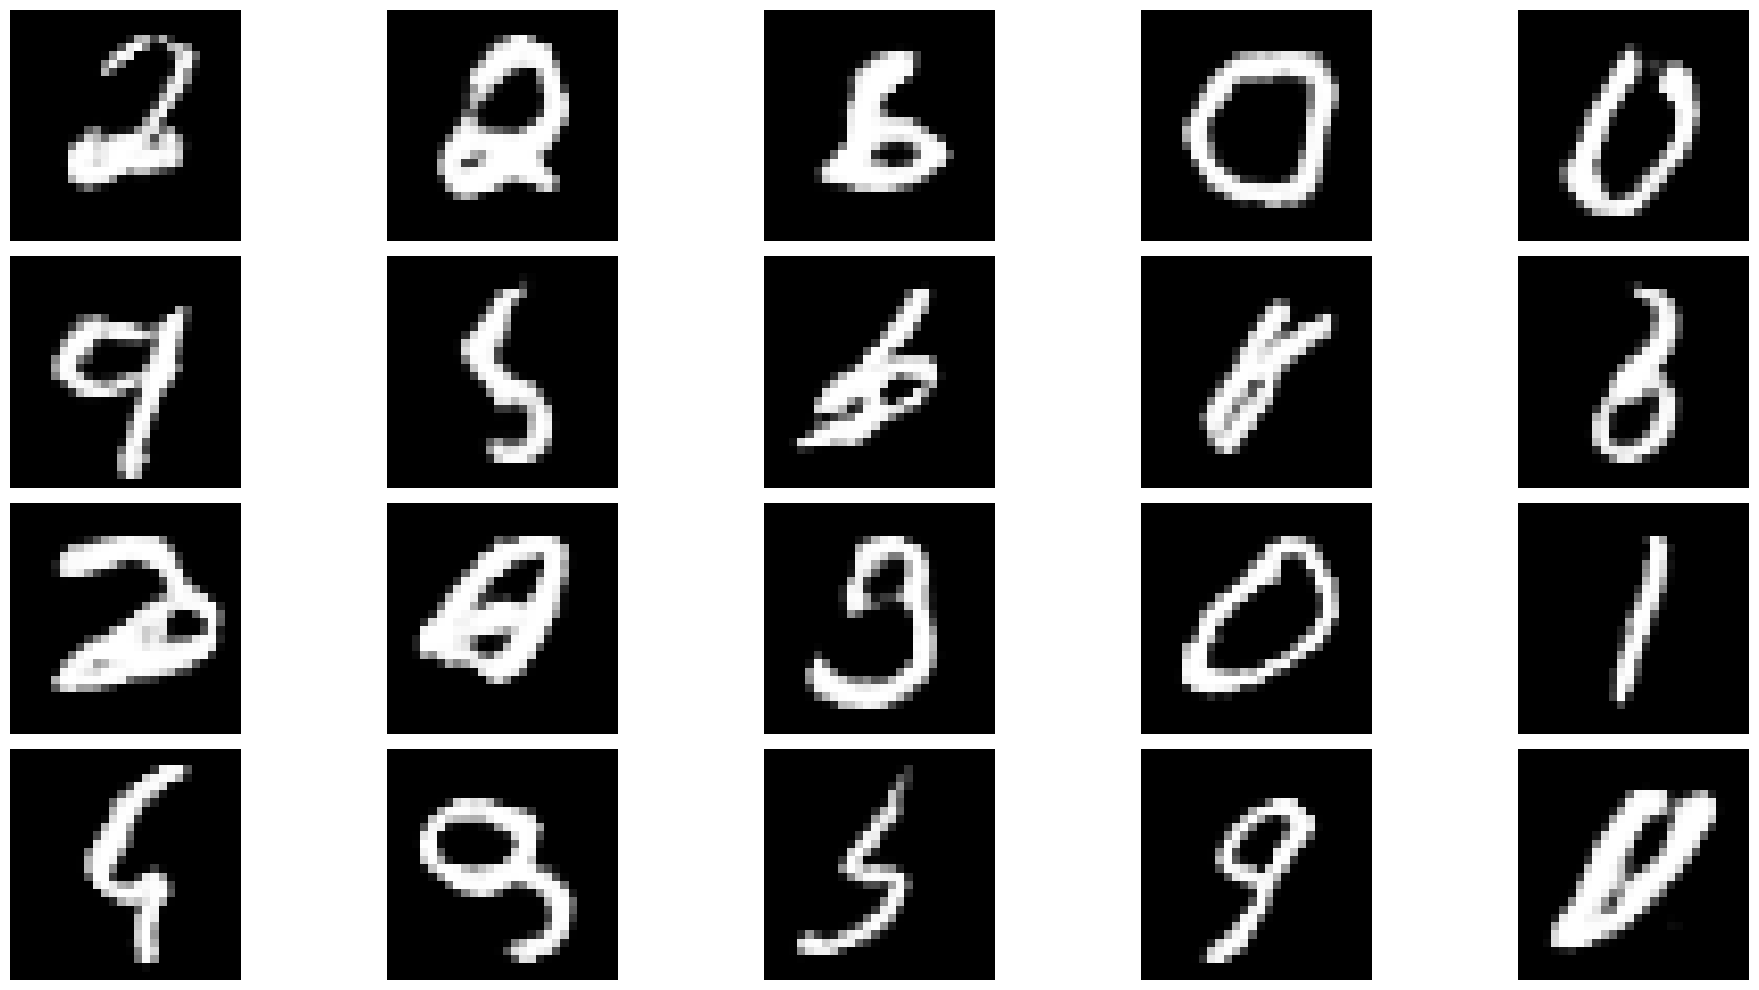

📈 Epoch 30 Summary:
   Train D Loss: 0.8448, Val D Loss: 1.0610
   Train G Loss: 1.5076, Val G Loss: 1.0560

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.888454	G_loss: 2.081072
Epoch: 31 [6400/60000 (11%)]	D_loss: 0.897345	G_loss: 1.520967
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.812547	G_loss: 1.041445
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.744000	G_loss: 1.515206
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.800310	G_loss: 1.192223
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.652887	G_loss: 1.629771
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.884351	G_loss: 1.395477
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.803716	G_loss: 1.007258
Epoch: 31 [51200/60000 (85%)]	D_loss: 1.078666	G_loss: 1.108721
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.904353	G_loss: 0.742185
====> Epoch: 31 Train D_loss: 0.8459, Train G_loss: 1.5094
====> Epoch: 31 Val D_loss: 1.0675, Val G_loss: 1.2957
📈 Epoch 31 Summary:
   Train D Loss: 0.8459, Val D Loss: 1.0675
   Train G Loss: 1.5094

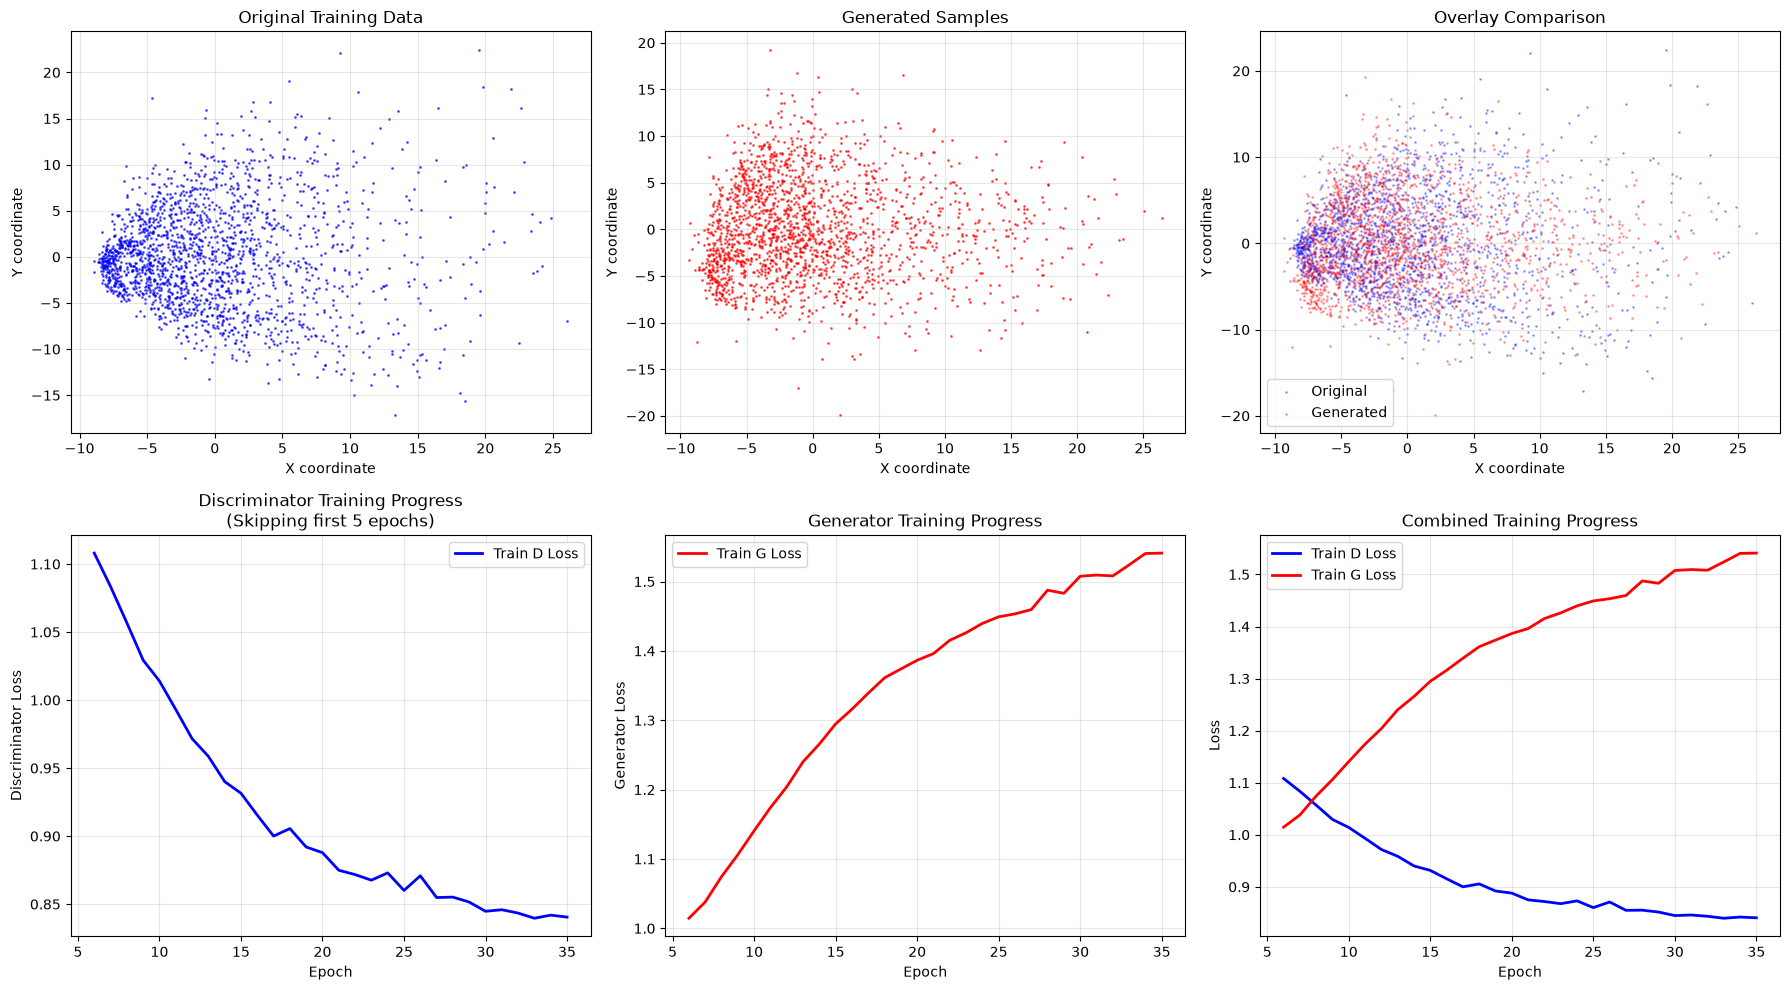

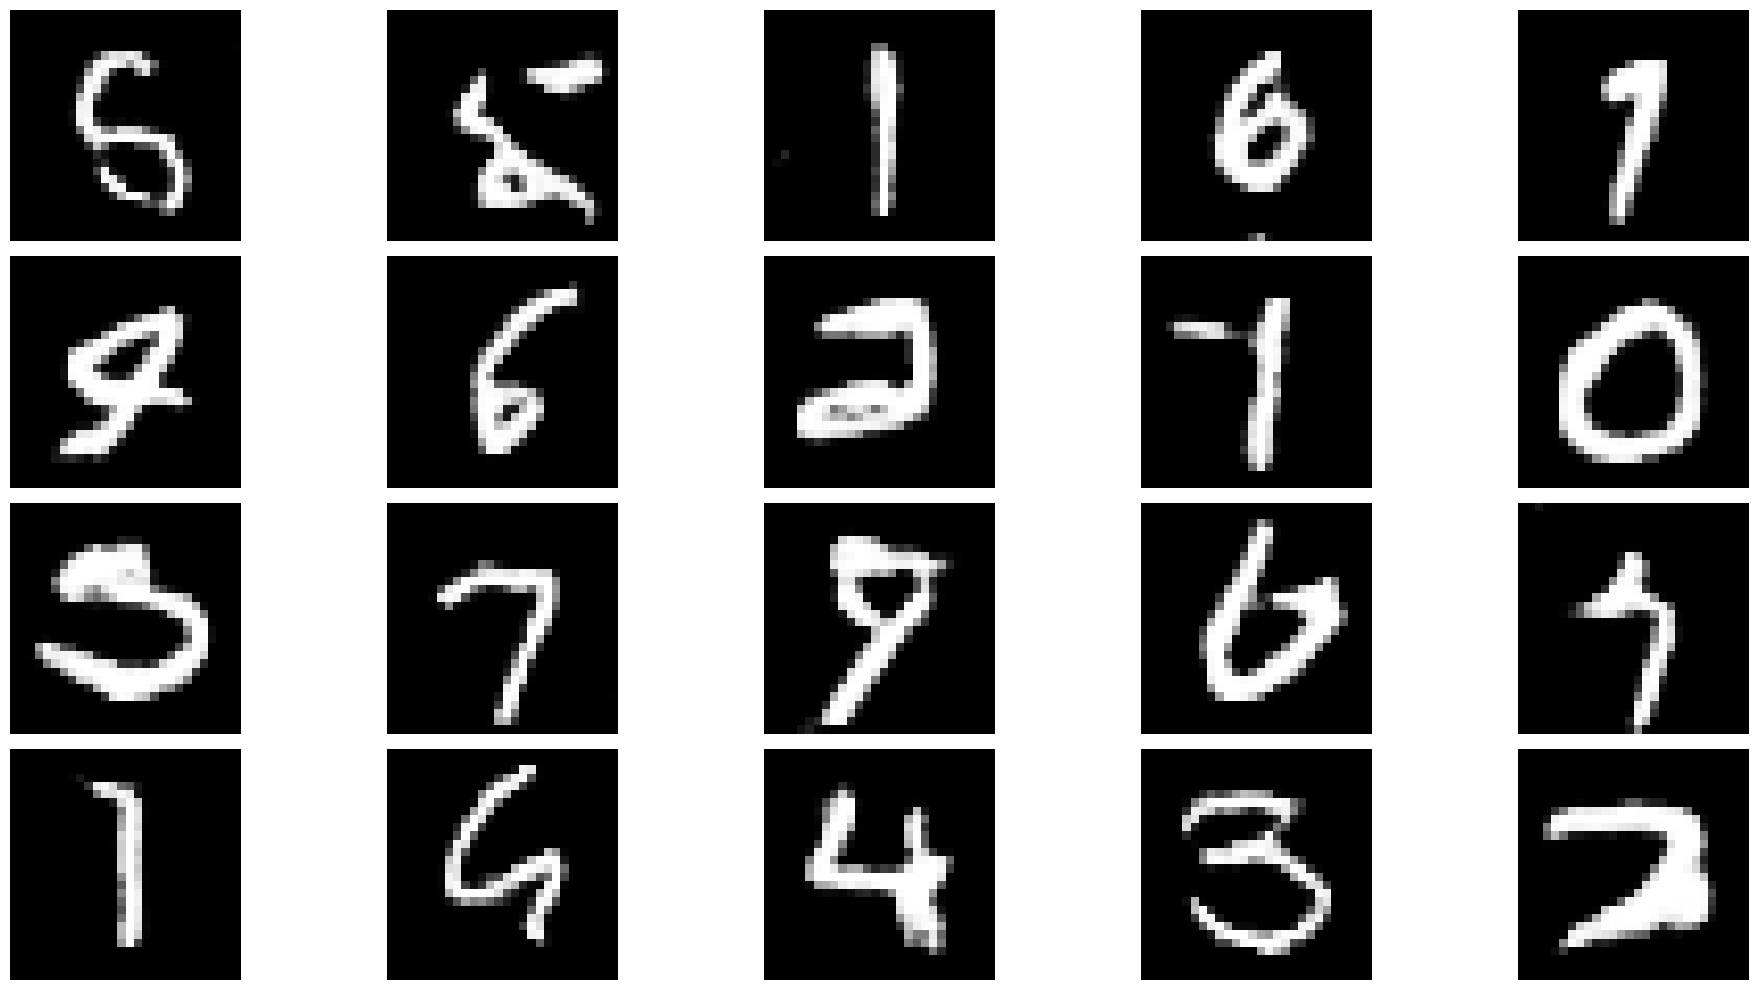

📈 Epoch 35 Summary:
   Train D Loss: 0.8405, Val D Loss: 1.2770
   Train G Loss: 1.5410, Val G Loss: 0.6037

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.926956	G_loss: 2.016067
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.831407	G_loss: 1.880133
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.828575	G_loss: 1.225029
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.958825	G_loss: 1.089787
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.762184	G_loss: 1.665736
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.890337	G_loss: 1.136040
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.761794	G_loss: 1.903752
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.775959	G_loss: 1.493746
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.784939	G_loss: 1.567912
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.913129	G_loss: 1.791702
====> Epoch: 36 Train D_loss: 0.8198, Train G_loss: 1.5462
====> Epoch: 36 Val D_loss: 1.0559, Val G_loss: 1.3722
📈 Epoch 36 Summary:
   Train D Loss: 0.8198, Val D Loss: 1.0559
   Train G Loss: 1.5462

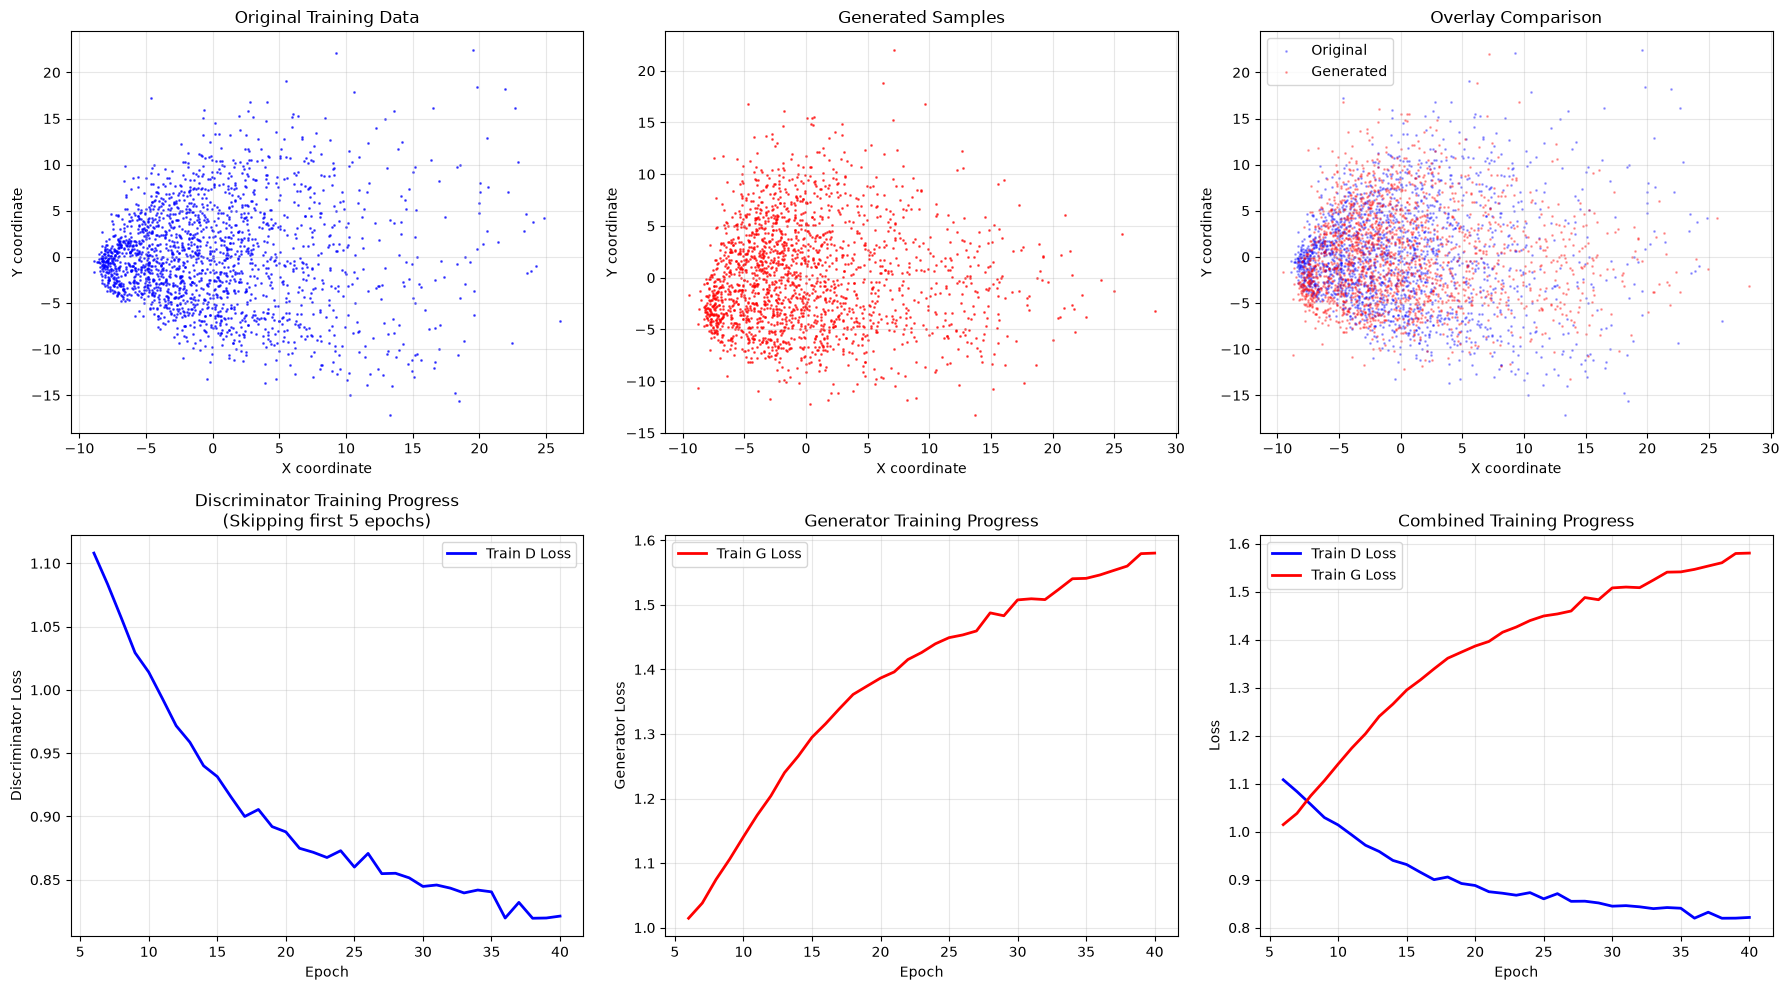

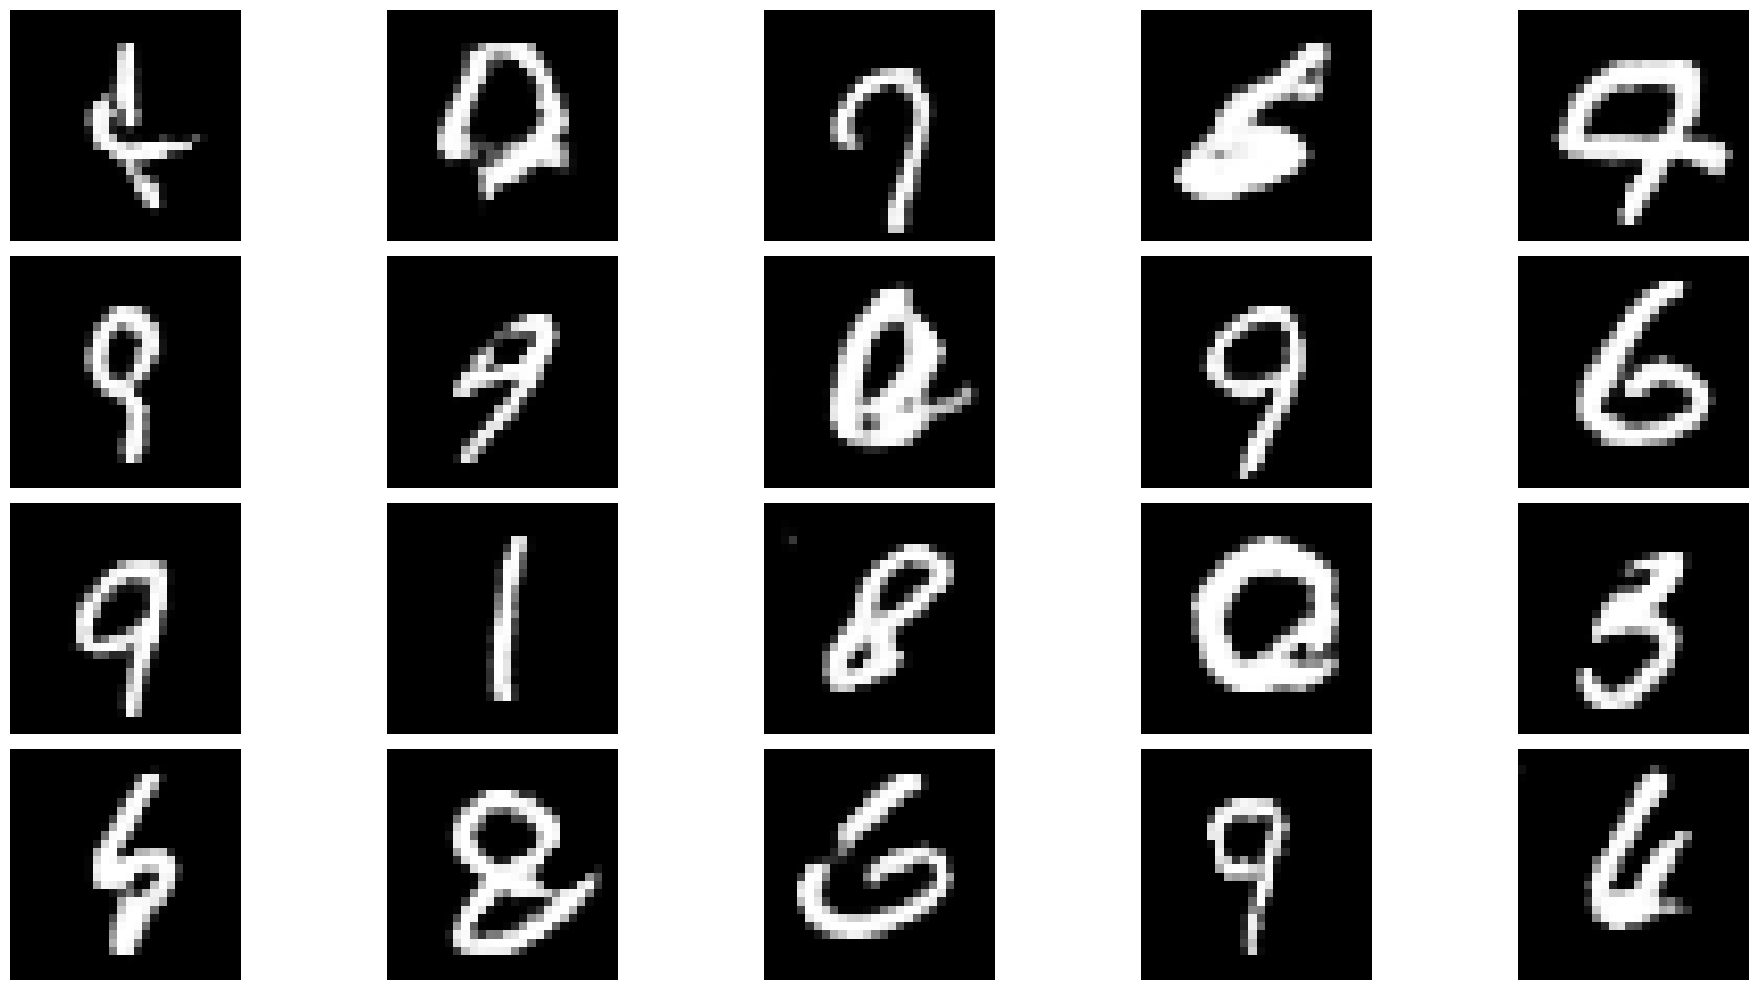

📈 Epoch 40 Summary:
   Train D Loss: 0.8213, Val D Loss: 1.0895
   Train G Loss: 1.5801, Val G Loss: 0.9133

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.781476	G_loss: 2.419213
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.865322	G_loss: 0.911017
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.736542	G_loss: 1.555113
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.761163	G_loss: 1.661701
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.736922	G_loss: 1.474723
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.685778	G_loss: 1.482472
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.764017	G_loss: 1.724133
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.775436	G_loss: 1.504844
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.710202	G_loss: 1.614272
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.816517	G_loss: 1.663312
====> Epoch: 41 Train D_loss: 0.8135, Train G_loss: 1.5946
====> Epoch: 41 Val D_loss: 1.2930, Val G_loss: 0.6252
📈 Epoch 41 Summary:
   Train D Loss: 0.8135, Val D Loss: 1.2930
   Train G Loss: 1.5946

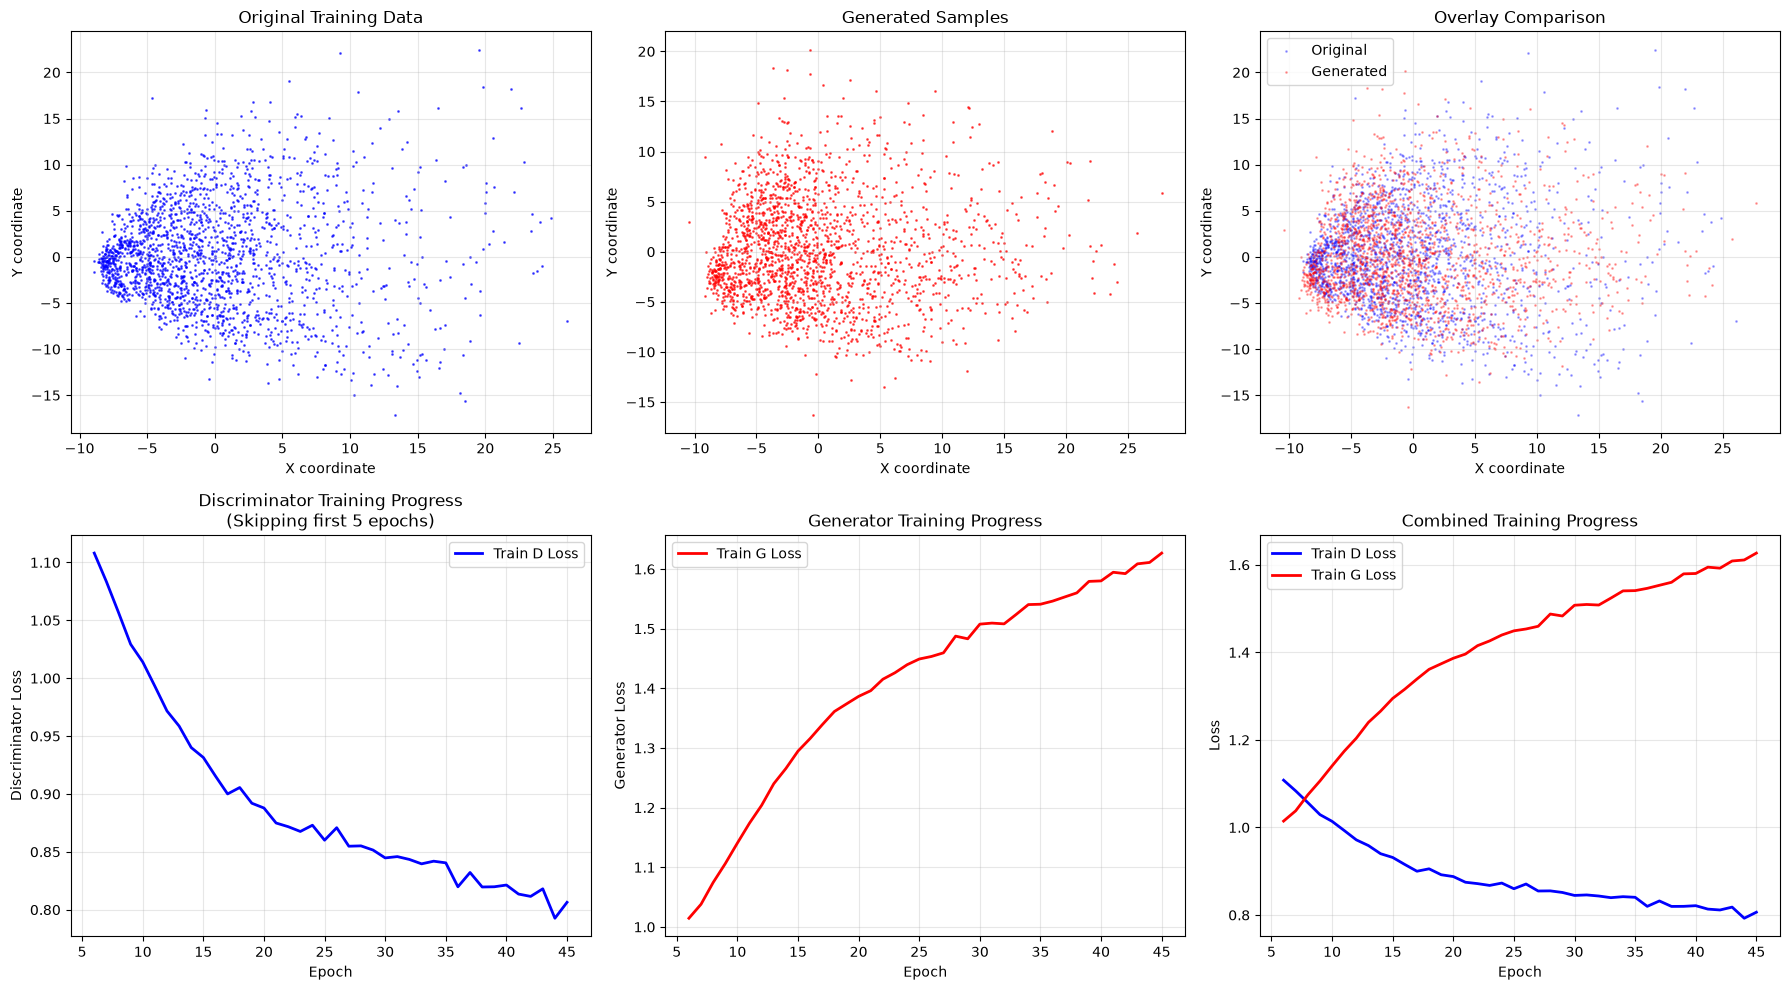

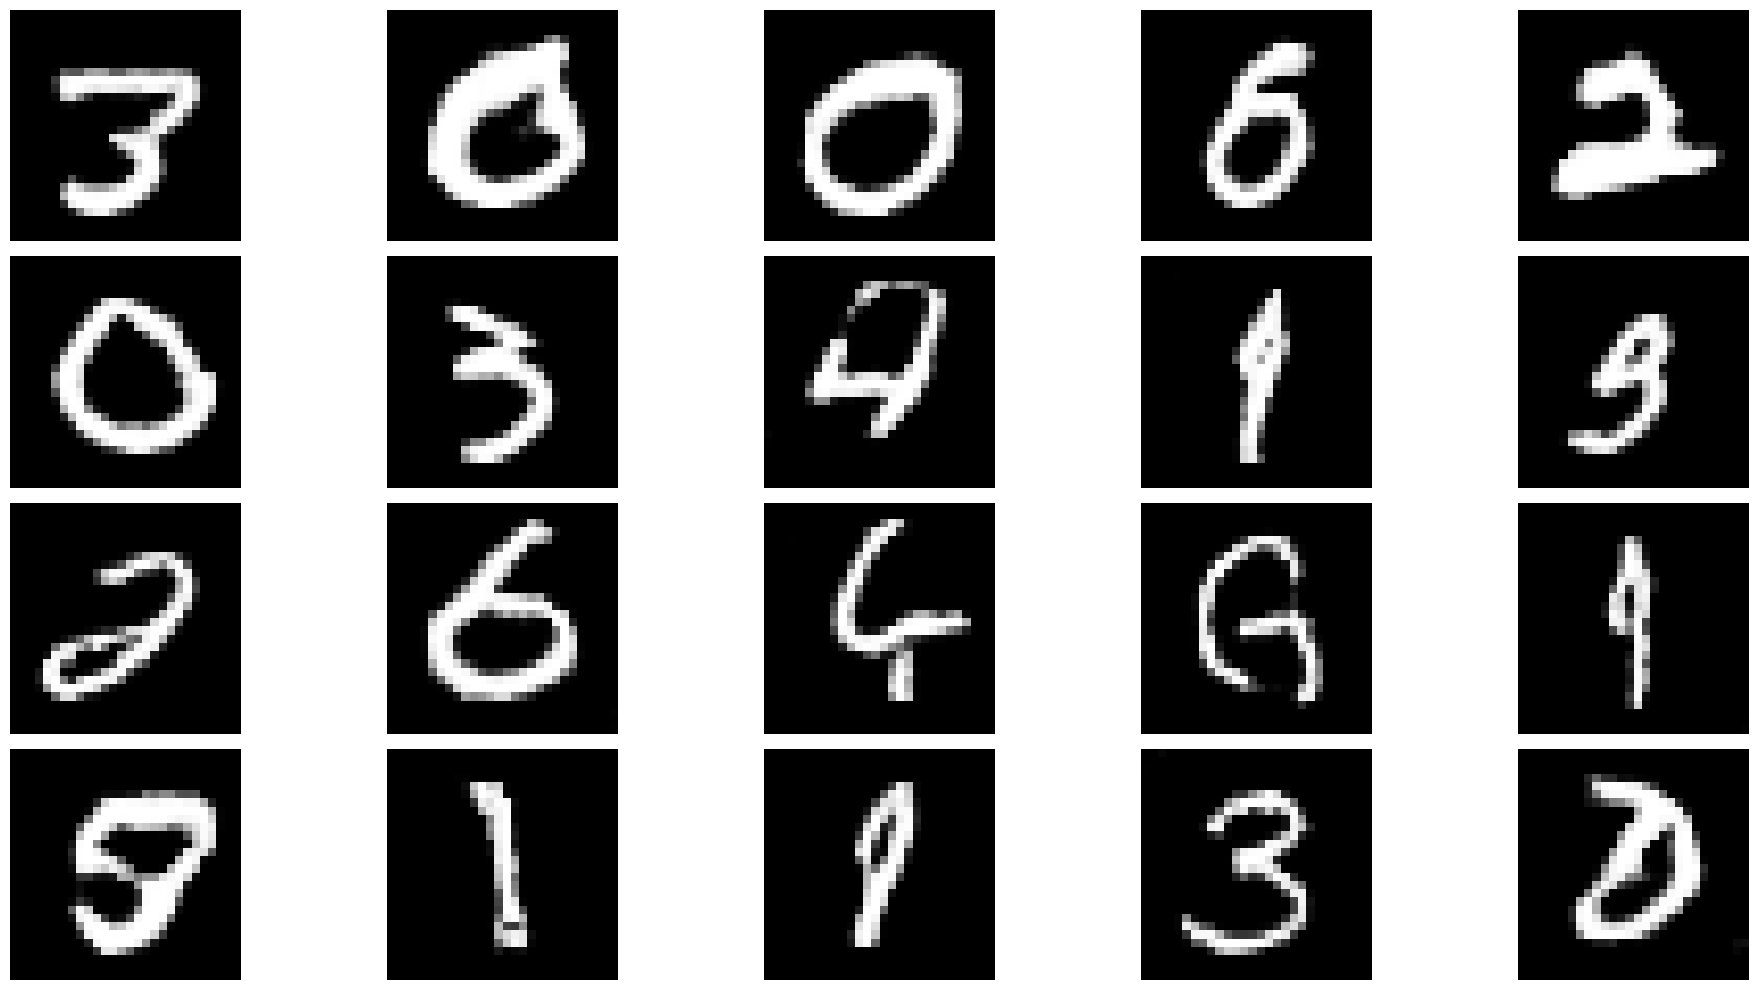

📈 Epoch 45 Summary:
   Train D Loss: 0.8064, Val D Loss: 1.1369
   Train G Loss: 1.6267, Val G Loss: 0.8710

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.758478	G_loss: 1.535680
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.761582	G_loss: 0.903603
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.687987	G_loss: 1.089953
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.693457	G_loss: 1.588078
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.641255	G_loss: 1.966318
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.787952	G_loss: 2.077649
Epoch: 46 [38400/60000 (64%)]	D_loss: 0.673787	G_loss: 1.972294
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.641265	G_loss: 1.839654
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.750259	G_loss: 1.282218
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.713070	G_loss: 1.685928
====> Epoch: 46 Train D_loss: 0.7977, Train G_loss: 1.6331
====> Epoch: 46 Val D_loss: 1.3786, Val G_loss: 2.2322
📈 Epoch 46 Summary:
   Train D Loss: 0.7977, Val D Loss: 1.3786
   Train G Loss: 1.6331

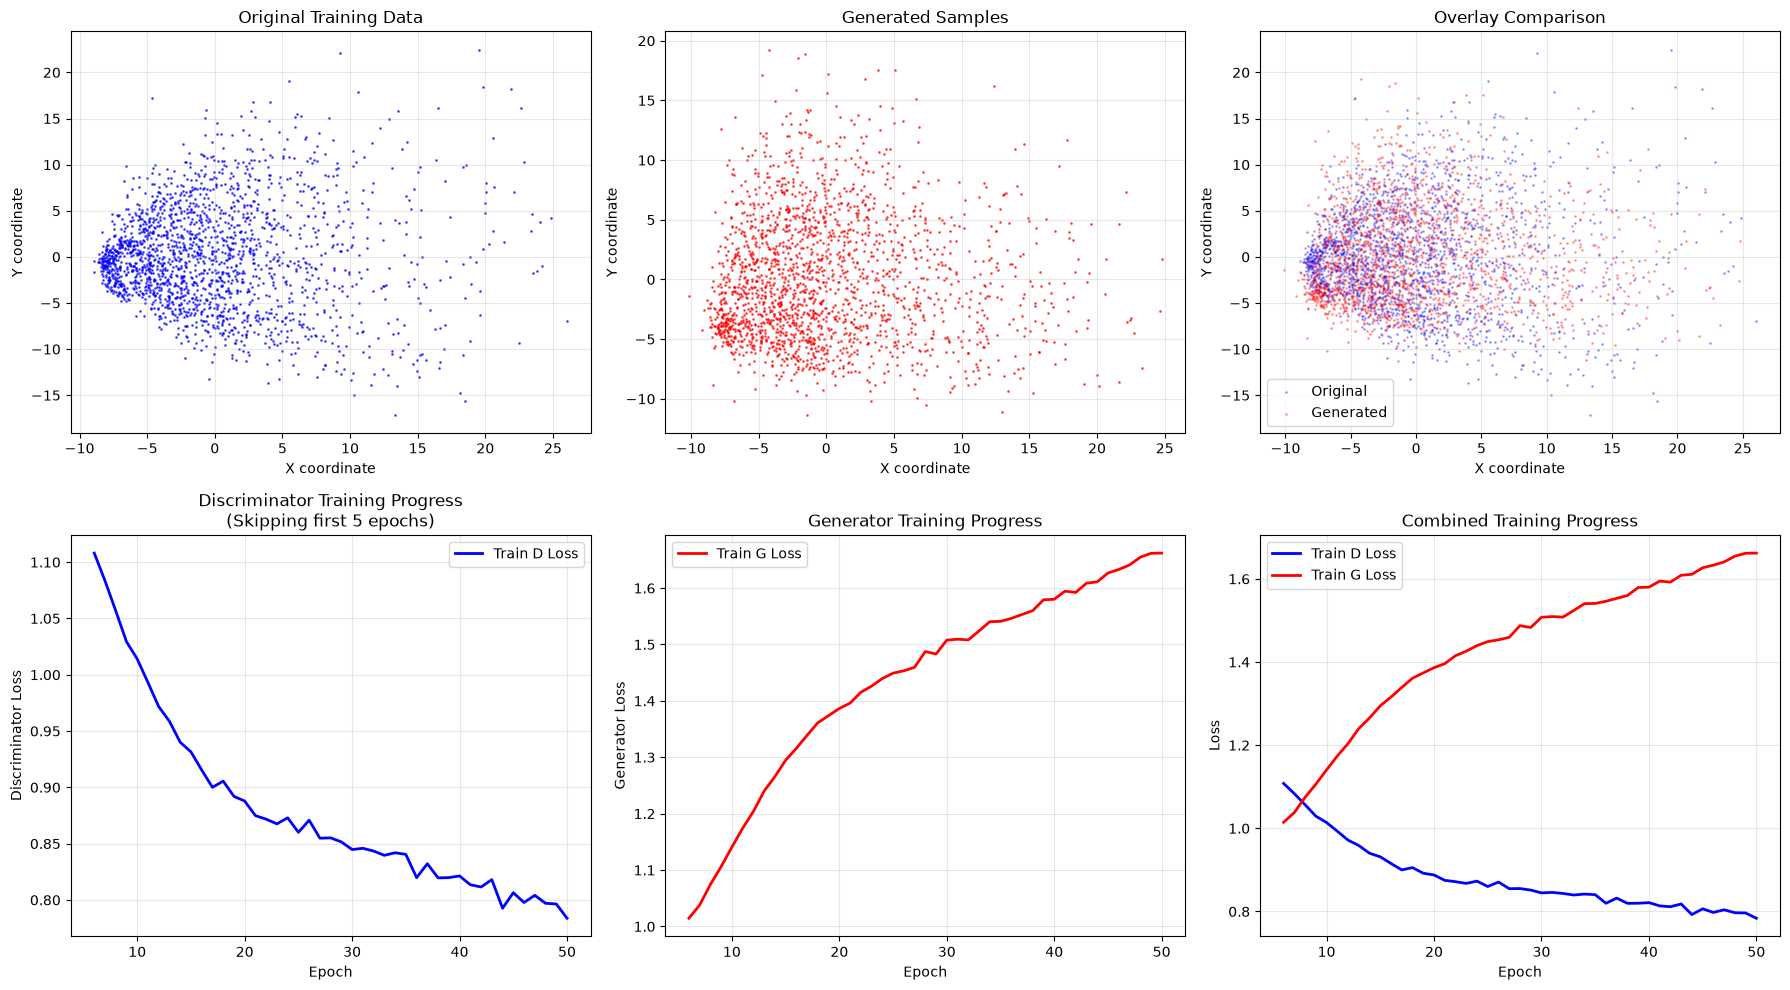

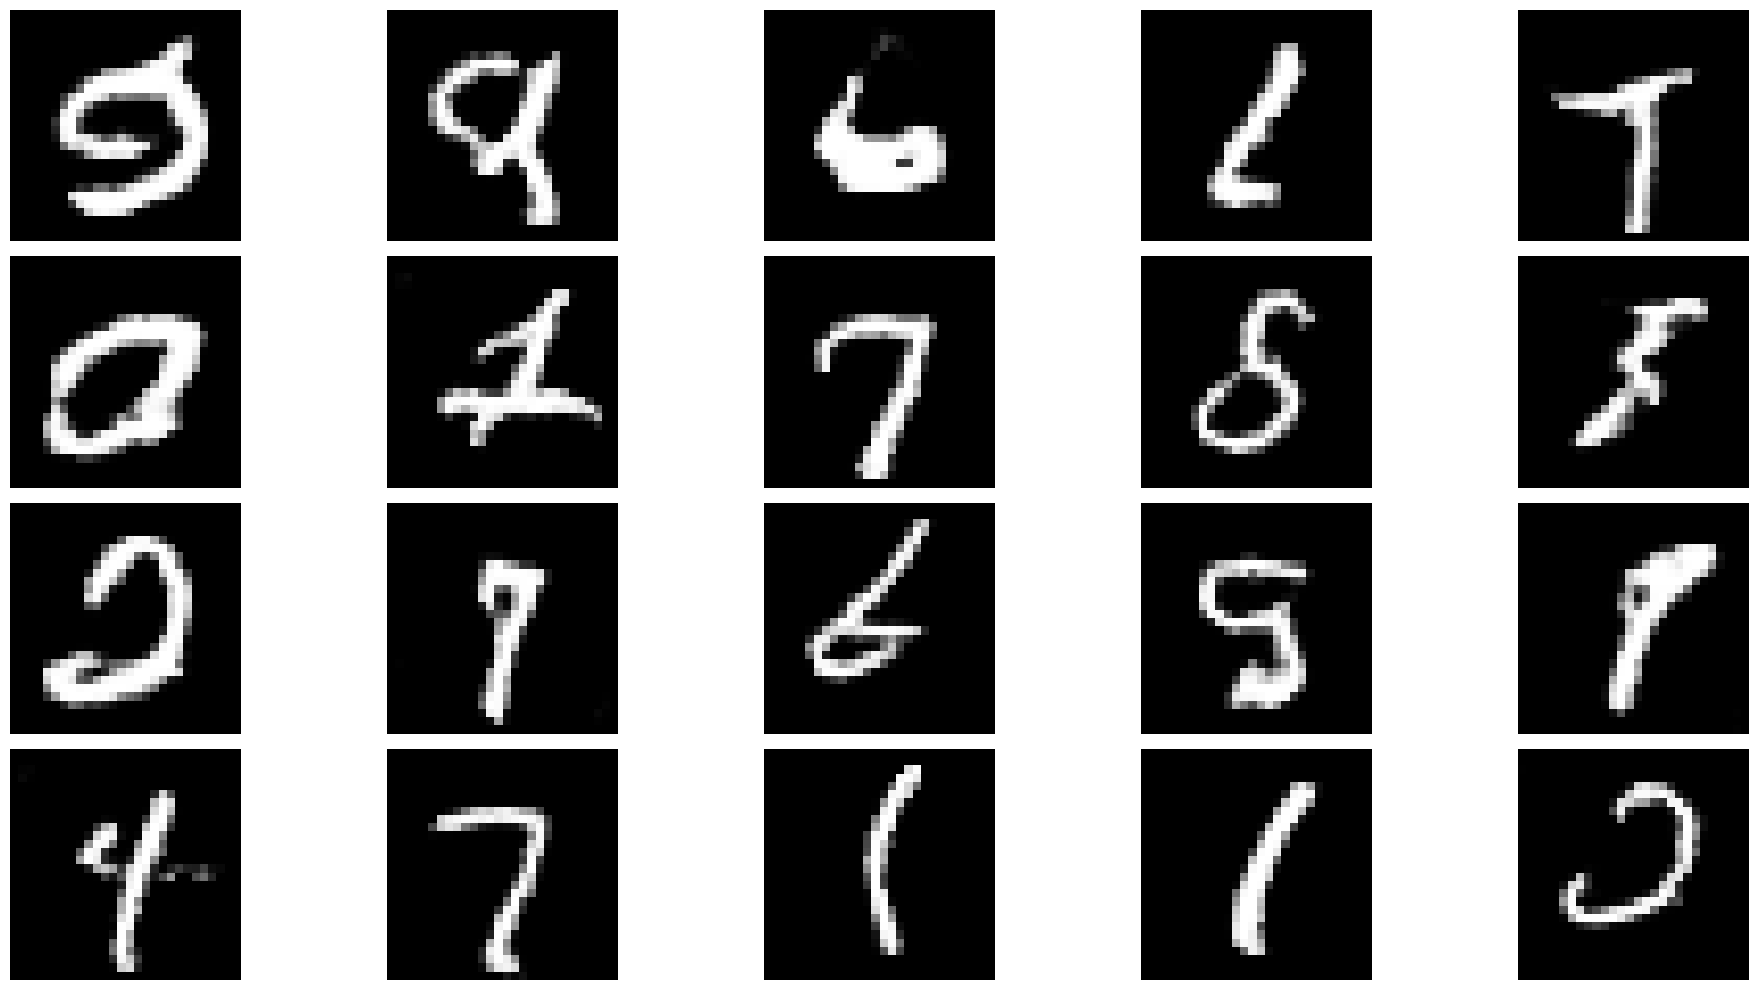

📈 Epoch 50 Summary:
   Train D Loss: 0.7838, Val D Loss: 1.1085
   Train G Loss: 1.6621, Val G Loss: 1.6433

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.676522	G_loss: 1.361864
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.812756	G_loss: 1.316637
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.784395	G_loss: 2.185671
Epoch: 51 [19200/60000 (32%)]	D_loss: 1.181960	G_loss: 2.040117
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.741266	G_loss: 1.560008
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.790279	G_loss: 1.316063
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.709502	G_loss: 1.848659
Epoch: 51 [44800/60000 (75%)]	D_loss: 1.081996	G_loss: 0.843032
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.925387	G_loss: 0.819888
Epoch: 51 [57600/60000 (96%)]	D_loss: 1.329272	G_loss: 0.719399
====> Epoch: 51 Train D_loss: 0.7903, Train G_loss: 1.6777
====> Epoch: 51 Val D_loss: 1.2500, Val G_loss: 1.9822
📈 Epoch 51 Summary:
   Train D Loss: 0.7903, Val D Loss: 1.2500
   Train G Loss: 1.6777

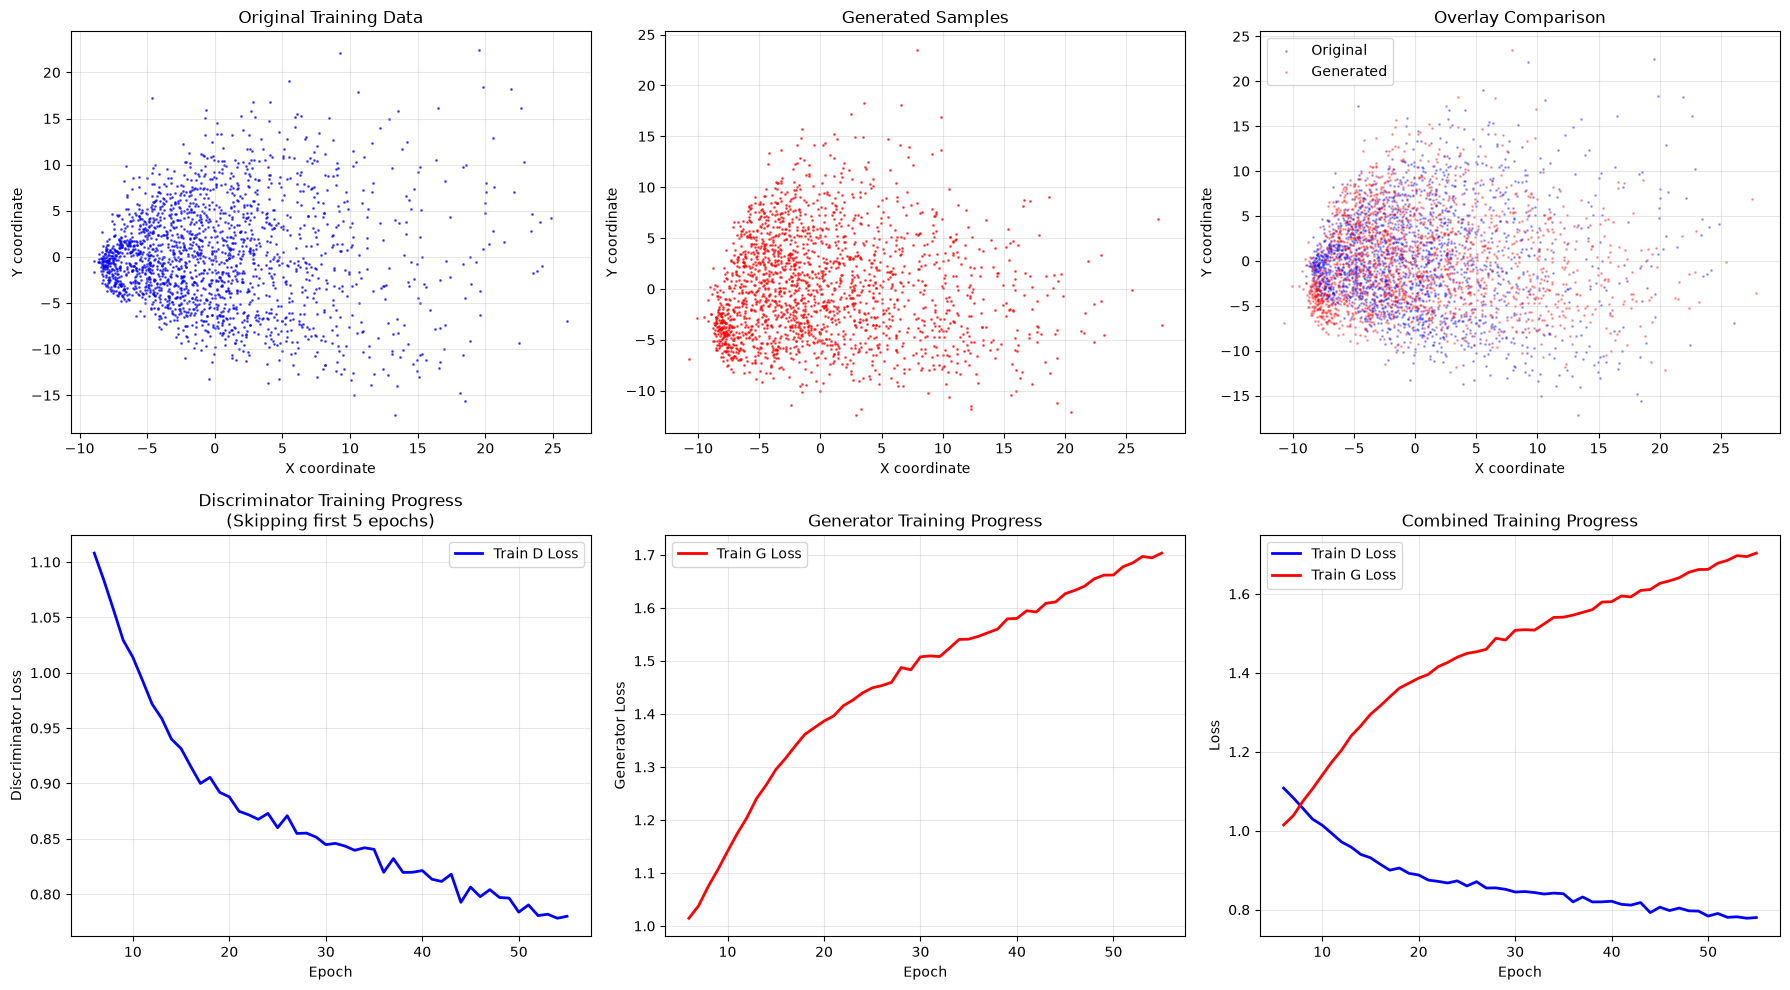

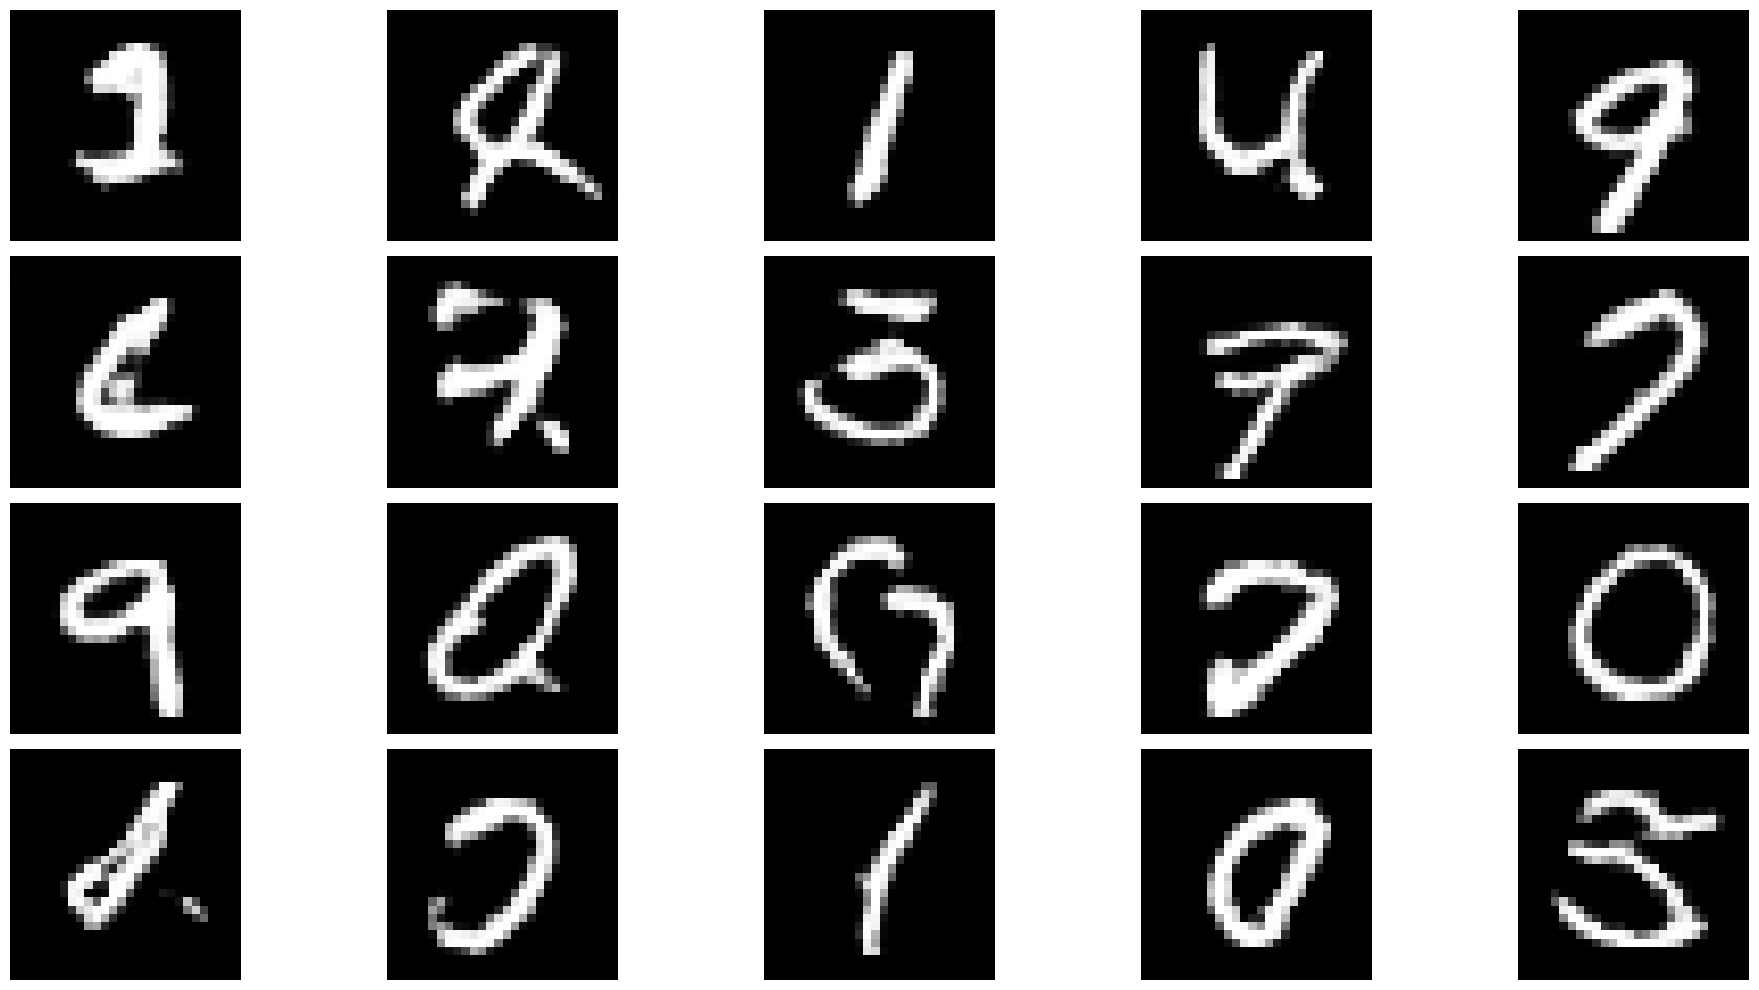

📈 Epoch 55 Summary:
   Train D Loss: 0.7800, Val D Loss: 1.2899
   Train G Loss: 1.7033, Val G Loss: 0.6338

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.926721	G_loss: 2.623003
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.787275	G_loss: 1.176220
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.752723	G_loss: 1.790975
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.713091	G_loss: 1.171899
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.616840	G_loss: 1.342625
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.791393	G_loss: 1.352301
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.687407	G_loss: 2.274871
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.668145	G_loss: 1.477200
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.732726	G_loss: 2.201403
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.703238	G_loss: 1.566090
====> Epoch: 56 Train D_loss: 0.7712, Train G_loss: 1.7150
====> Epoch: 56 Val D_loss: 1.0703, Val G_loss: 1.5041
📈 Epoch 56 Summary:
   Train D Loss: 0.7712, Val D Loss: 1.0703
   Train G Loss: 1.7150

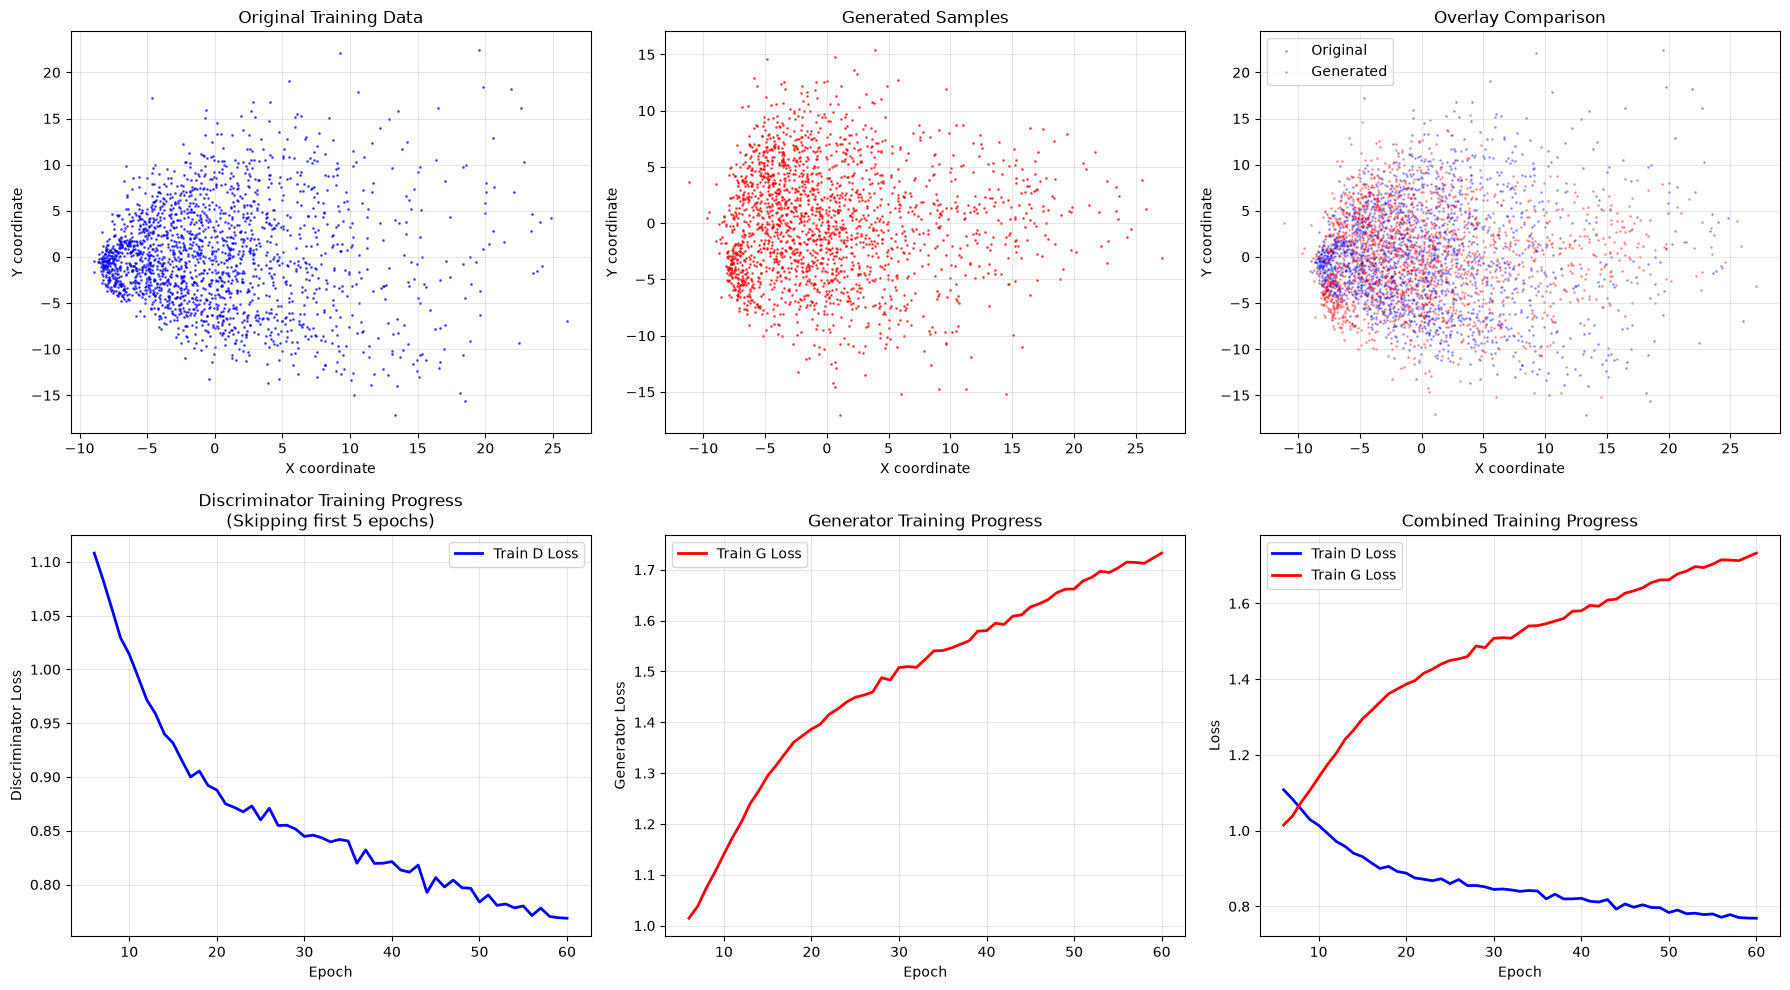

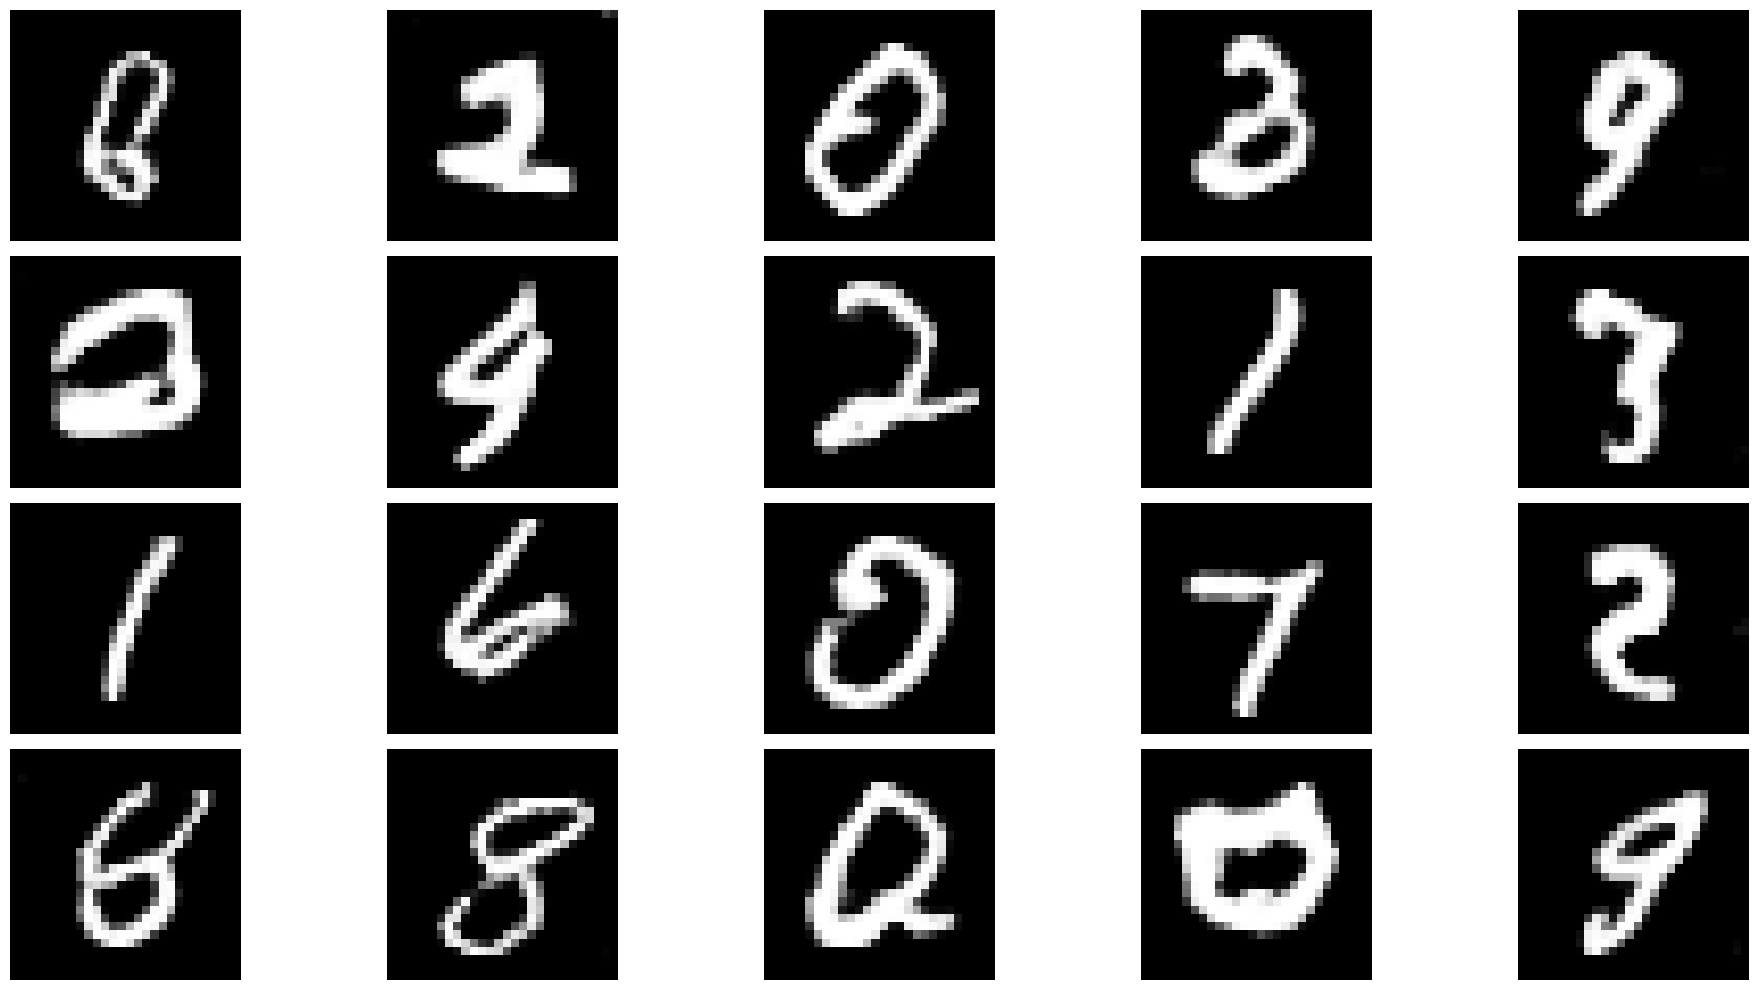

📈 Epoch 60 Summary:
   Train D Loss: 0.7687, Val D Loss: 1.3285
   Train G Loss: 1.7327, Val G Loss: 0.6631

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.784717	G_loss: 1.568033
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.696717	G_loss: 1.423957
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.754593	G_loss: 1.976582
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.716066	G_loss: 1.955339
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.919698	G_loss: 2.629210
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.698761	G_loss: 2.213308
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.687788	G_loss: 1.287945
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.856209	G_loss: 1.028557
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.803931	G_loss: 1.658730
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.848056	G_loss: 1.012691
====> Epoch: 61 Train D_loss: 0.7528, Train G_loss: 1.7505
====> Epoch: 61 Val D_loss: 1.1832, Val G_loss: 1.9402
📈 Epoch 61 Summary:
   Train D Loss: 0.7528, Val D Loss: 1.1832
   Train G Loss: 1.7505

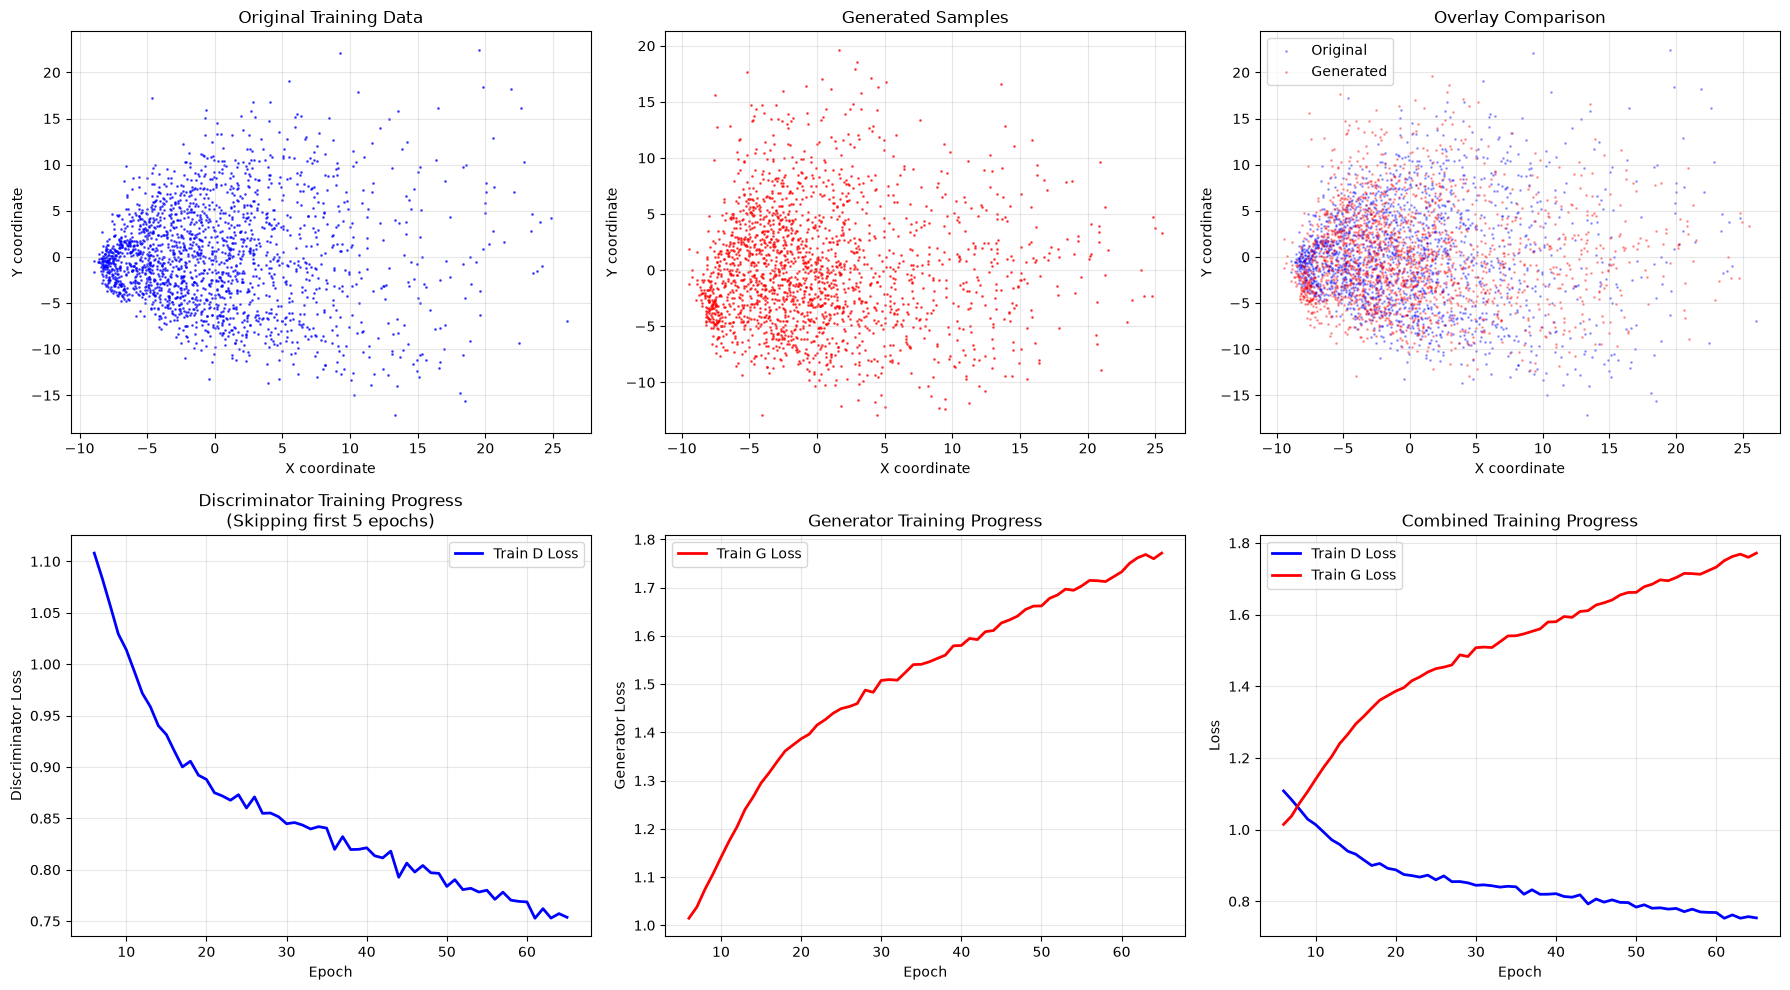

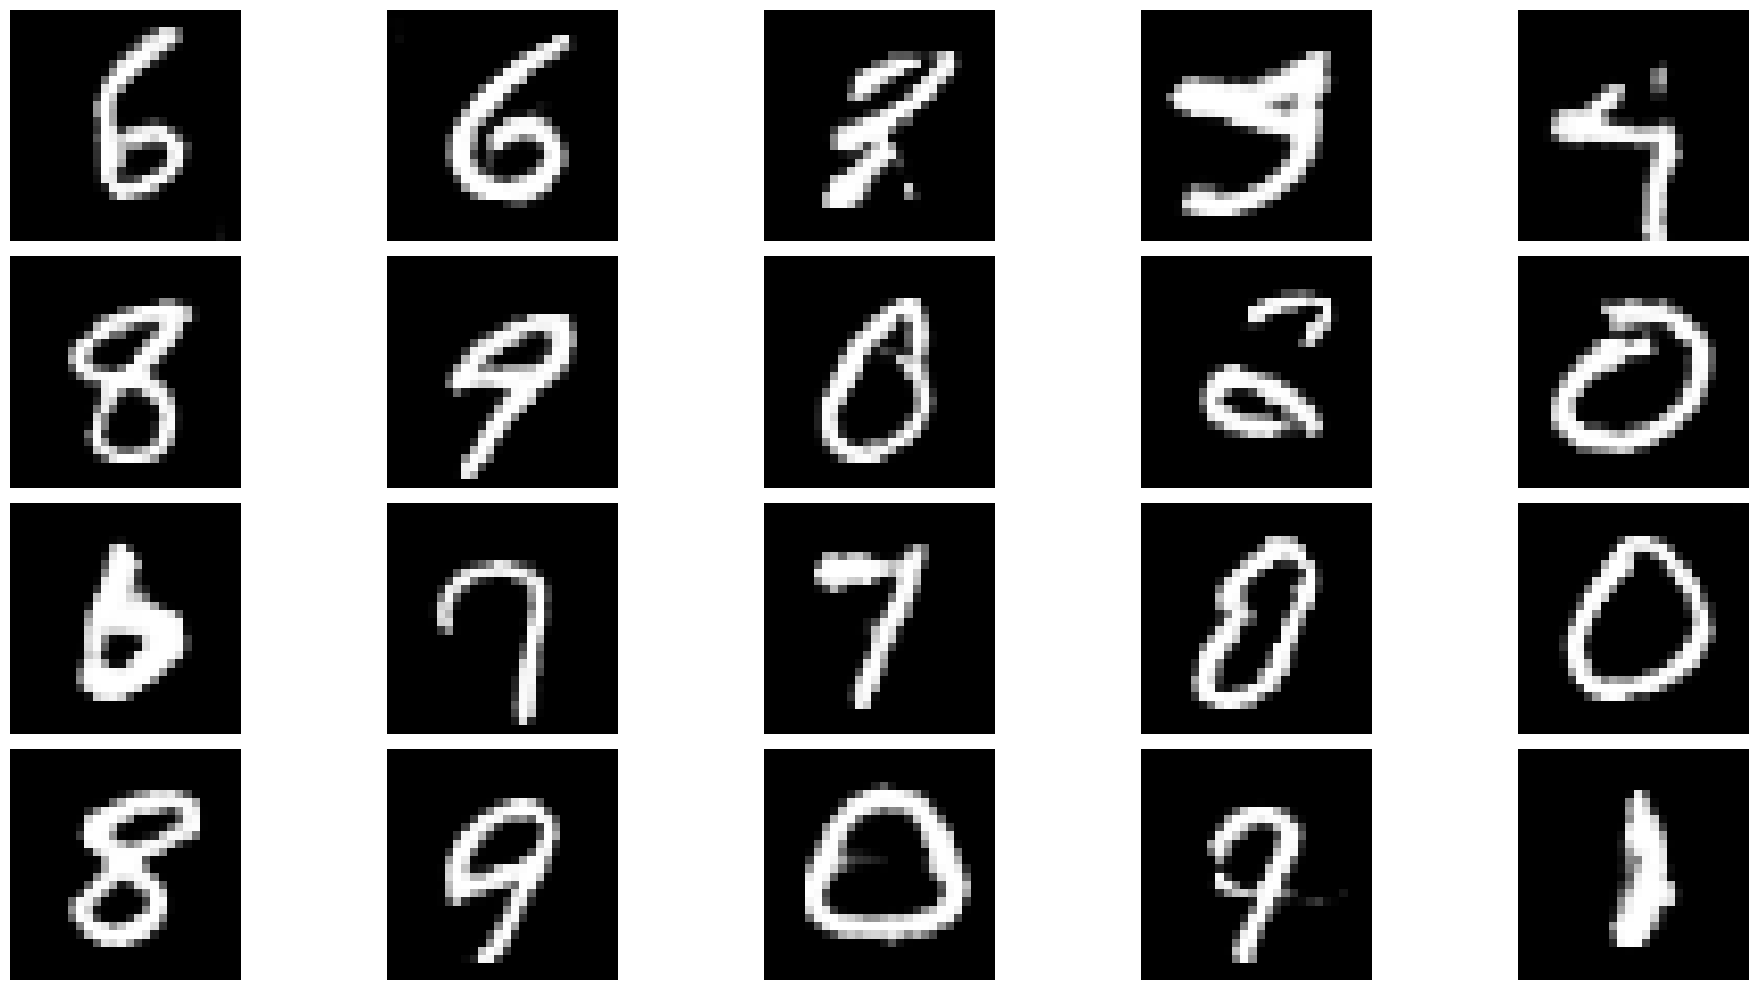

📈 Epoch 65 Summary:
   Train D Loss: 0.7537, Val D Loss: 1.1624
   Train G Loss: 1.7716, Val G Loss: 1.9297

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.650114	G_loss: 2.086663
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.798576	G_loss: 1.111459
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.647002	G_loss: 1.269824
Epoch: 66 [19200/60000 (32%)]	D_loss: 1.259921	G_loss: 0.545777
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.963766	G_loss: 0.681671
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.697187	G_loss: 1.317555
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.595364	G_loss: 1.877659
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.576941	G_loss: 1.871469
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.889907	G_loss: 0.770911
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.651893	G_loss: 1.614164
====> Epoch: 66 Train D_loss: 0.7501, Train G_loss: 1.7852
====> Epoch: 66 Val D_loss: 1.1634, Val G_loss: 1.8554
📈 Epoch 66 Summary:
   Train D Loss: 0.7501, Val D Loss: 1.1634
   Train G Loss: 1.7852

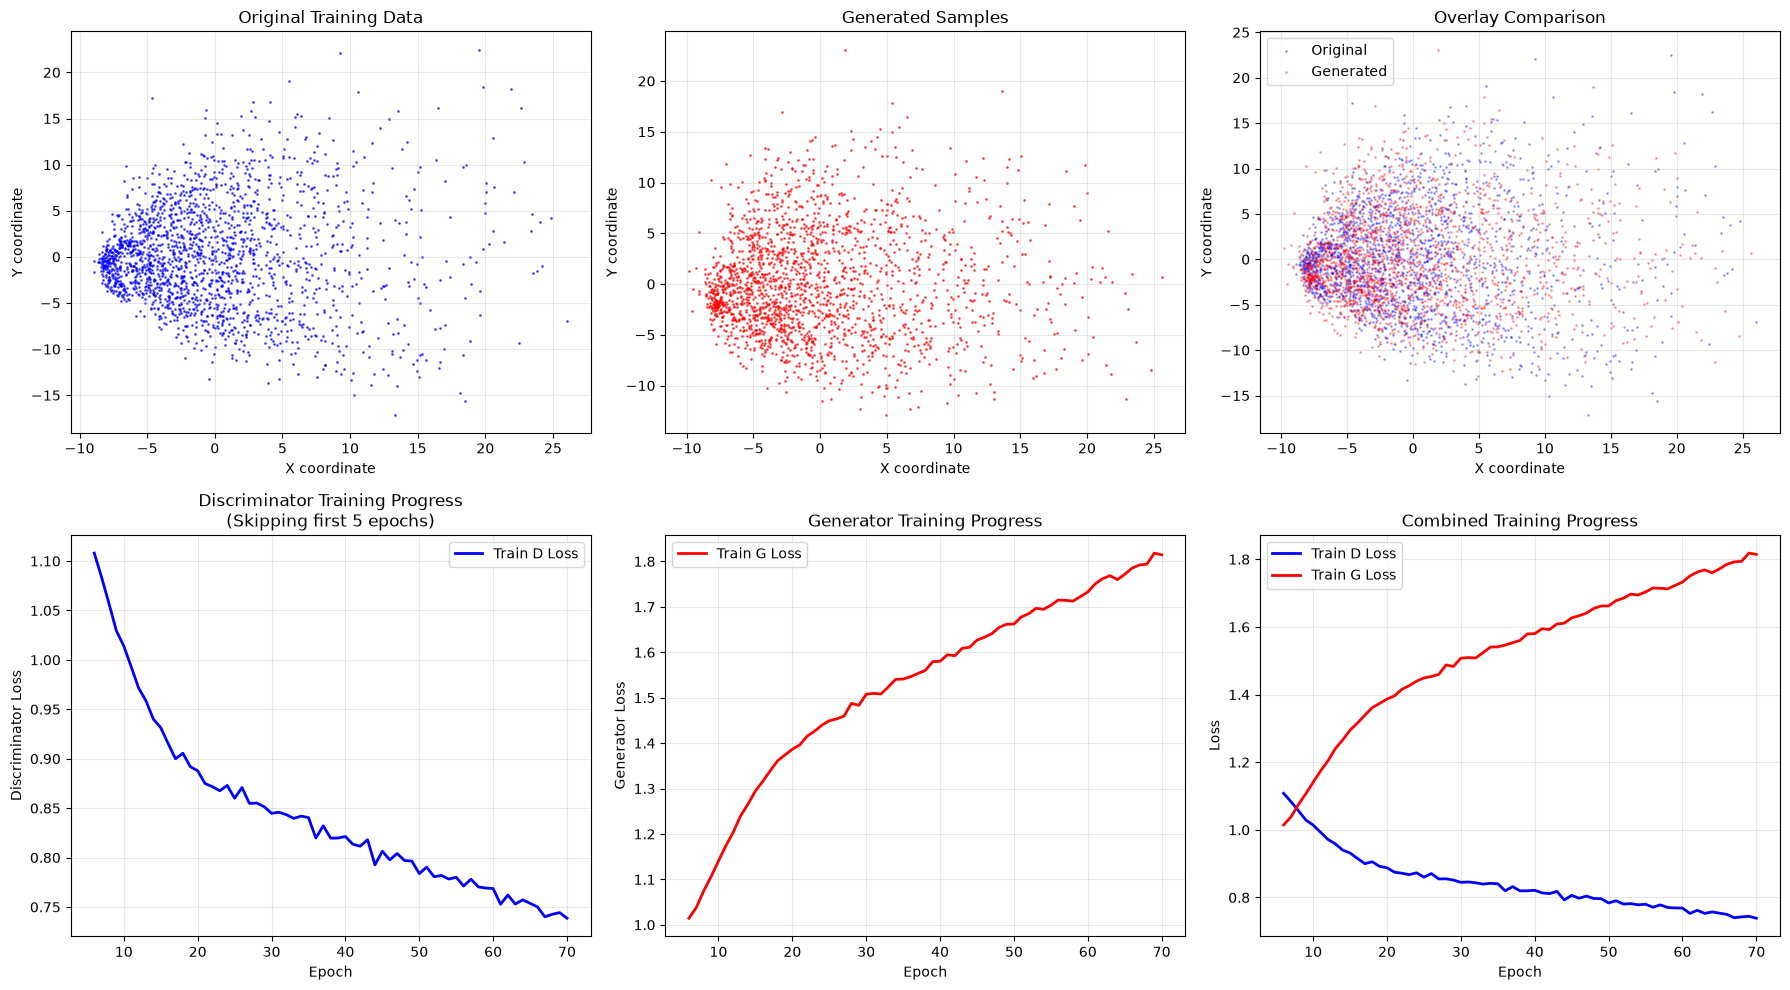

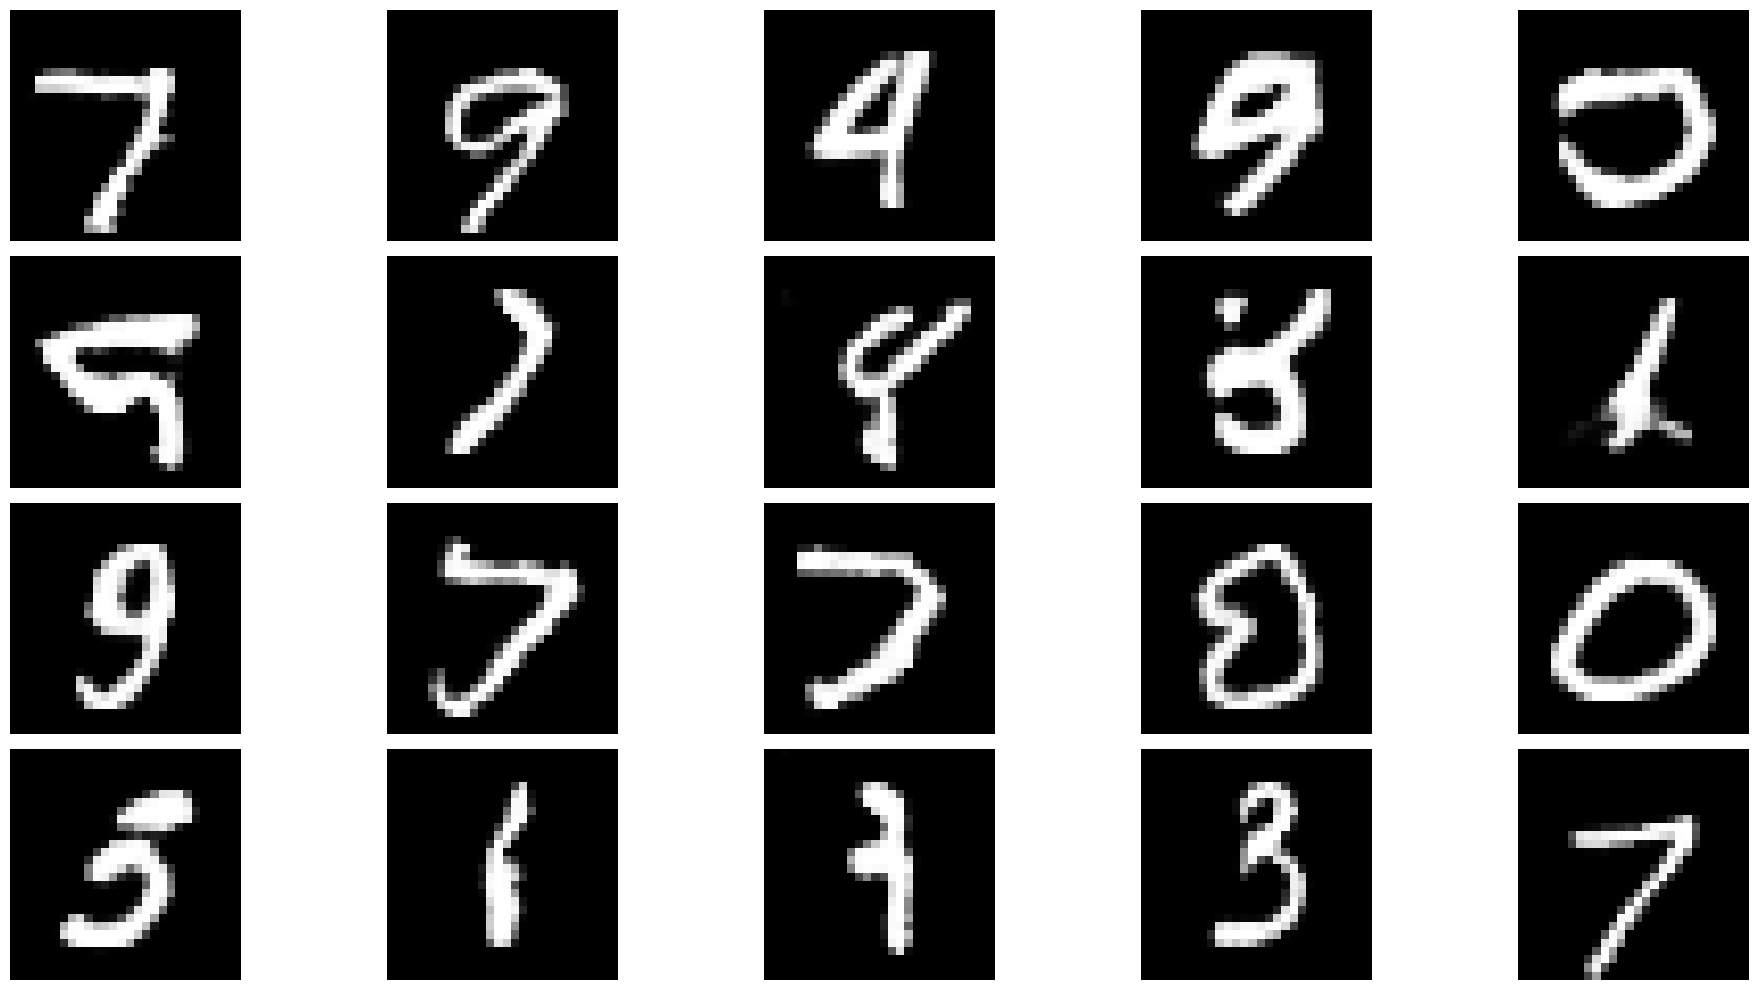

📈 Epoch 70 Summary:
   Train D Loss: 0.7386, Val D Loss: 1.0888
   Train G Loss: 1.8145, Val G Loss: 1.0784

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.766615	G_loss: 2.796208
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.759799	G_loss: 2.085413
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.685744	G_loss: 1.724833
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.878345	G_loss: 1.025741
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.778284	G_loss: 1.211233
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.510626	G_loss: 1.900757
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.723879	G_loss: 2.350675
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.728652	G_loss: 2.536084
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.625903	G_loss: 1.123345
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.720230	G_loss: 1.750223
====> Epoch: 71 Train D_loss: 0.7374, Train G_loss: 1.8198
====> Epoch: 71 Val D_loss: 1.1291, Val G_loss: 1.8495
📈 Epoch 71 Summary:
   Train D Loss: 0.7374, Val D Loss: 1.1291
   Train G Loss: 1.8198

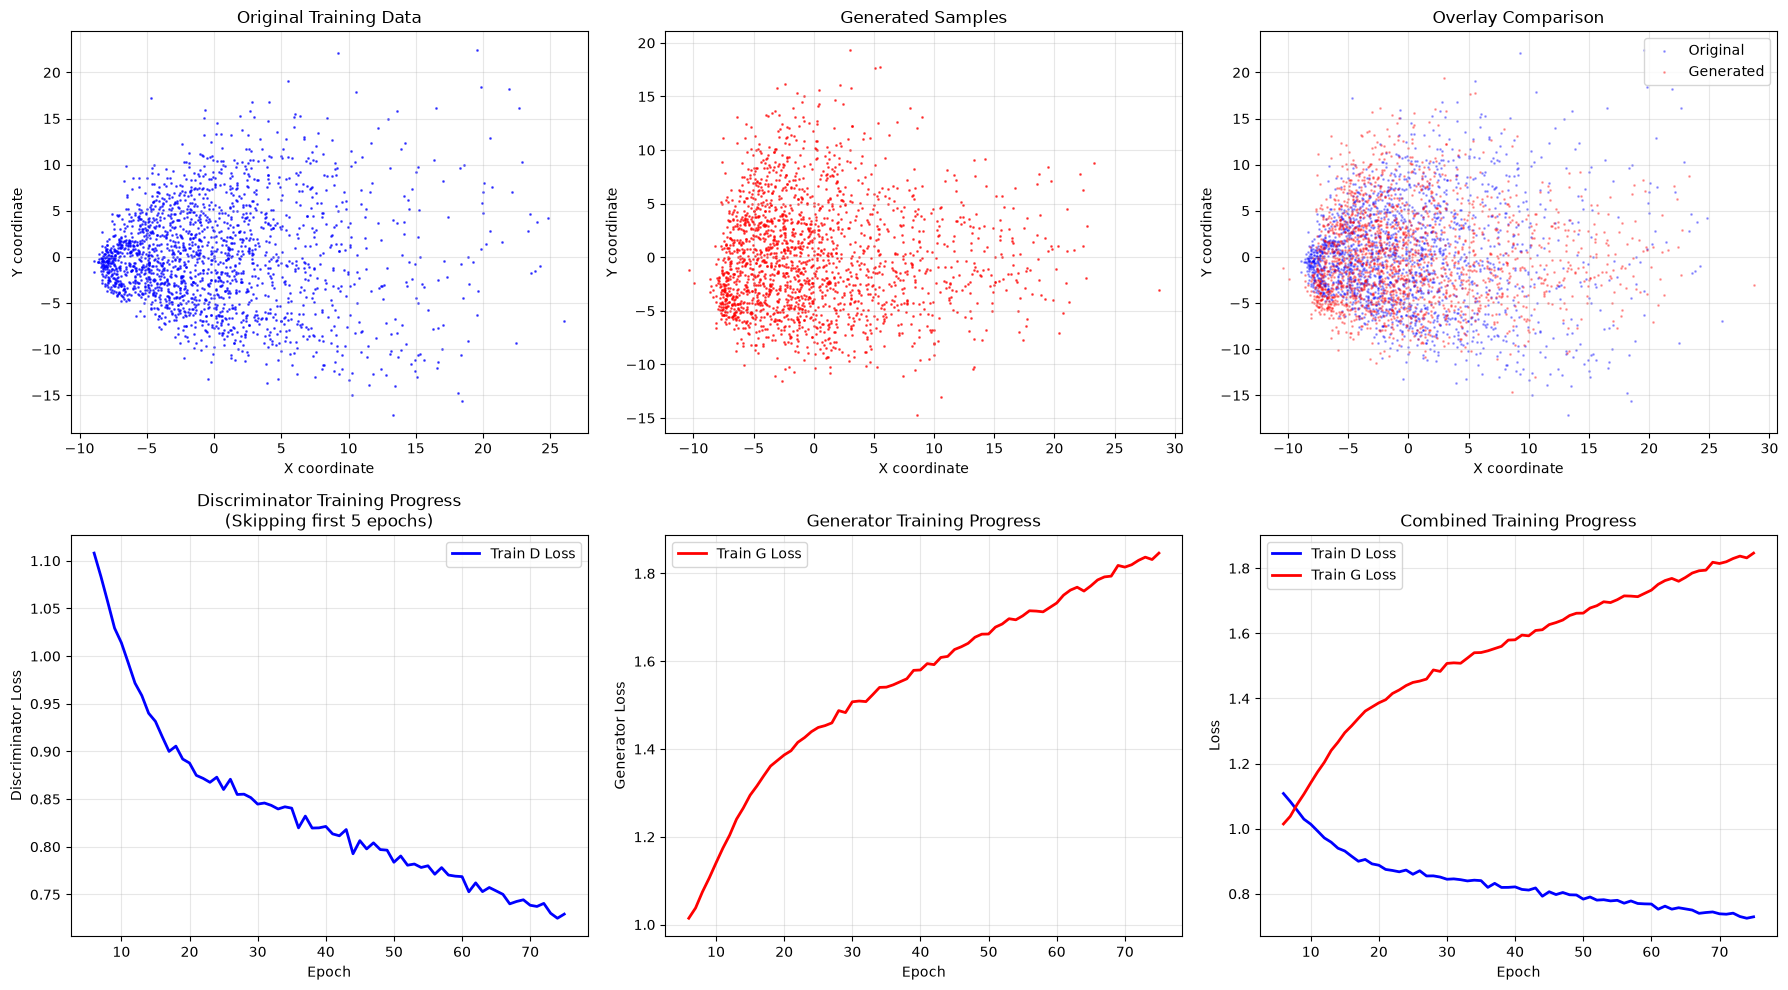

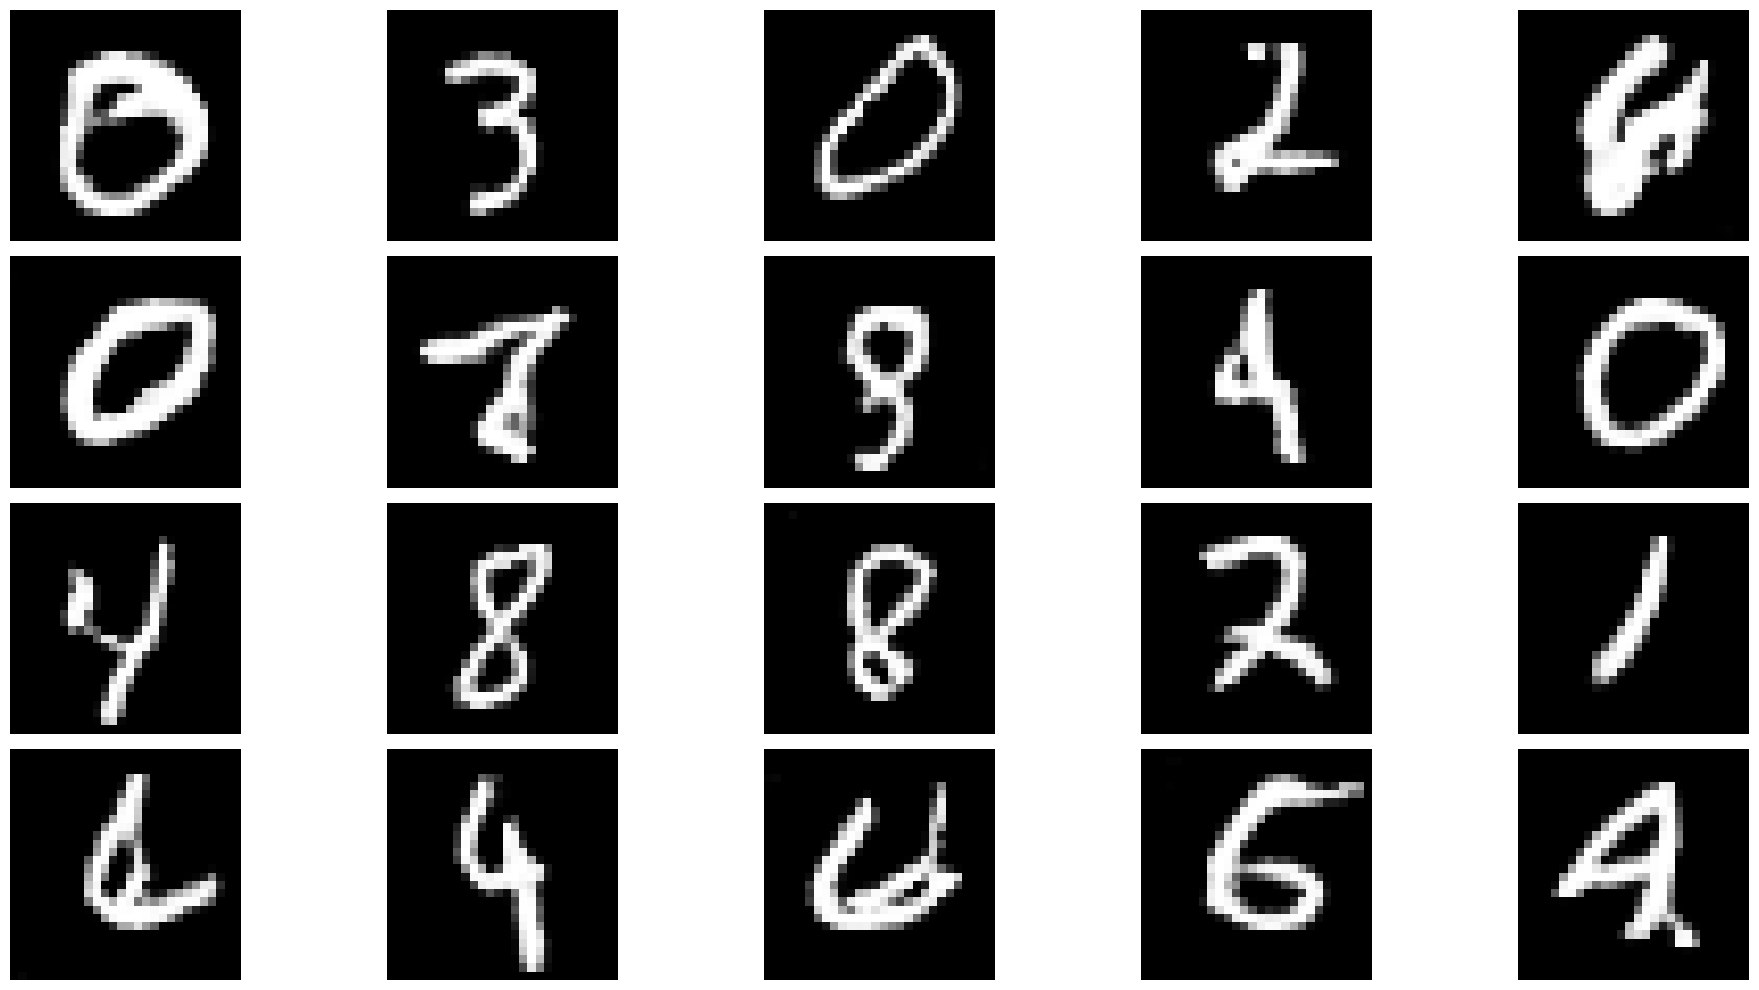

📈 Epoch 75 Summary:
   Train D Loss: 0.7294, Val D Loss: 1.3686
   Train G Loss: 1.8464, Val G Loss: 0.6052

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.723658	G_loss: 2.390522
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.595571	G_loss: 2.011686
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.572396	G_loss: 1.544162
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.645029	G_loss: 1.705113
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.665497	G_loss: 1.931296
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.653944	G_loss: 1.818975
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.658235	G_loss: 1.615387
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.717839	G_loss: 1.580522
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.733193	G_loss: 1.111531
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.700107	G_loss: 2.234168
====> Epoch: 76 Train D_loss: 0.7264, Train G_loss: 1.8391
====> Epoch: 76 Val D_loss: 1.0995, Val G_loss: 0.9723
📈 Epoch 76 Summary:
   Train D Loss: 0.7264, Val D Loss: 1.0995
   Train G Loss: 1.8391

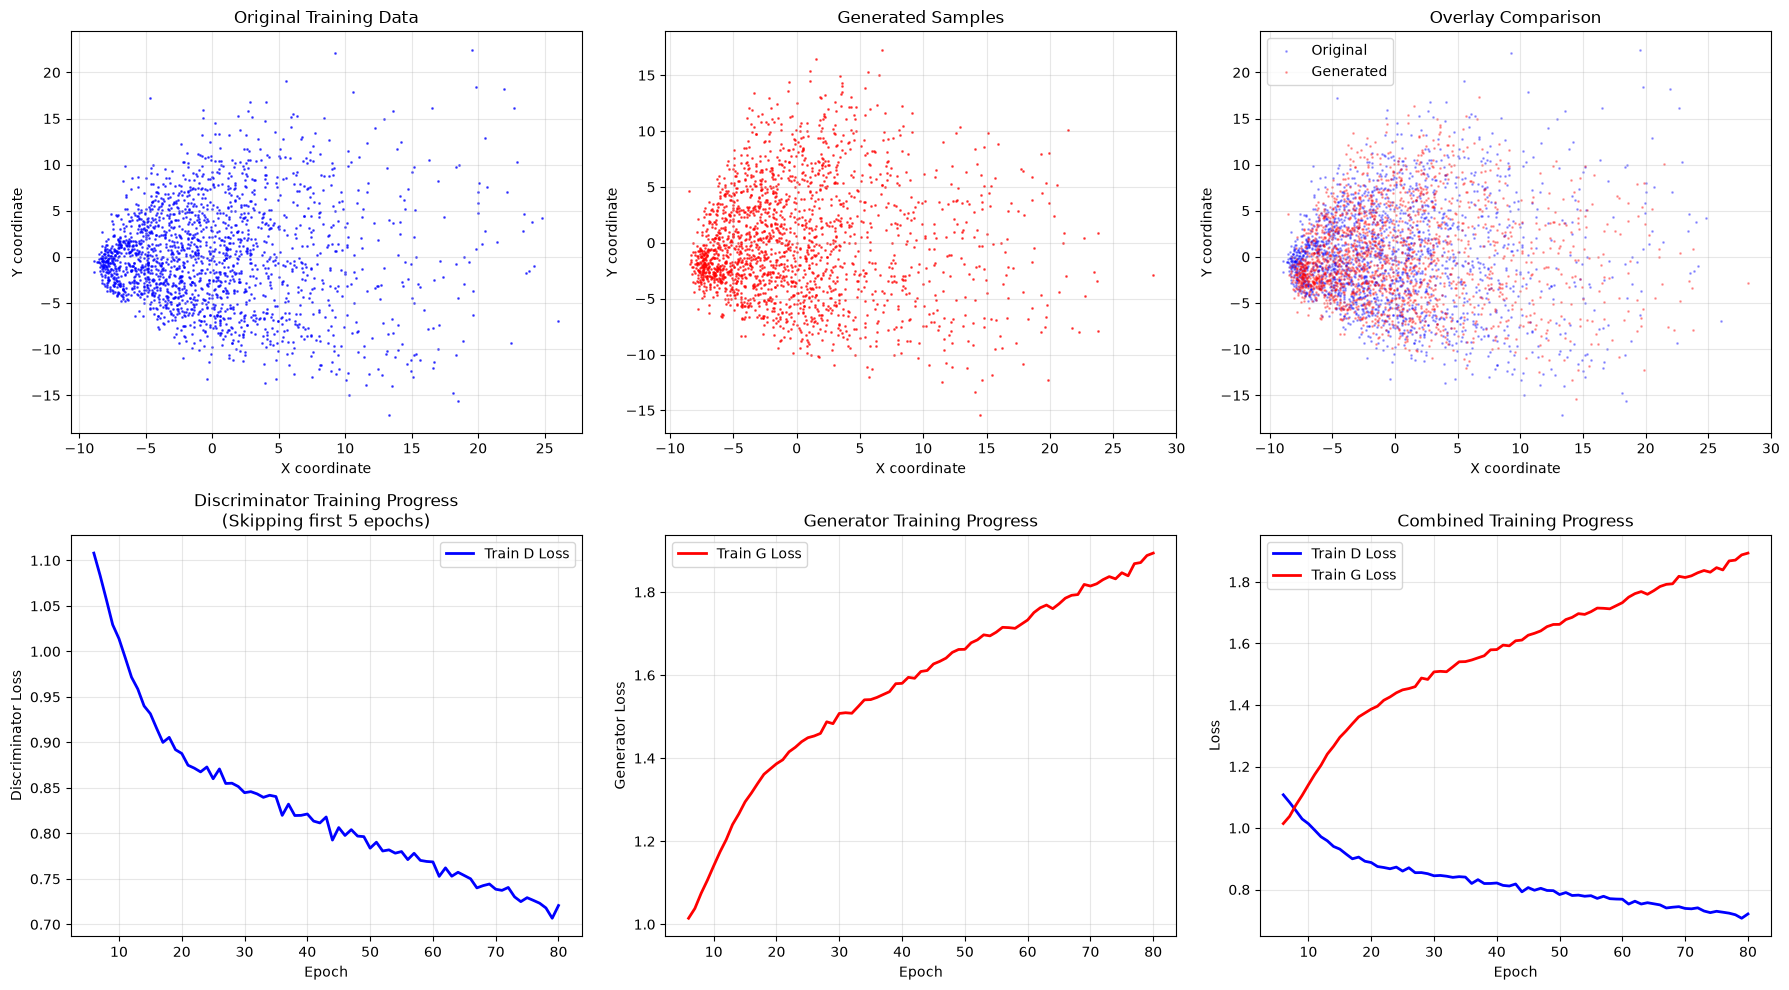

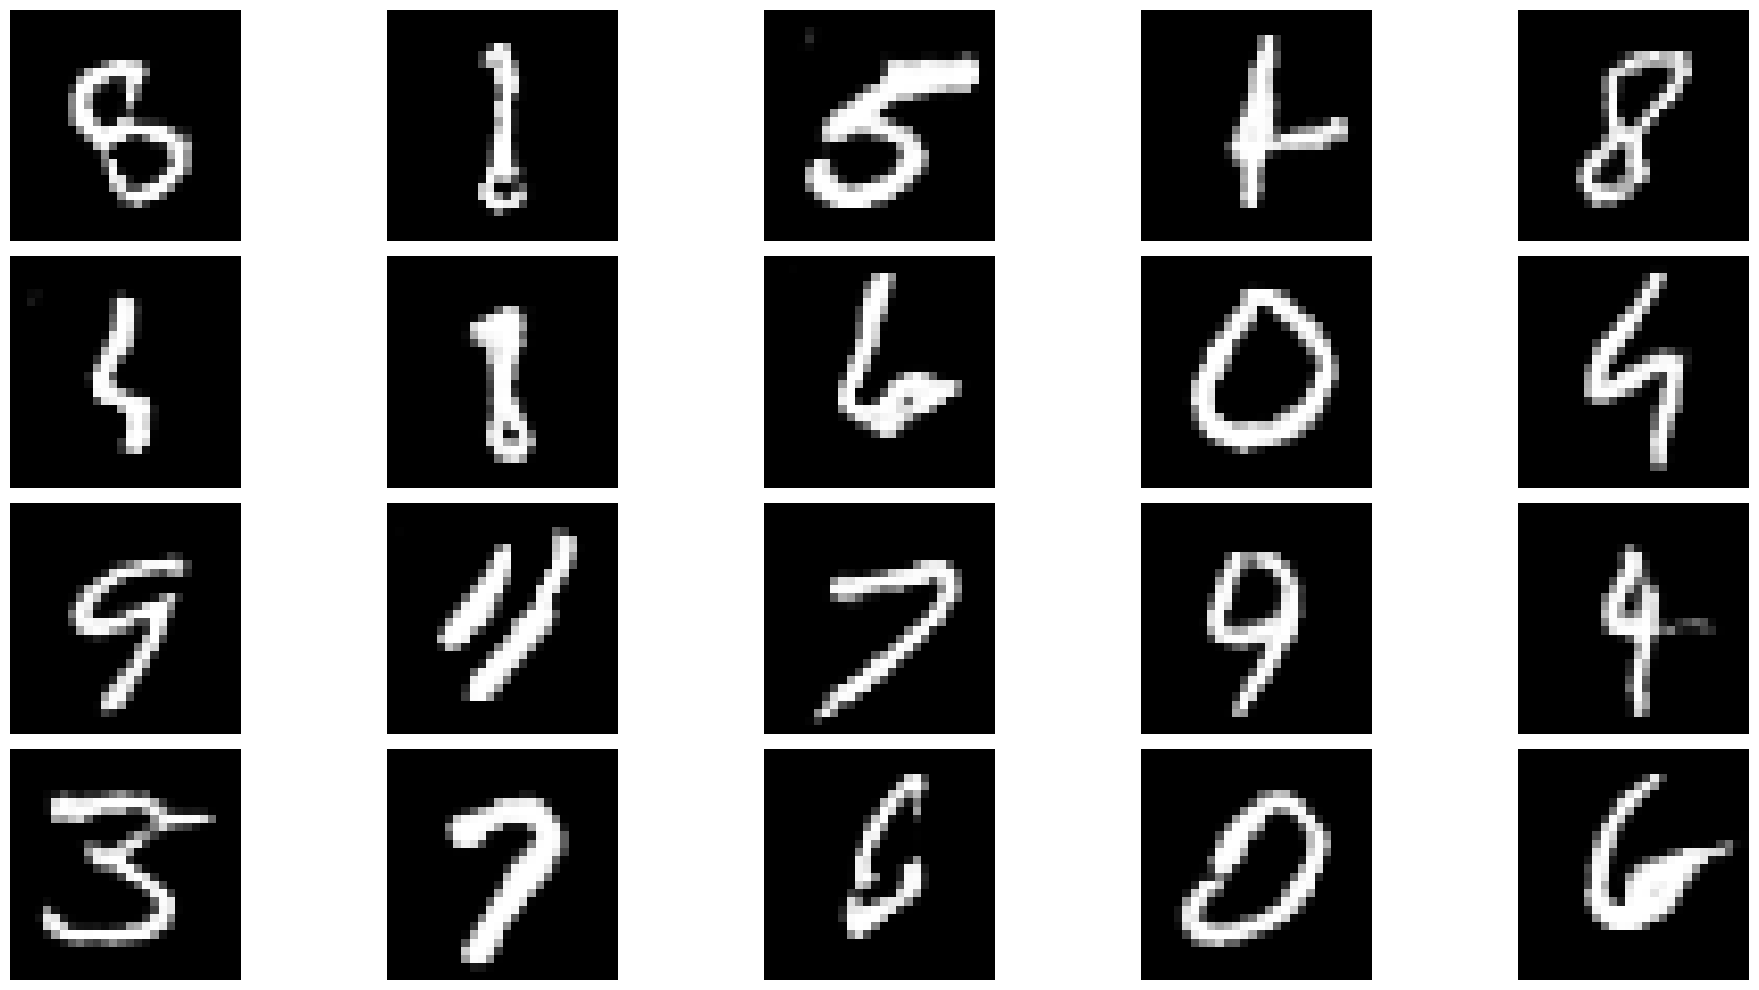

📈 Epoch 80 Summary:
   Train D Loss: 0.7207, Val D Loss: 1.3125
   Train G Loss: 1.8938, Val G Loss: 0.7403

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.902278	G_loss: 2.960869
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.924883	G_loss: 1.305694
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.863971	G_loss: 2.743313
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.610597	G_loss: 2.234055
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.633227	G_loss: 2.336463
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.711203	G_loss: 1.273631
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.635476	G_loss: 1.405481
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.701283	G_loss: 1.726629
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.814999	G_loss: 1.557187
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.888455	G_loss: 1.461296
====> Epoch: 81 Train D_loss: 0.7049, Train G_loss: 1.8953
====> Epoch: 81 Val D_loss: 1.0454, Val G_loss: 1.2632
📈 Epoch 81 Summary:
   Train D Loss: 0.7049, Val D Loss: 1.0454
   Train G Loss: 1.8953

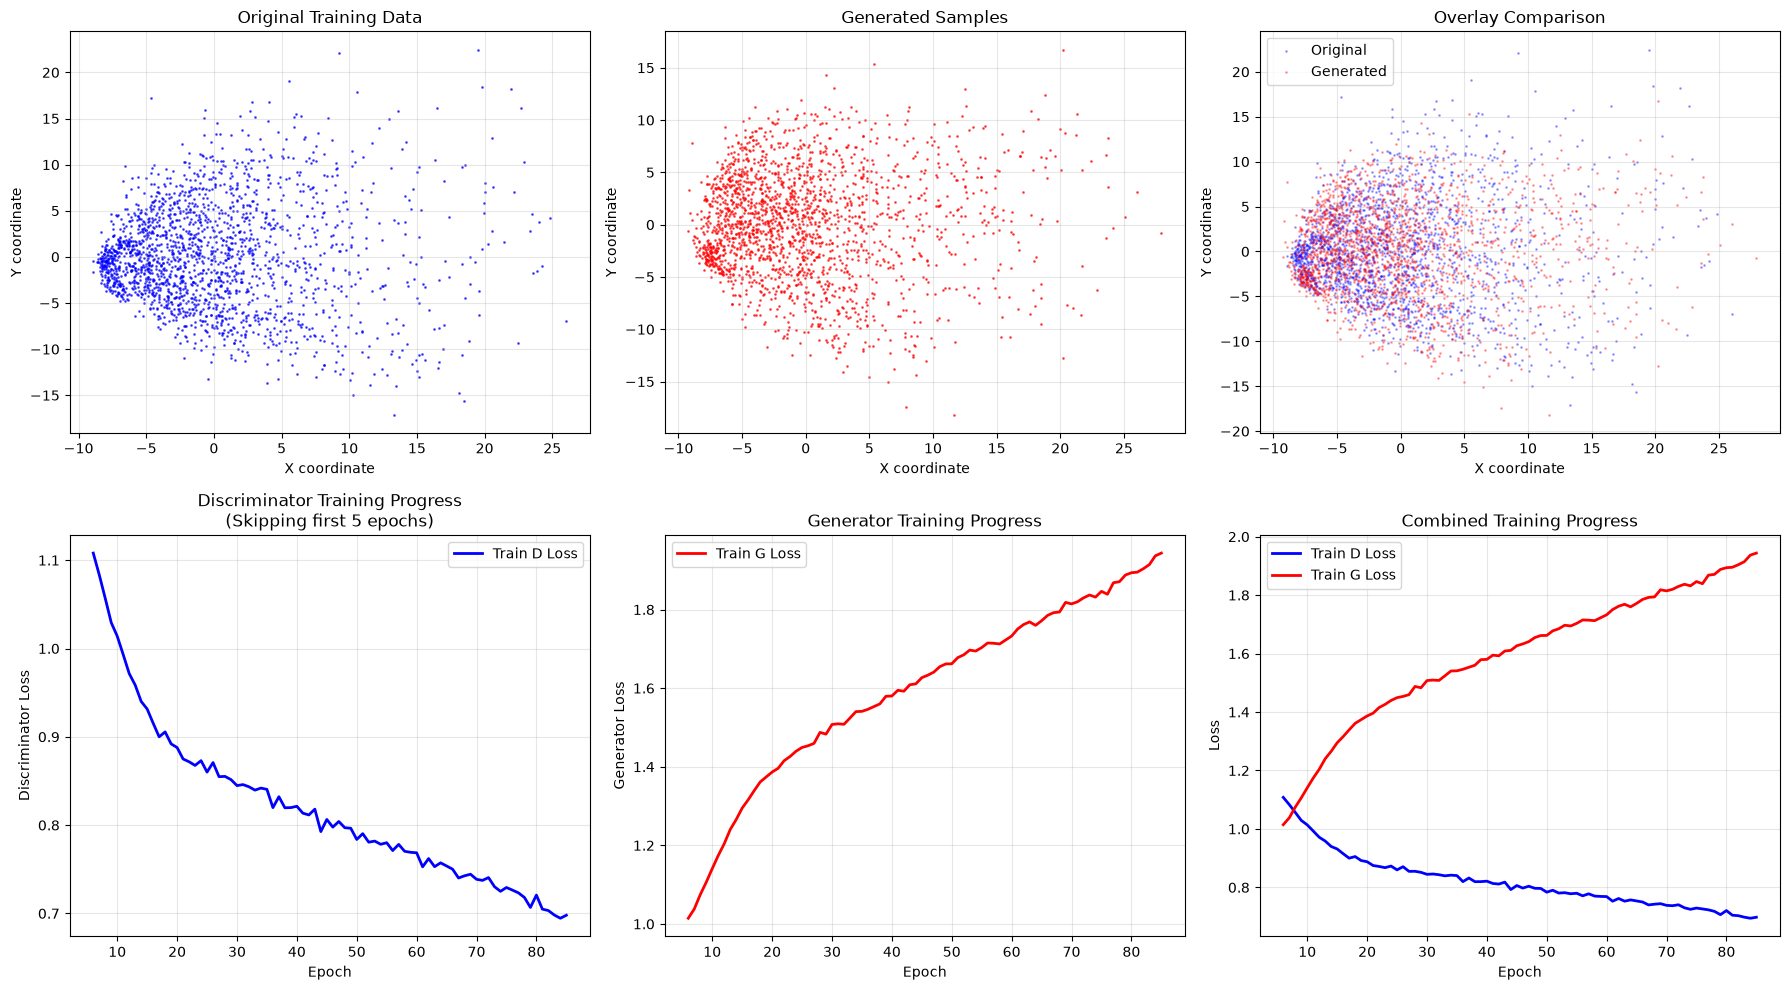

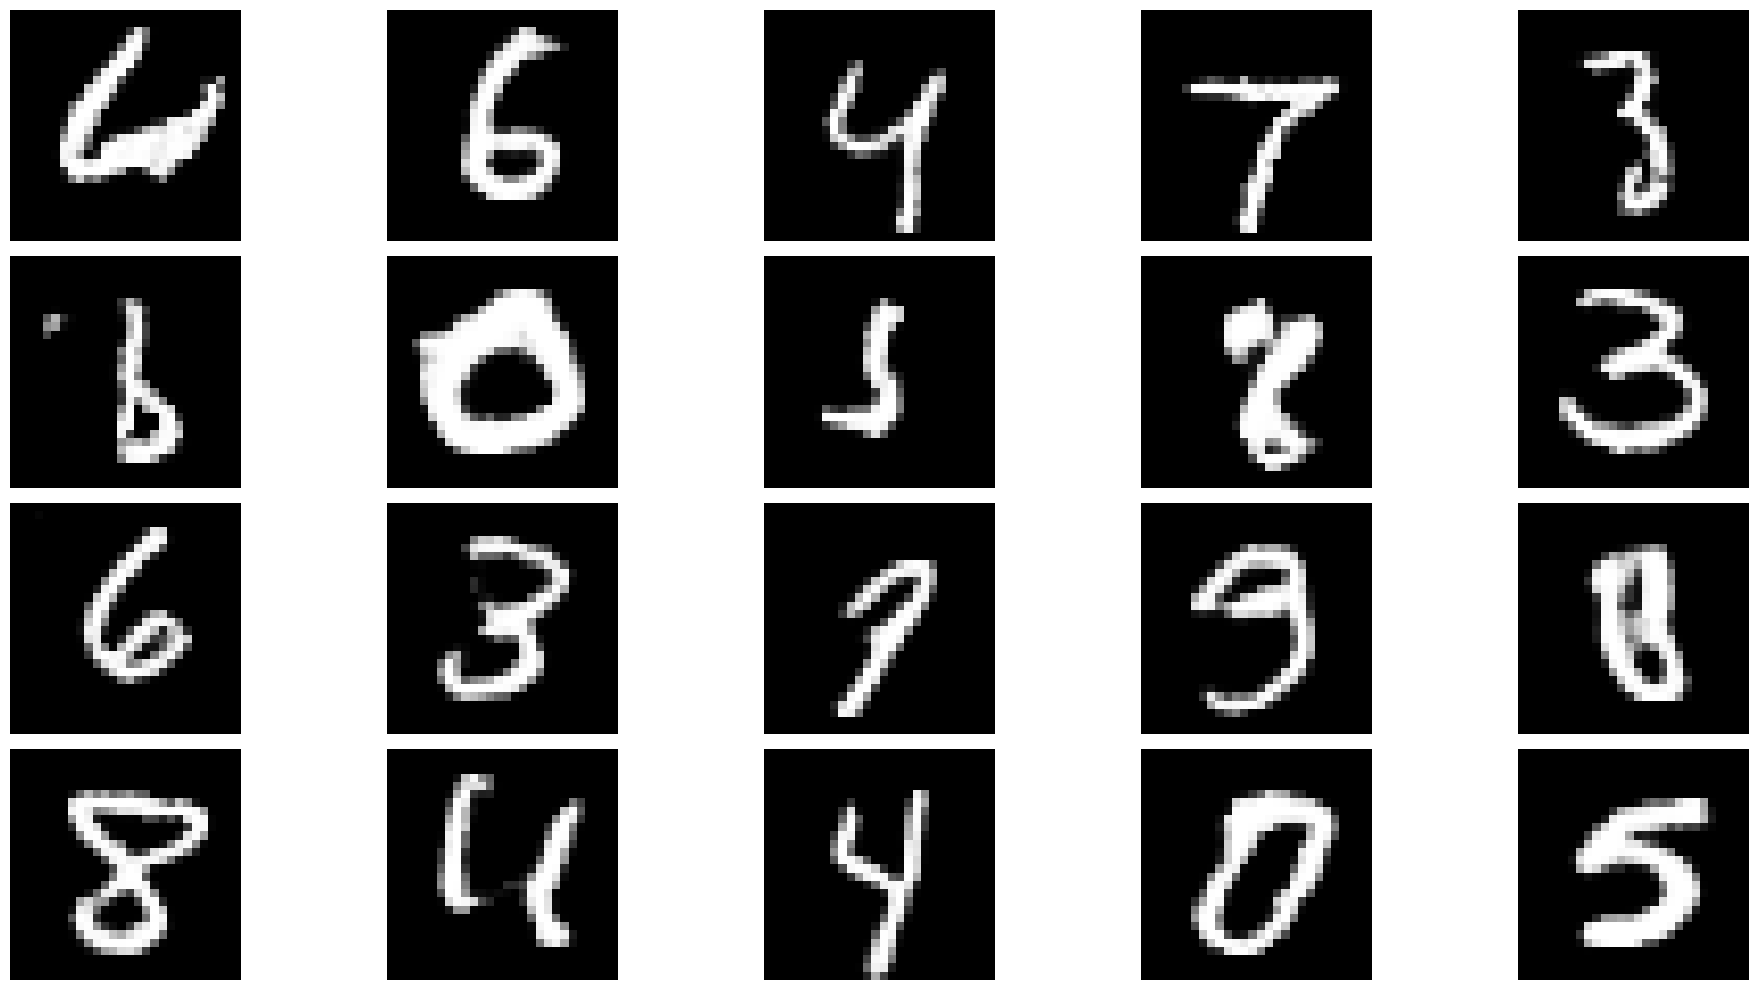

📈 Epoch 85 Summary:
   Train D Loss: 0.6979, Val D Loss: 1.5903
   Train G Loss: 1.9438, Val G Loss: 2.8384

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.731495	G_loss: 1.315548
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.611432	G_loss: 2.333416
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.733314	G_loss: 1.245725
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.581076	G_loss: 1.053291
Epoch: 86 [25600/60000 (43%)]	D_loss: 1.563597	G_loss: 3.169206
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.699636	G_loss: 1.607334
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.632541	G_loss: 2.055014
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.522652	G_loss: 2.402148
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.693615	G_loss: 1.186361
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.600531	G_loss: 2.176207
====> Epoch: 86 Train D_loss: 0.7021, Train G_loss: 1.9325
====> Epoch: 86 Val D_loss: 1.0664, Val G_loss: 1.5959
📈 Epoch 86 Summary:
   Train D Loss: 0.7021, Val D Loss: 1.0664
   Train G Loss: 1.9325

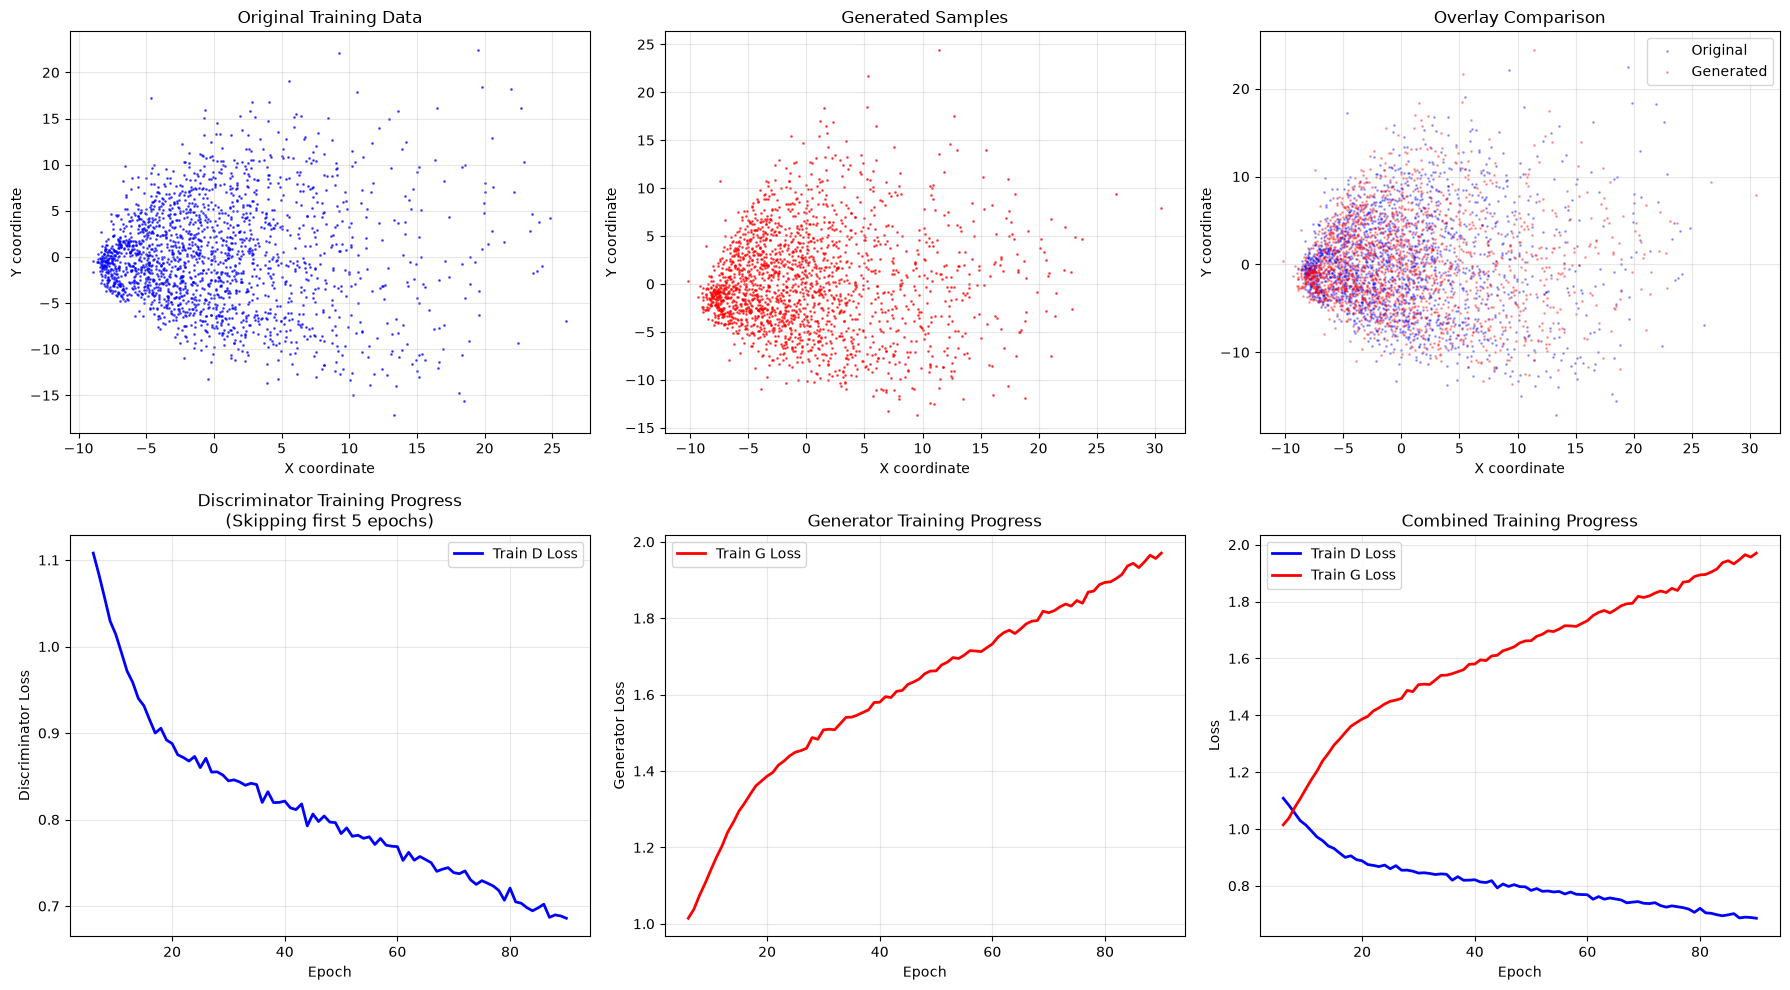

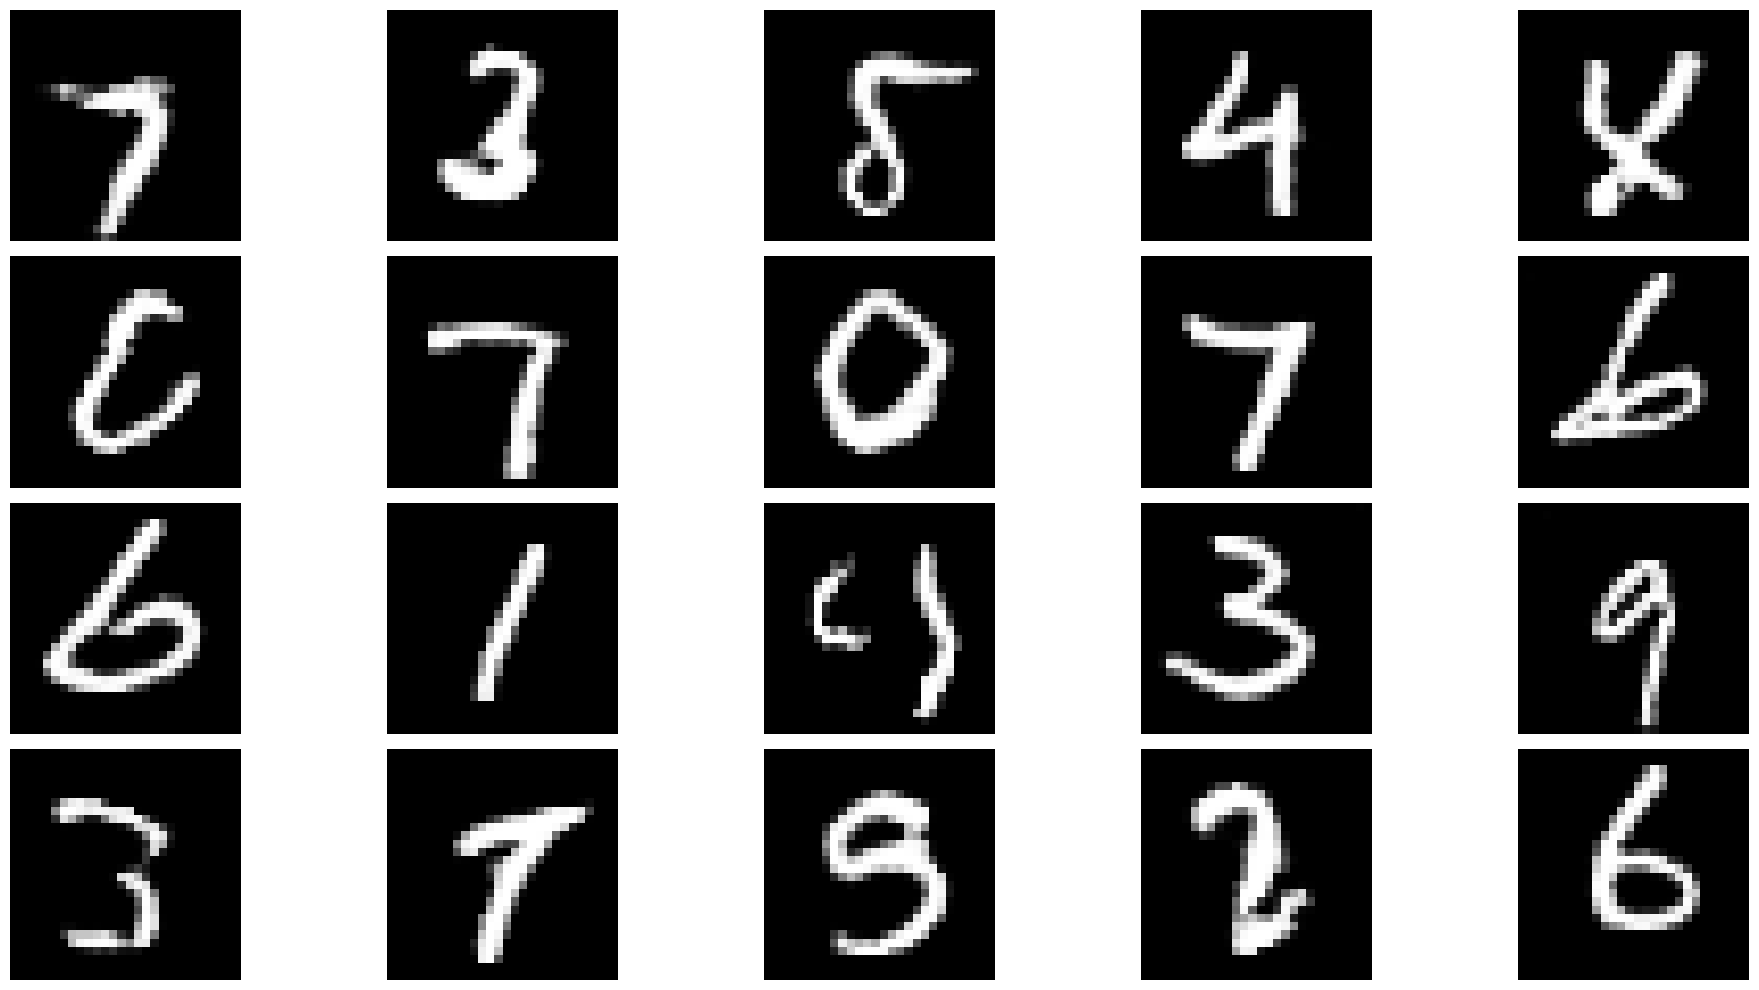

📈 Epoch 90 Summary:
   Train D Loss: 0.6859, Val D Loss: 1.2202
   Train G Loss: 1.9705, Val G Loss: 0.8003

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.802702	G_loss: 3.489022
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.657183	G_loss: 2.435911
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.669672	G_loss: 2.009427
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.797012	G_loss: 1.496223
Epoch: 91 [25600/60000 (43%)]	D_loss: 1.114147	G_loss: 1.248730
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.612492	G_loss: 2.360590
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.789287	G_loss: 2.951087
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.615593	G_loss: 2.023323
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.573767	G_loss: 1.828421
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.809555	G_loss: 1.519674
====> Epoch: 91 Train D_loss: 0.6810, Train G_loss: 1.9919
====> Epoch: 91 Val D_loss: 1.0603, Val G_loss: 1.4291
📈 Epoch 91 Summary:
   Train D Loss: 0.6810, Val D Loss: 1.0603
   Train G Loss: 1.9919

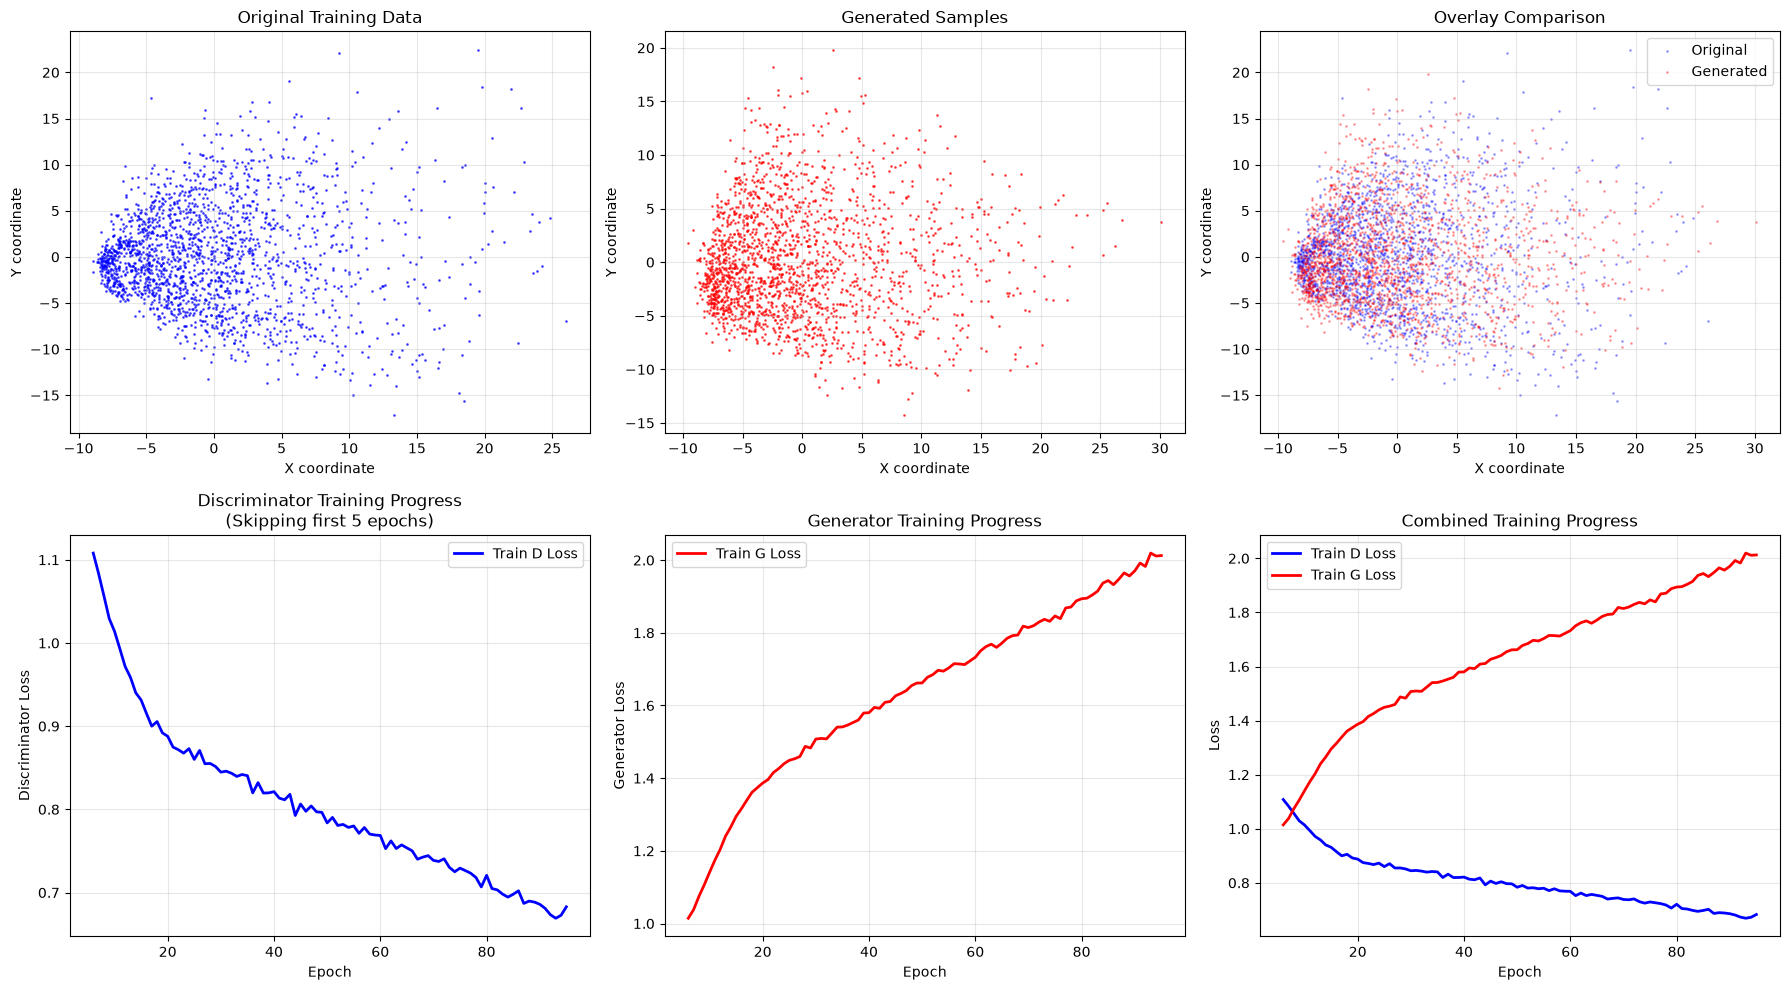

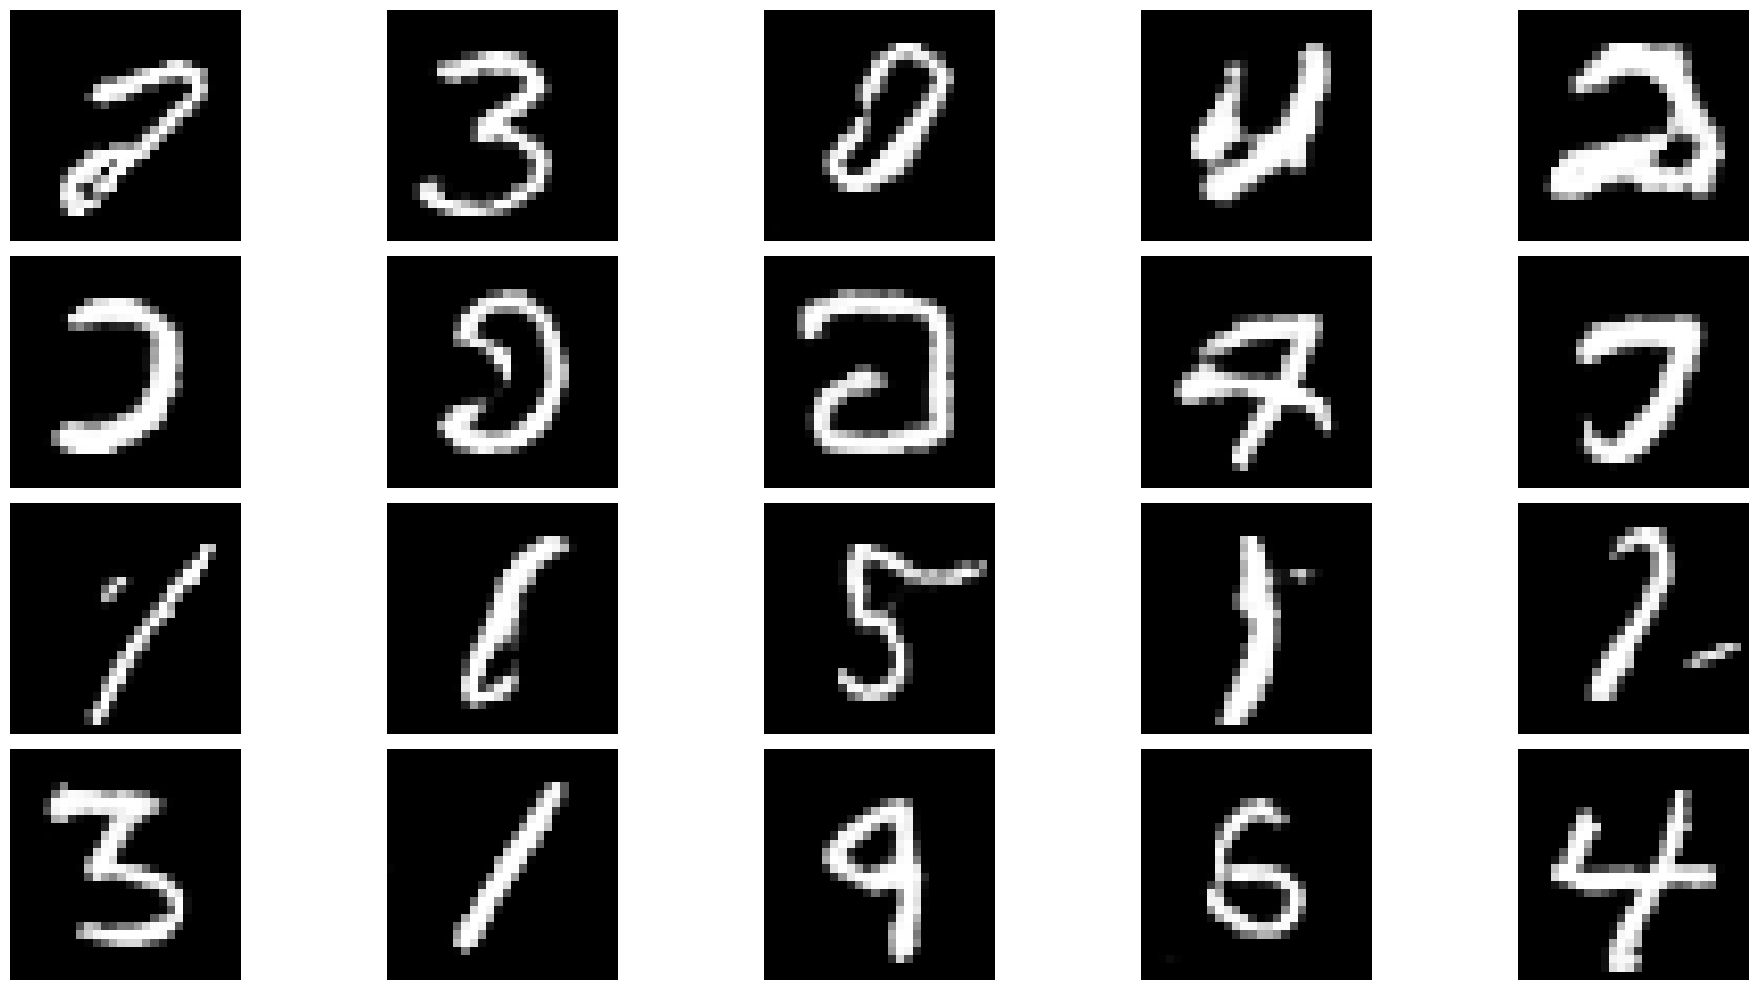

📈 Epoch 95 Summary:
   Train D Loss: 0.6829, Val D Loss: 1.0240
   Train G Loss: 2.0126, Val G Loss: 1.5886

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.655686	G_loss: 1.794189
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.624158	G_loss: 2.001394
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.597827	G_loss: 2.025129
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.517789	G_loss: 1.463787
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.603696	G_loss: 2.041498
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.709210	G_loss: 2.467769
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.807340	G_loss: 2.660456
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.739291	G_loss: 1.163837
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.653711	G_loss: 2.586366
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.765064	G_loss: 1.700650
====> Epoch: 96 Train D_loss: 0.6590, Train G_loss: 2.0093
====> Epoch: 96 Val D_loss: 1.2675, Val G_loss: 2.3005
📈 Epoch 96 Summary:
   Train D Loss: 0.6590, Val D Loss: 1.2675
   Train G Loss: 2.0093

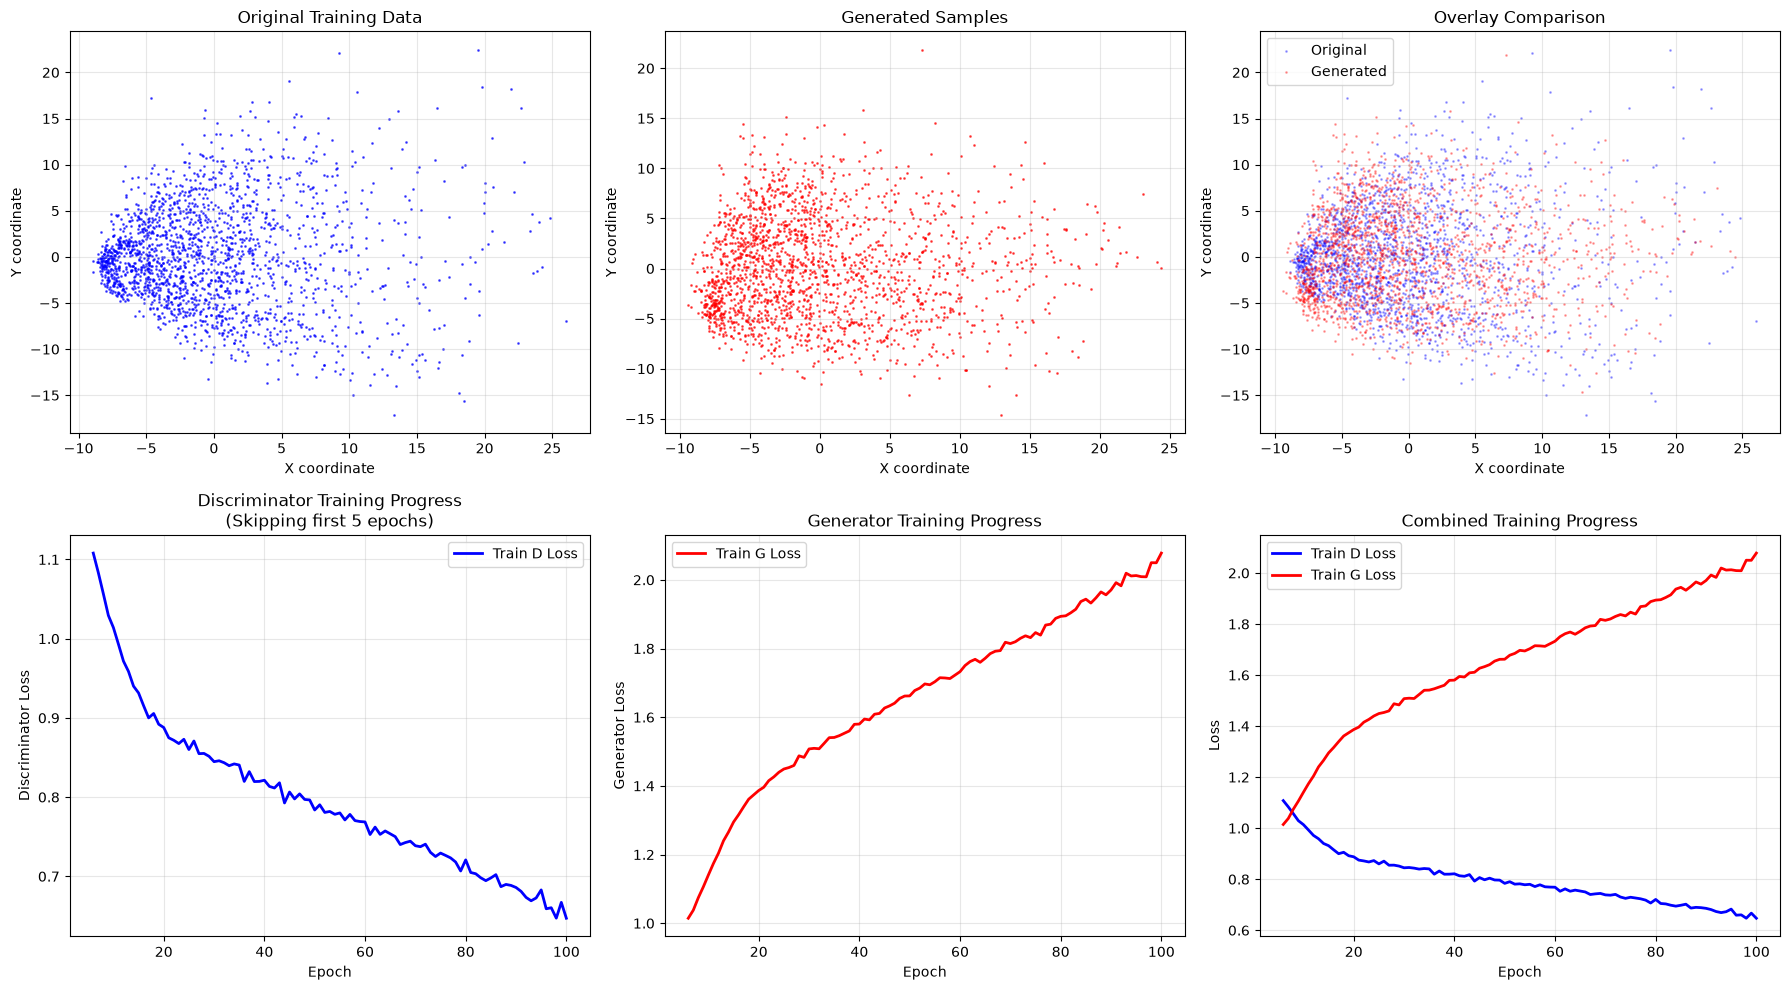

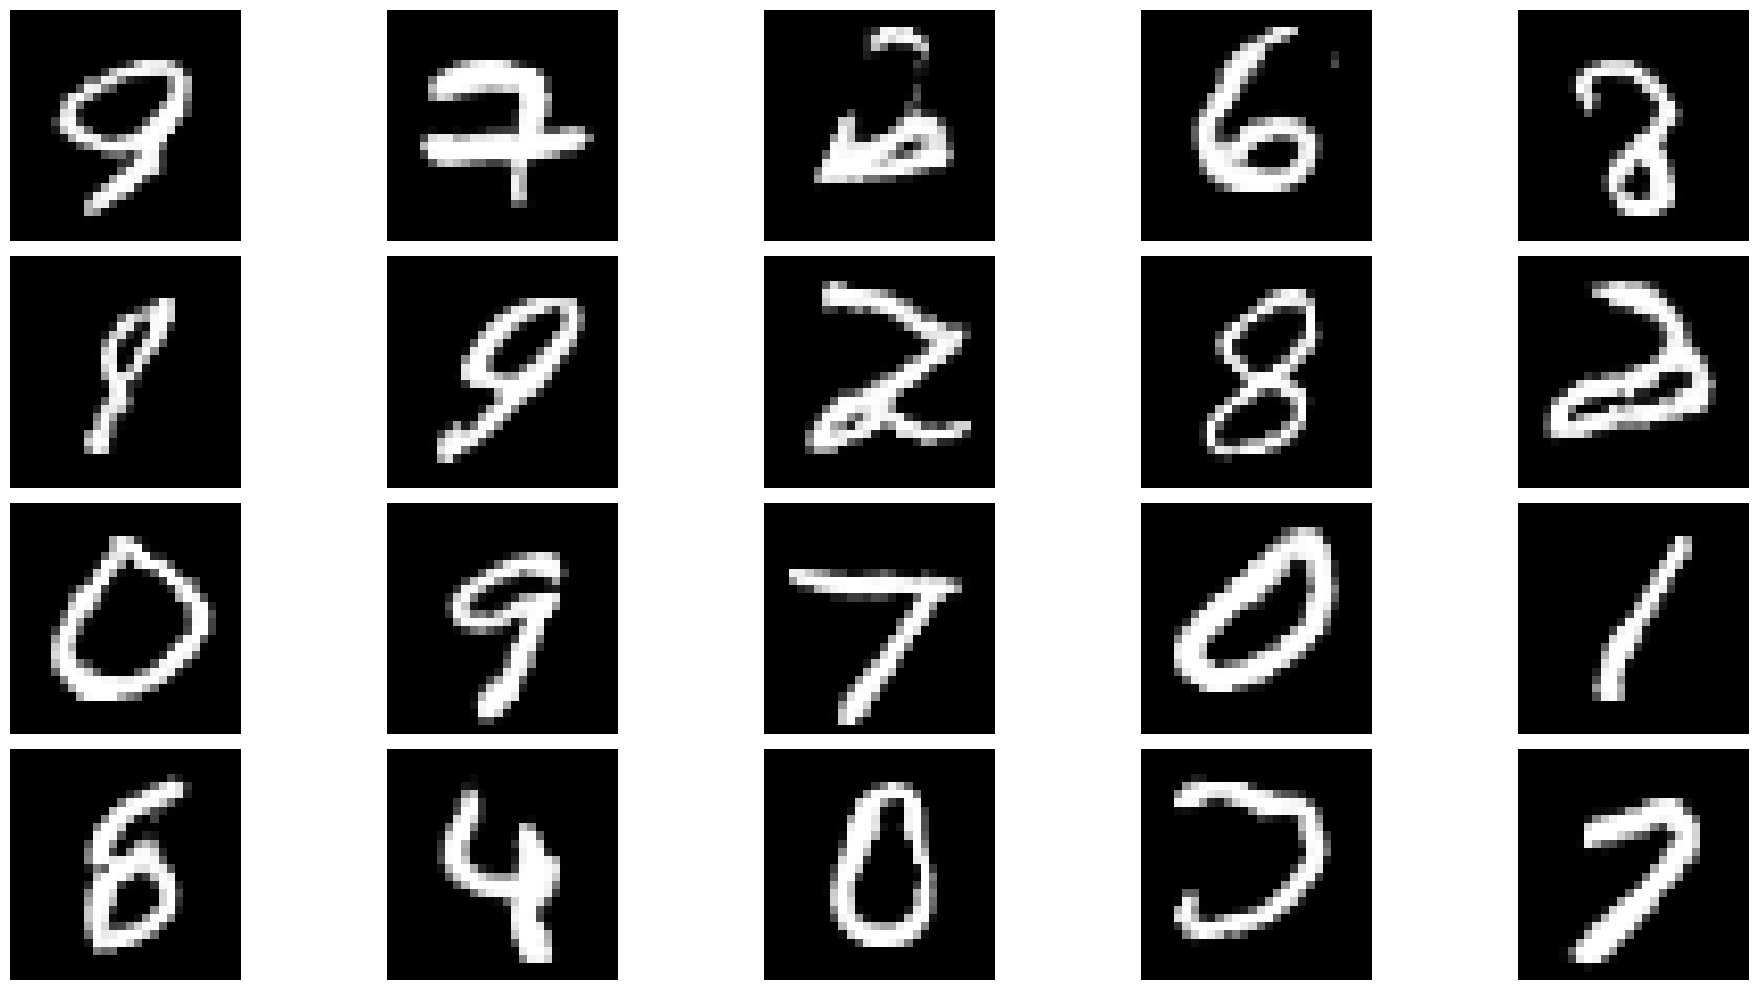

📈 Epoch 100 Summary:
   Train D Loss: 0.6471, Val D Loss: 1.5116
   Train G Loss: 2.0780, Val G Loss: 2.8174

🎉 Training completed!

🎨 Final comprehensive visualization:


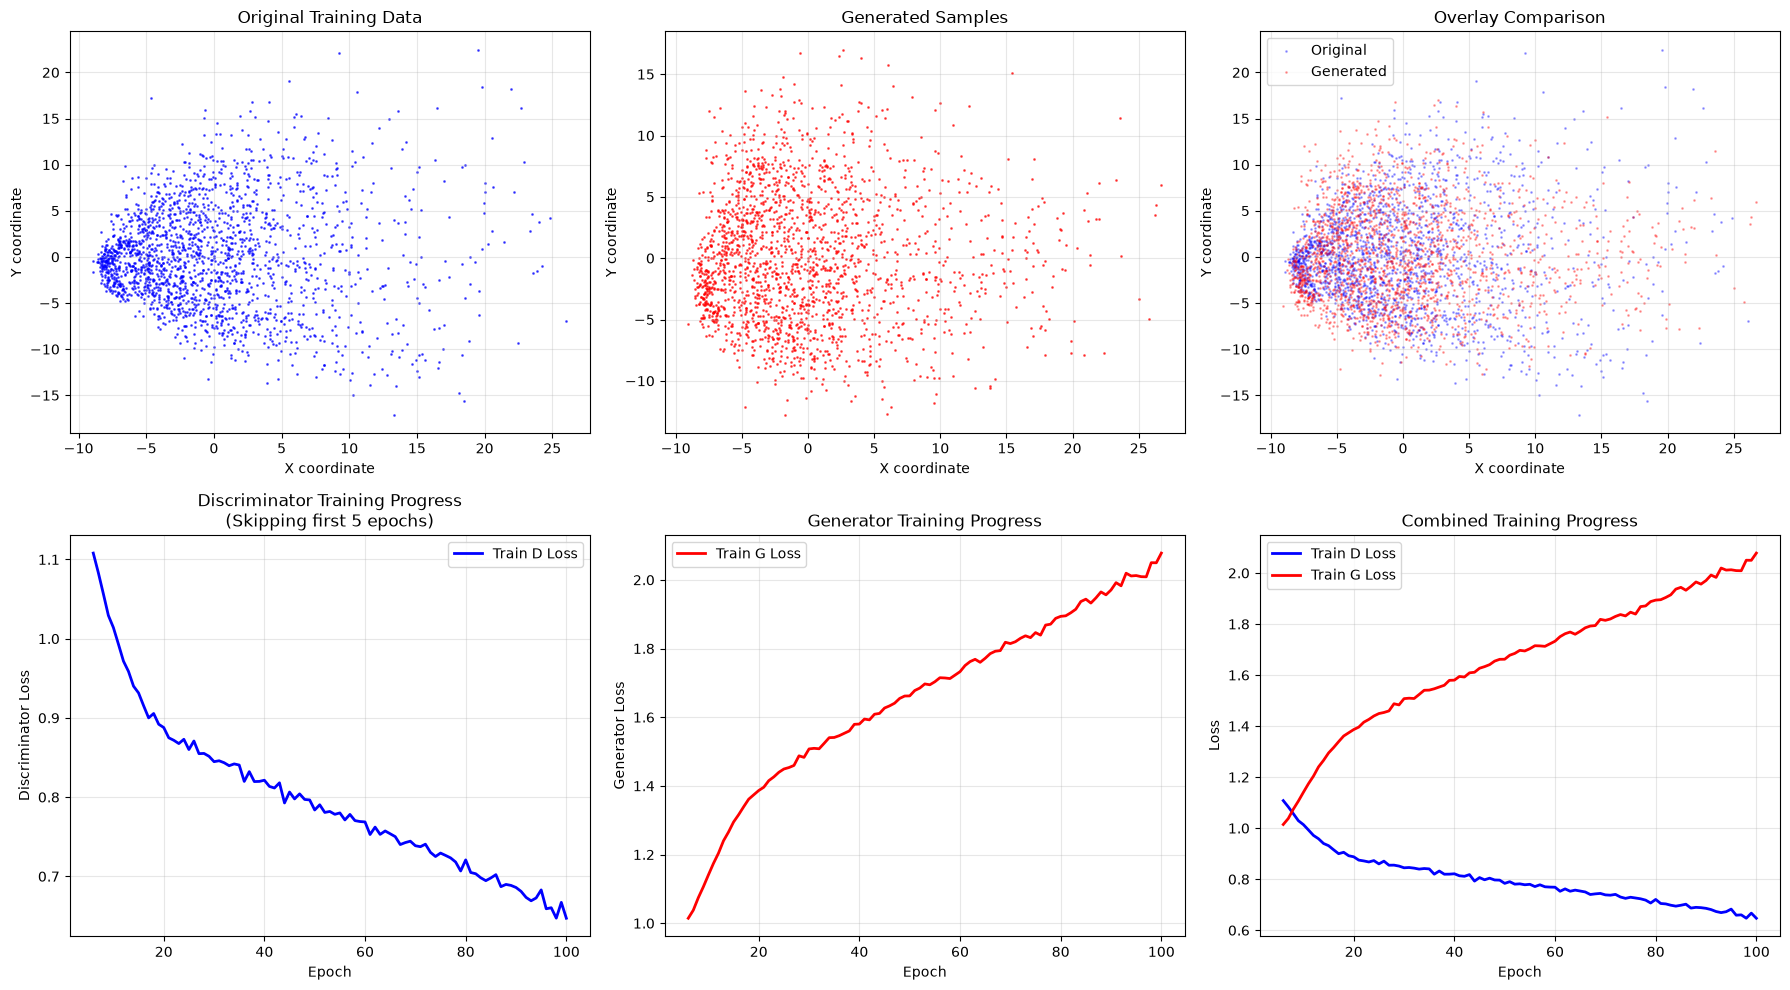

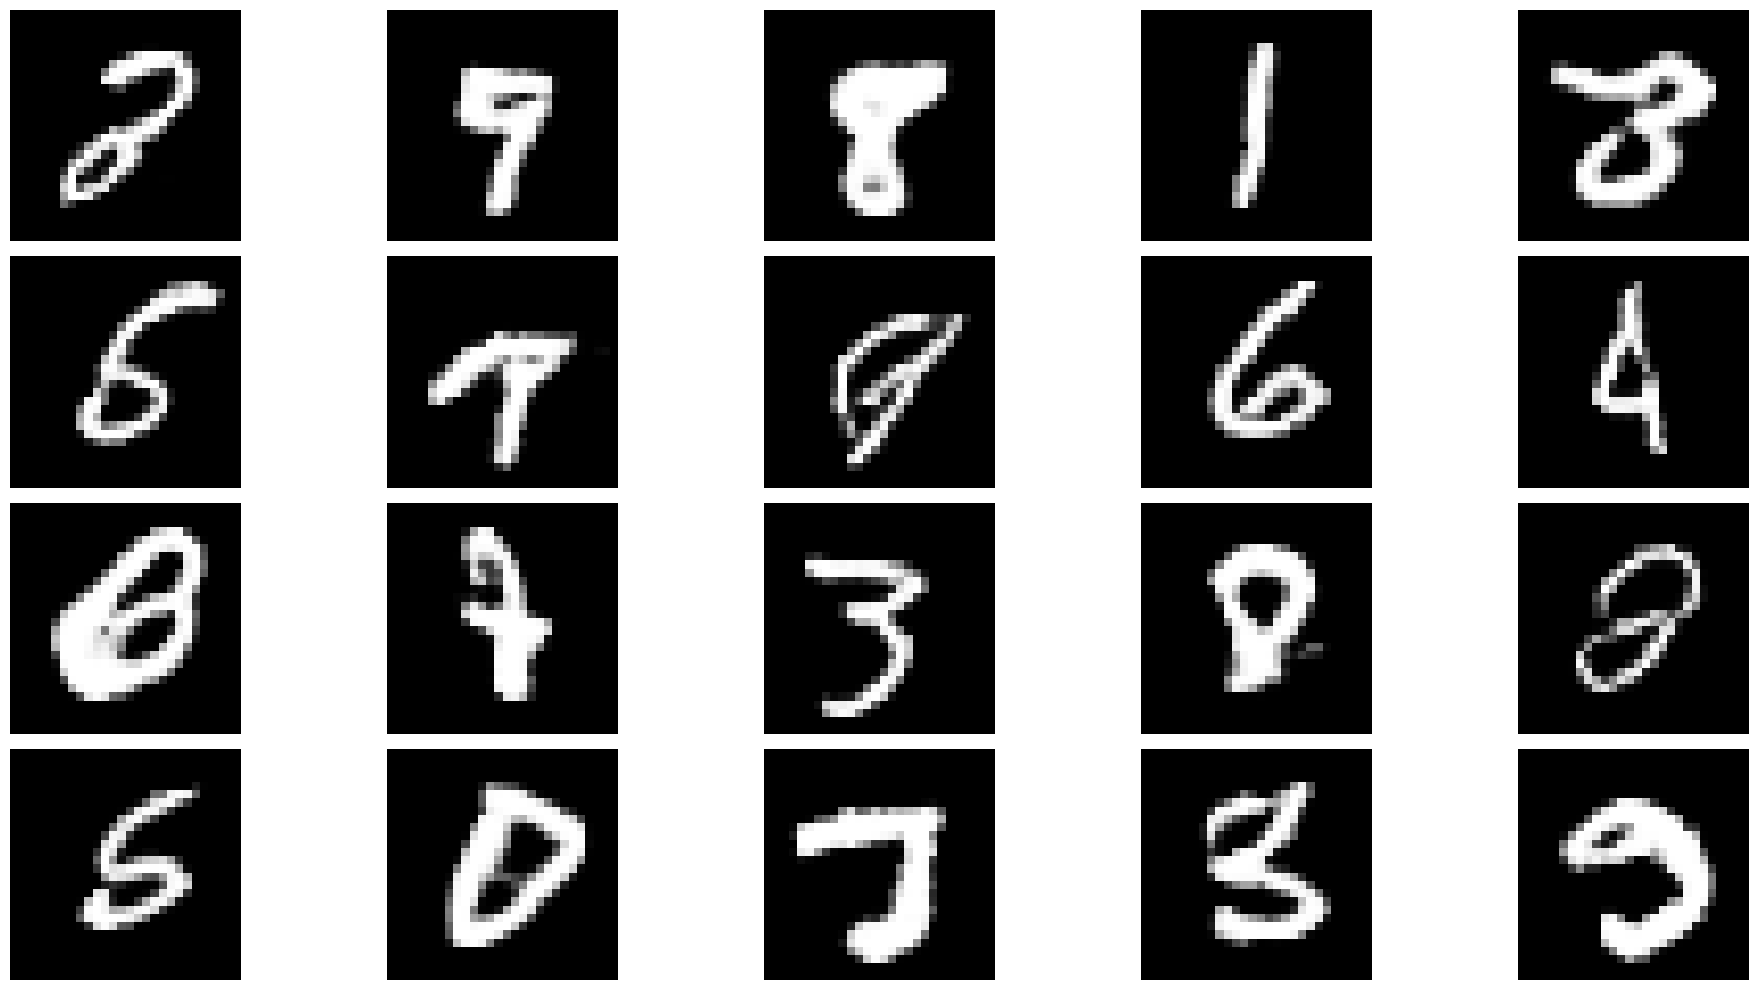

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


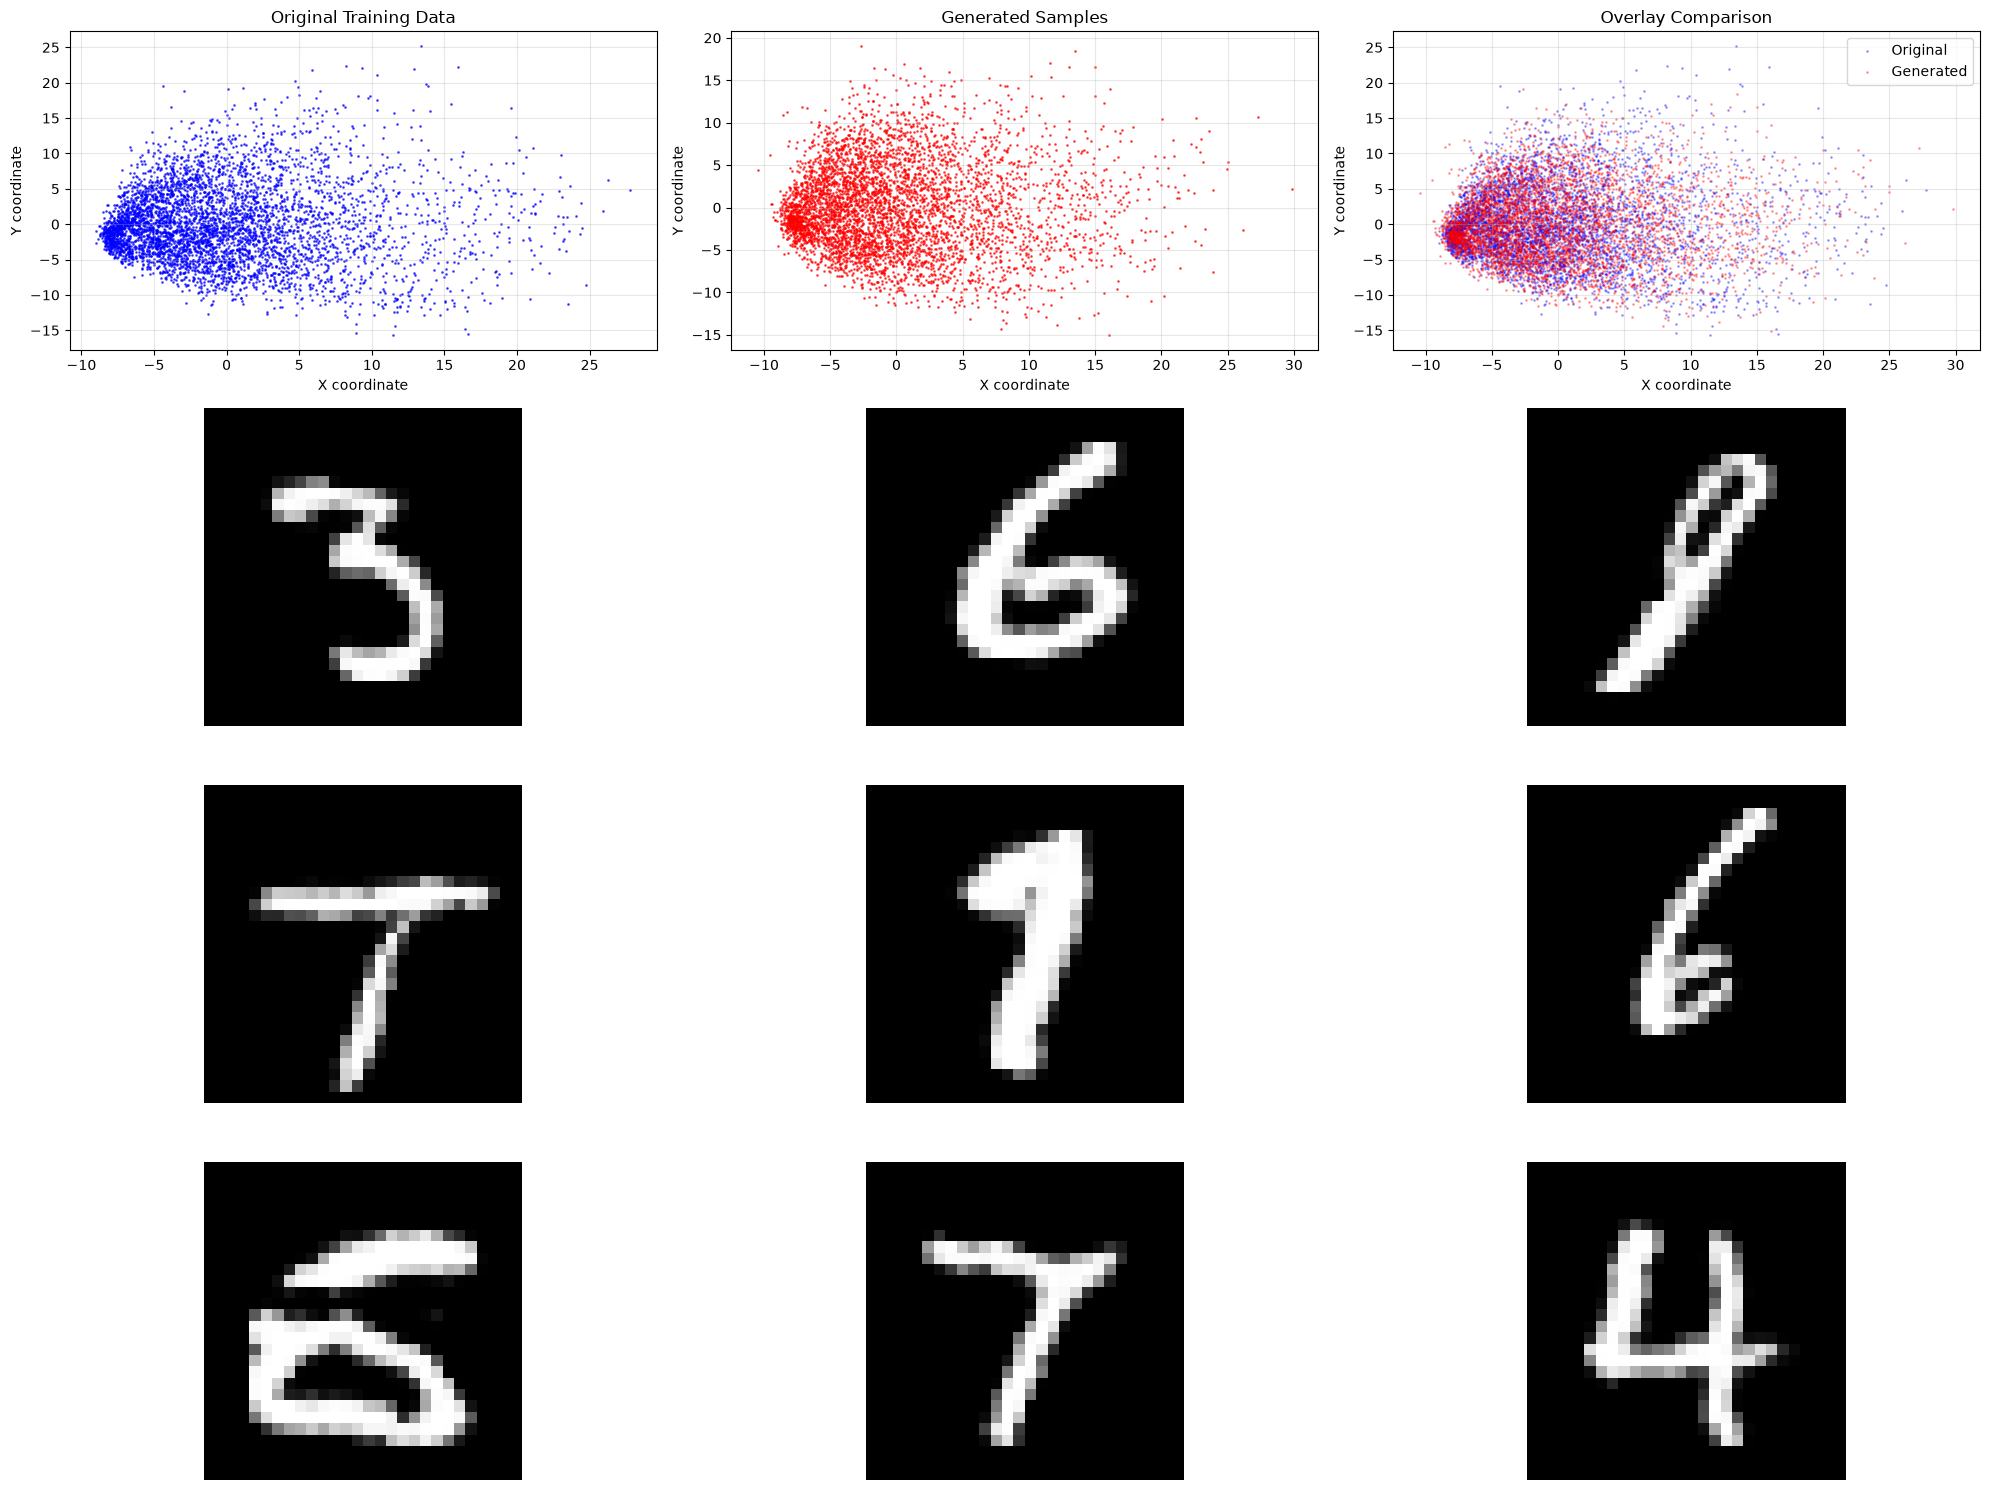

Real data confidence: 0.410
Fake data confidence: 0.120


In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = train_data.data[:100].unsqueeze(1).to(device).float() / 255.0
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
